# Skup podataka: *House Prices - Advanced Regression Techniques* sa *Kaggle* platforme

https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques

https://www.kaggle.com/code/solegalli/predict-house-price-with-feature-engine

# Učitavanje i priprema podataka

Pre svega ćemo skup podataka podeliti na trening, validacioni i test skup u odnosu 80:10:10.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/ML vežbe/dataset_houseprices/train.csv')

# Separate the features and the target variable
X = df.drop('SalePrice', axis=1)  # Assuming 'SalePrice' is the target variable
y = df['SalePrice']

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

Proveravamo da li labele u trening, validacionom i test skupu imaju sličnu distribuciju.

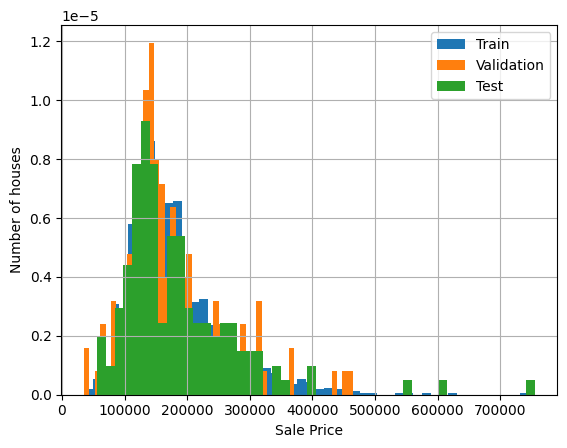

In [ ]:
import matplotlib.pyplot as plt

y_train.hist(bins=50, density=True)
y_val.hist(bins=50, density=True)
y_test.hist(bins=50, density=True)

plt.legend(["Train", "Validation", "Test"])
plt.ylabel('Number of houses')
plt.xlabel('Sale Price')
plt.show()

Distribucije su dovoljno slične. Međutim, vidimo da je labela *scewed* na levu stranu i da ima nekoliko outlier-a (nekretnine velike cene). Verovatno će logaritamska transformacija labele pomoći da dobijemo bolje rezultate.

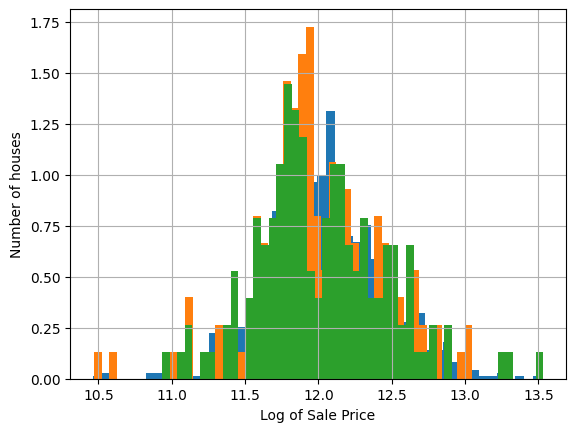

In [ ]:
import numpy as np

np.log(y_train).hist(bins=50, density=True)
np.log(y_val).hist(bins=50, density=True)
np.log(y_test).hist(bins=50, density=True)

plt.ylabel('Number of houses')
plt.xlabel('Log of Sale Price')
plt.show()

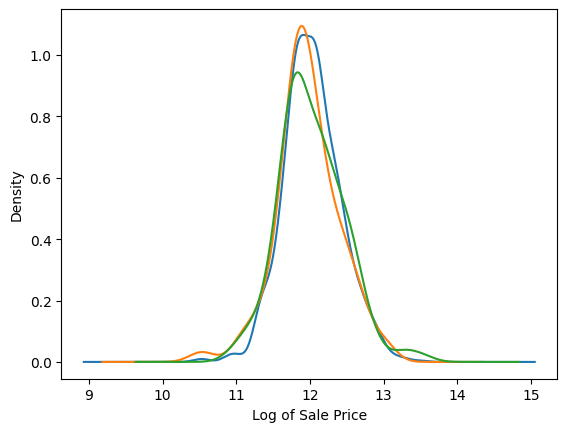

In [ ]:
np.log(y_train).plot.density()
np.log(y_val).plot.density()
np.log(y_test).plot.density()

plt.xlabel('Log of Sale Price')
plt.show()

Nakon logaritmovanja, distribucije labela u sva tri skupa izgledaju pribložnije normalnoj distribuciji. Zato ćemo primeniti ovu transformaciju:

In [ ]:
y_train = np.log(y_train)
y_val = np.log(y_val)
y_test = np.log(y_test)

# Eksplorativna analiza podataka
https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

Numeričke kolone dosta variraju u vrednostima - biće potrebna normalizacija.

In [ ]:
numerical_summary = X_train.describe()
print(numerical_summary)

                Id   MSSubClass  LotFrontage        LotArea  OverallQual  \
count  1168.000000  1168.000000   951.000000    1168.000000  1168.000000   
mean    730.904966    56.849315    70.343849   10689.642123     6.121575   
std     425.369088    42.531862    24.897021   10759.366198     1.367619   
min       1.000000    20.000000    21.000000    1300.000000     1.000000   
25%     360.750000    20.000000    59.000000    7587.250000     5.000000   
50%     732.500000    50.000000    70.000000    9600.000000     6.000000   
75%    1101.750000    70.000000    80.000000   11700.000000     7.000000   
max    1460.000000   190.000000   313.000000  215245.000000    10.000000   

       OverallCond    YearBuilt  YearRemodAdd   MasVnrArea   BsmtFinSF1  ...  \
count  1168.000000  1168.000000   1168.000000  1162.000000  1168.000000  ...   
mean      5.584760  1970.965753   1984.897260   103.771945   446.023973  ...   
std       1.116062    30.675495     20.733955   173.032238   459.070977  ..

Ispitivanje vrednosti kategoričkih kolona. Naivna primena 1-hot encodinga bi dovela do jako velikog broja obeležja:

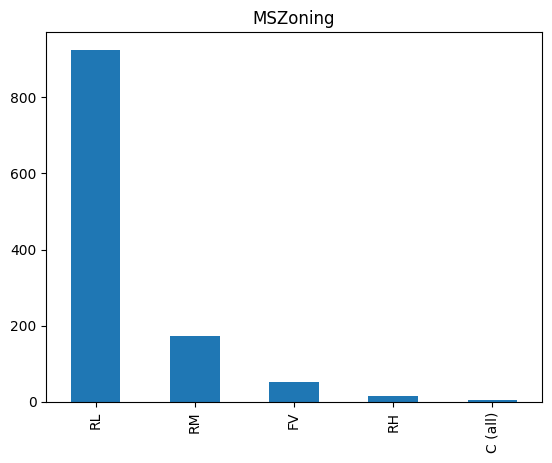

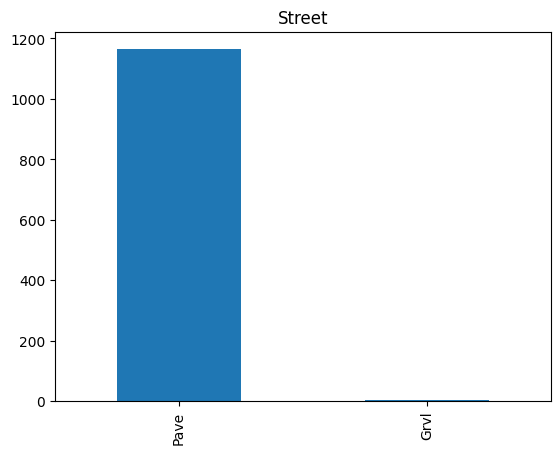

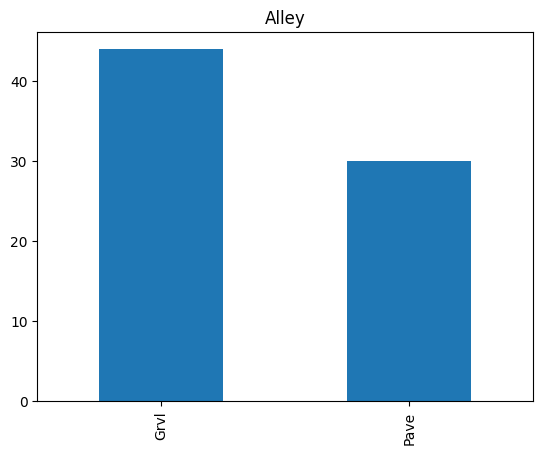

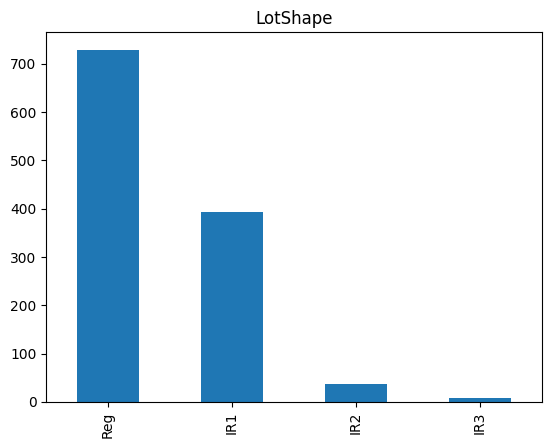

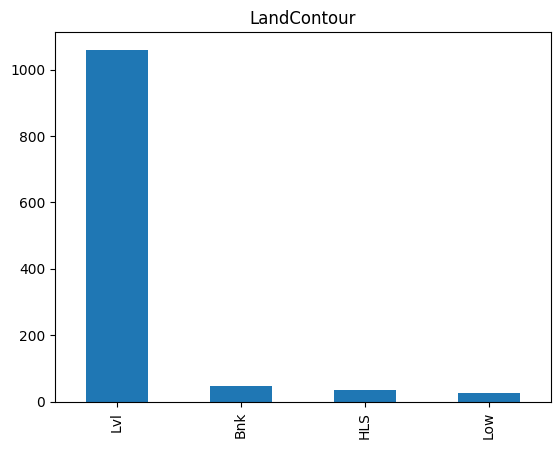

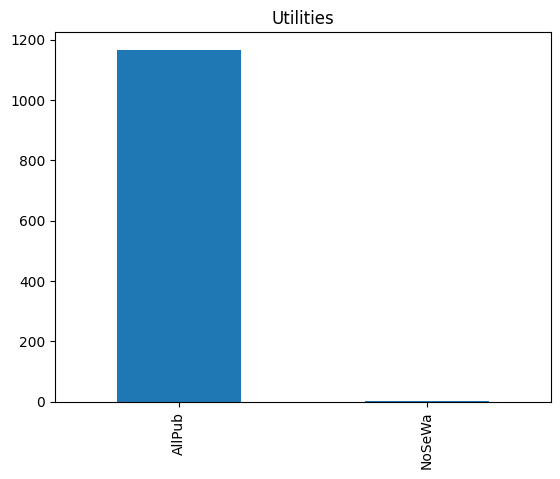

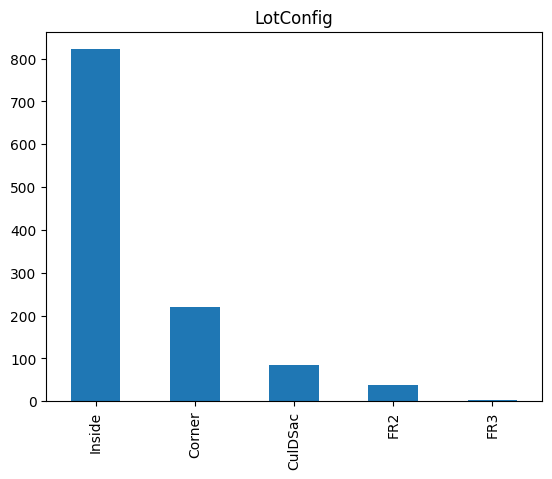

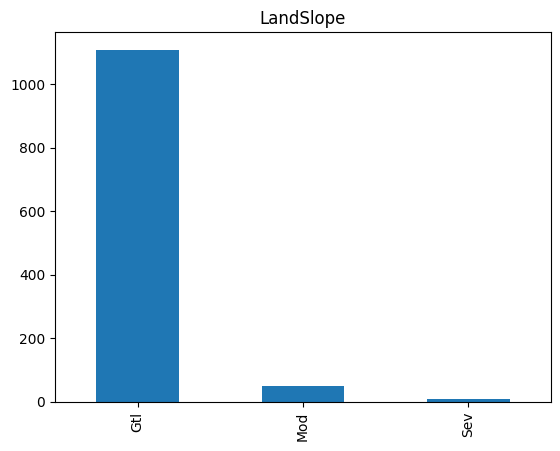

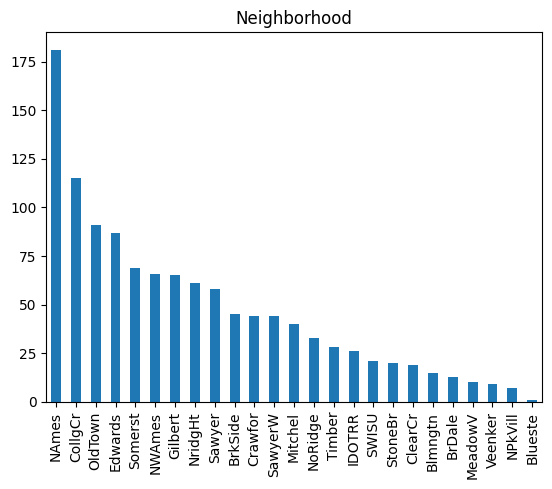

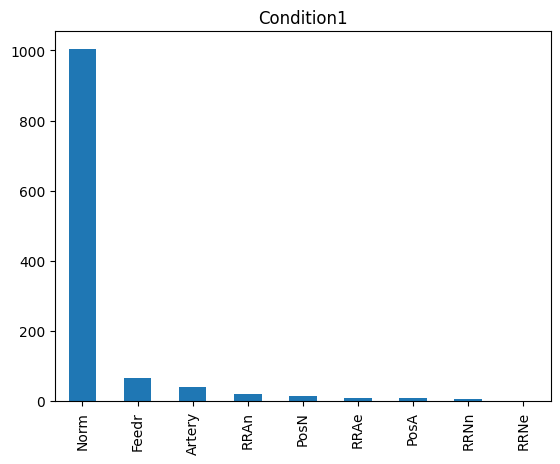

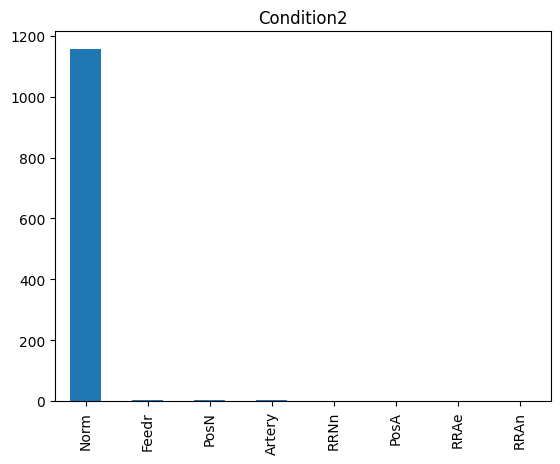

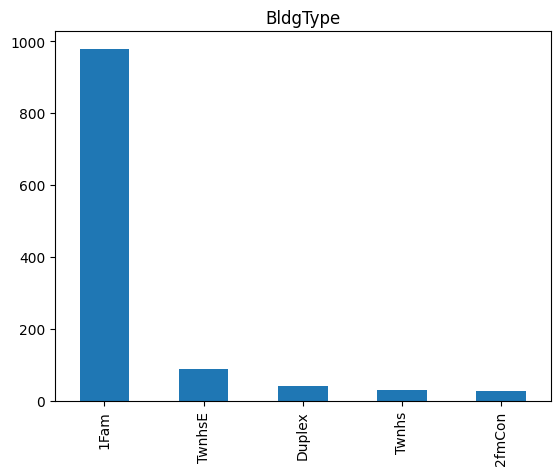

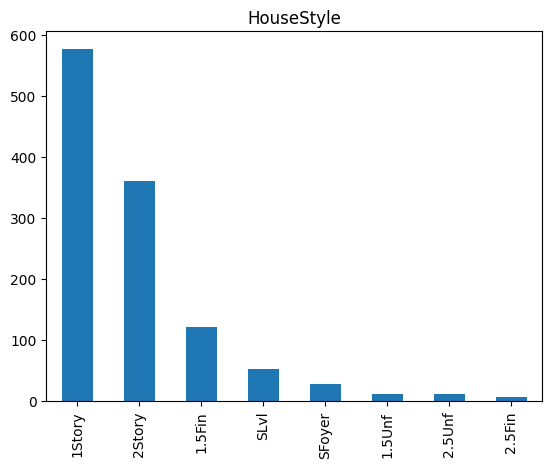

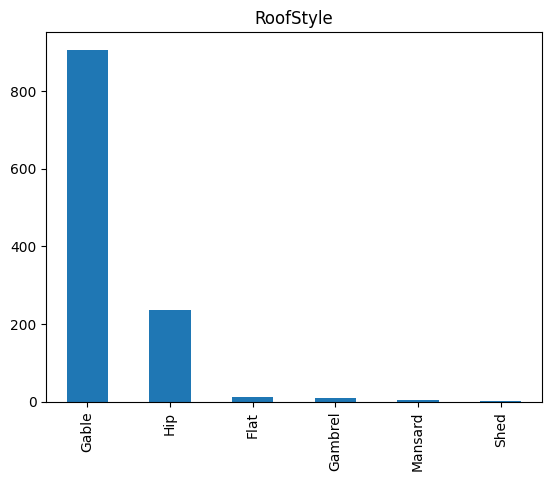

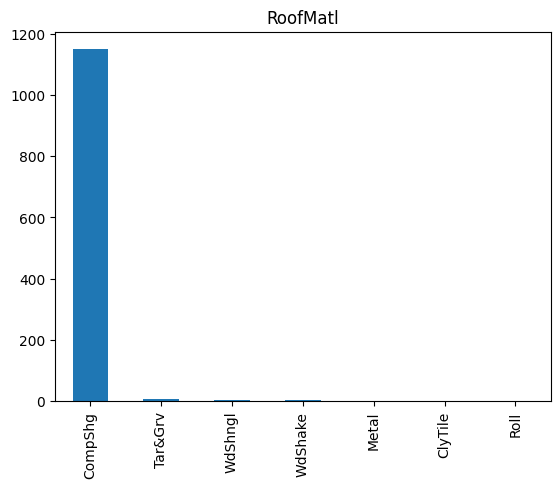

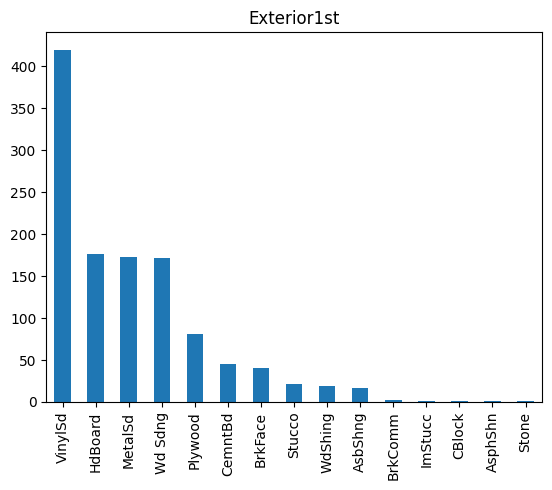

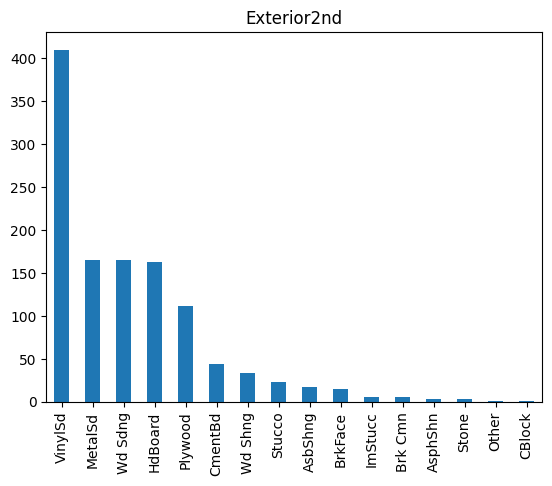

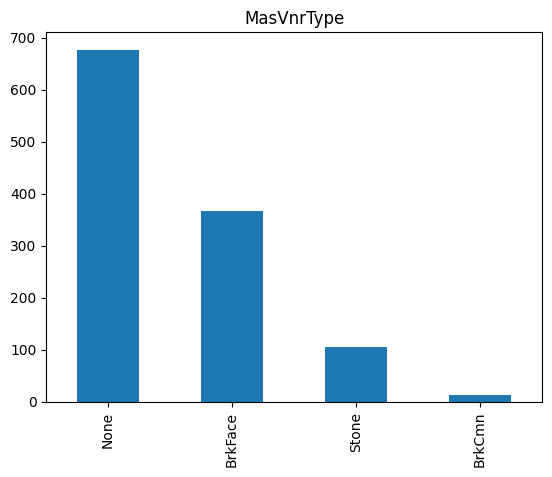

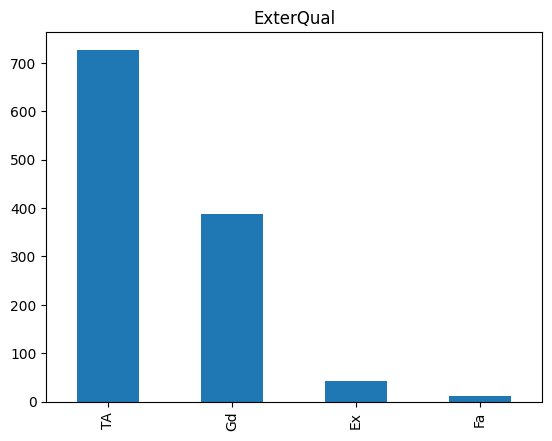

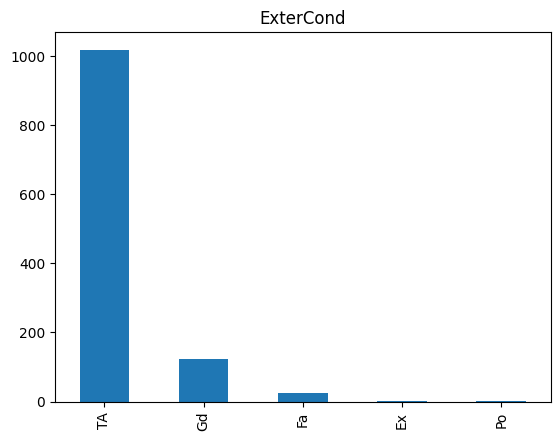

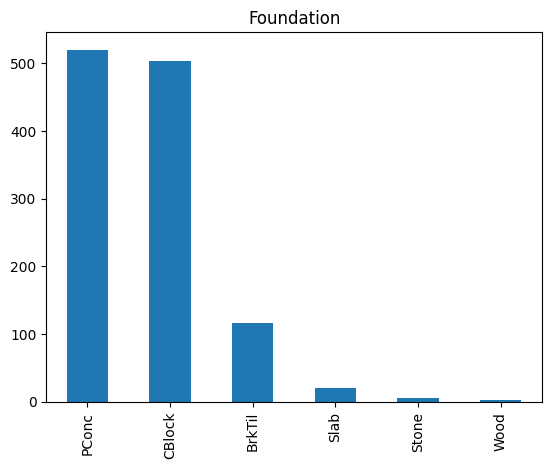

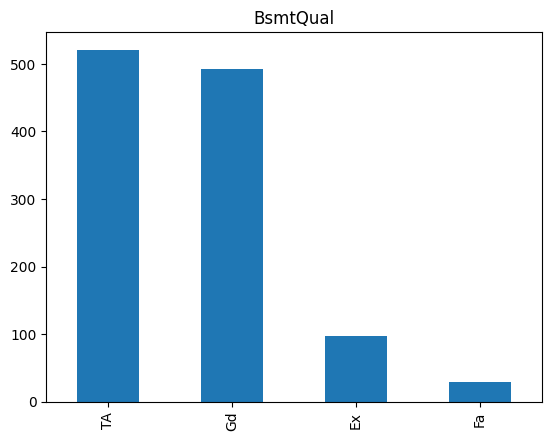

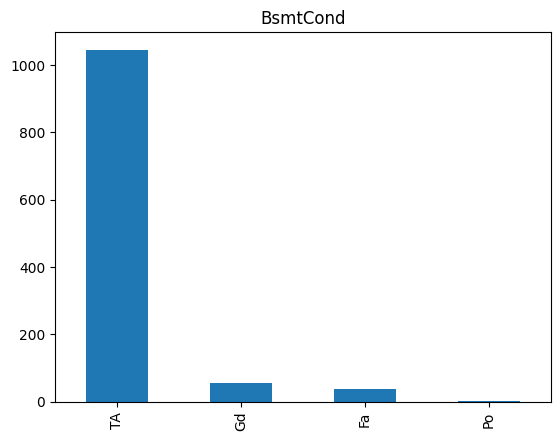

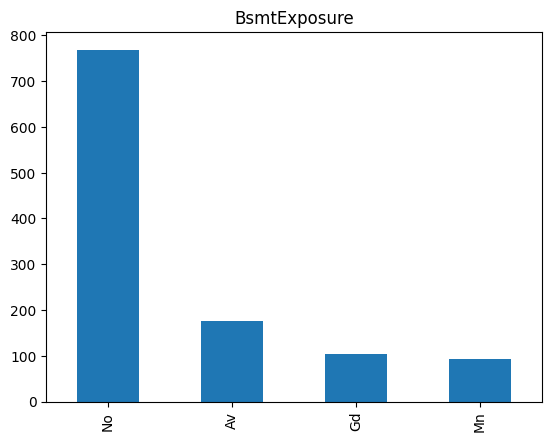

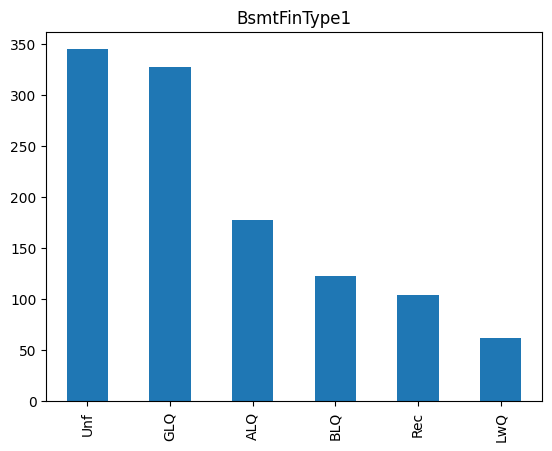

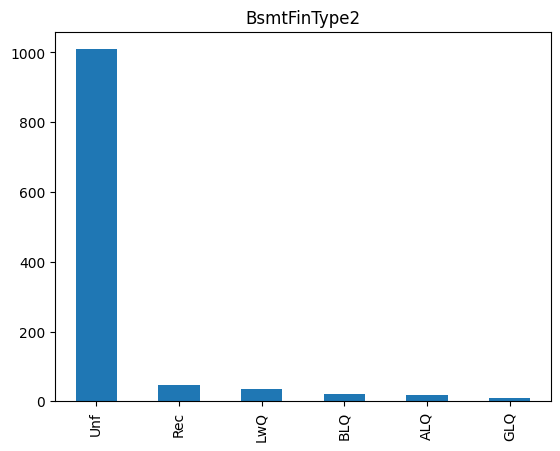

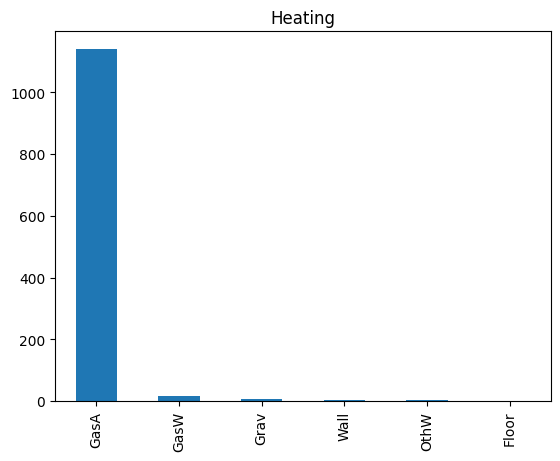

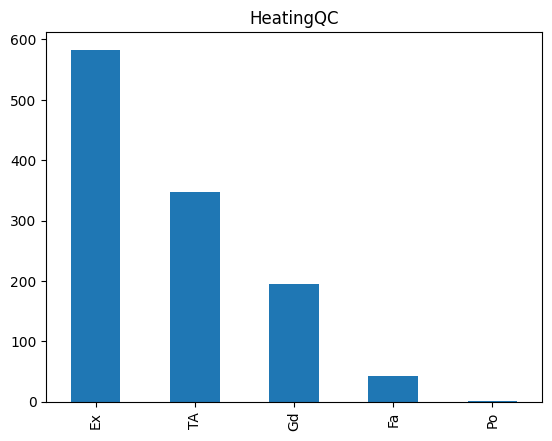

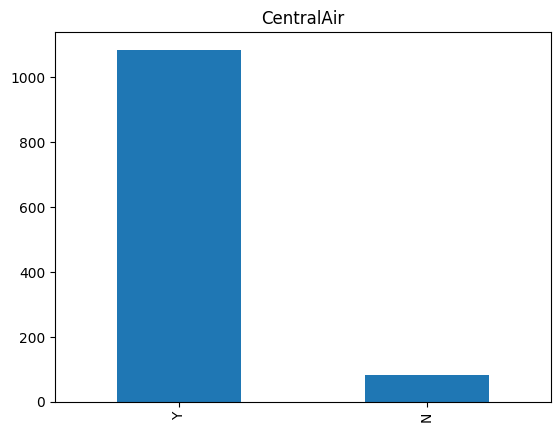

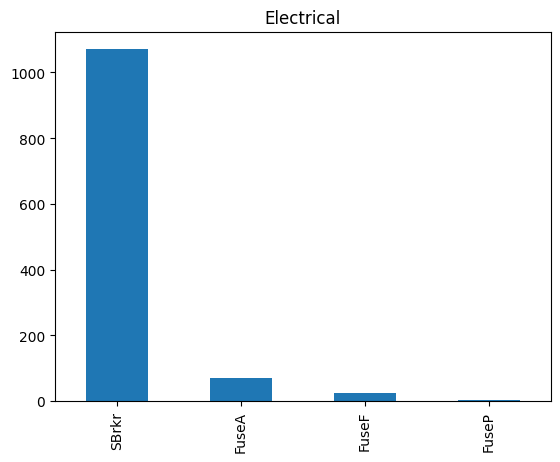

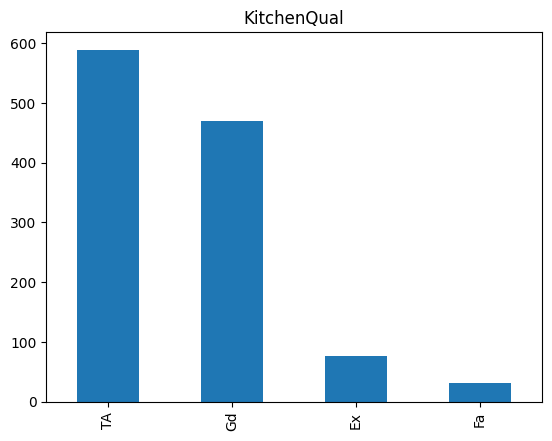

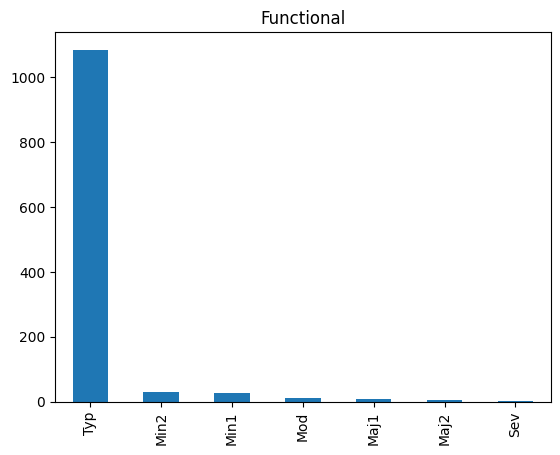

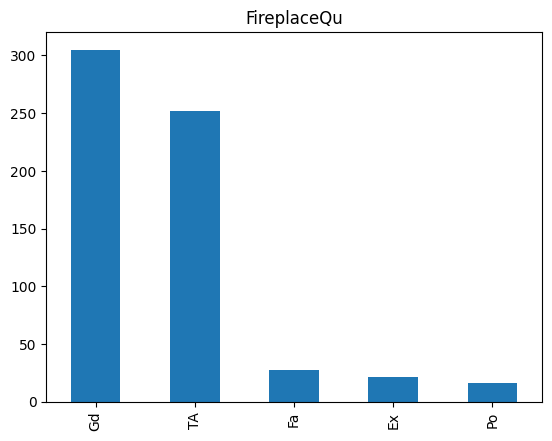

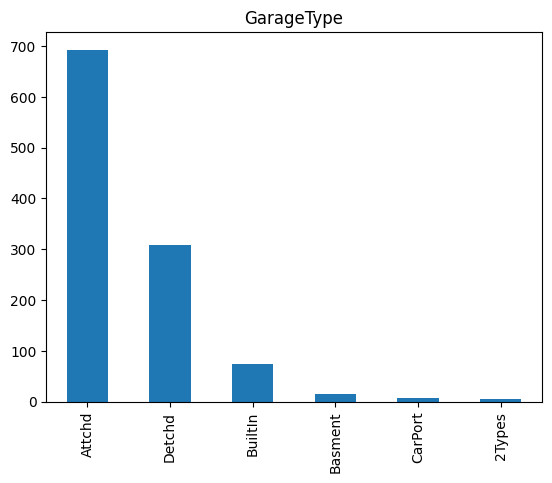

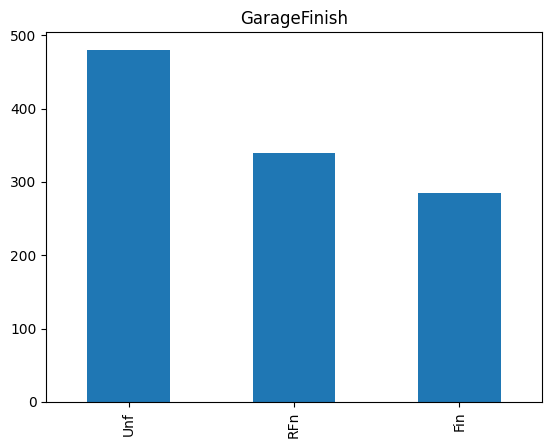

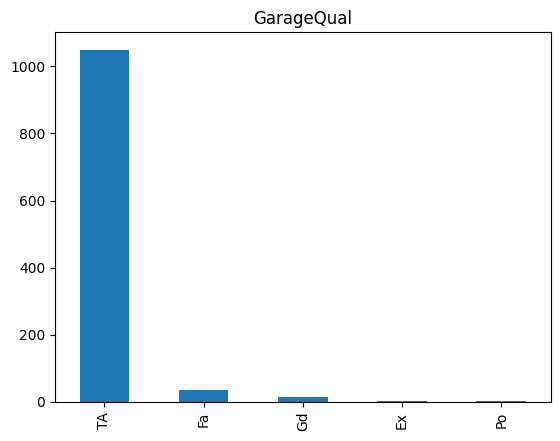

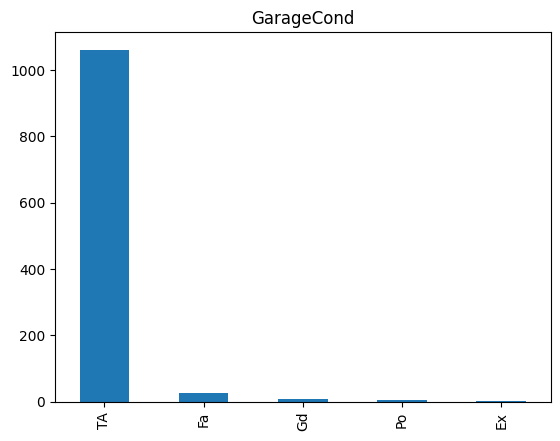

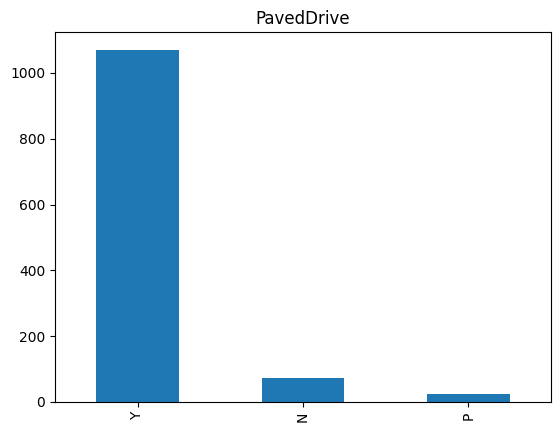

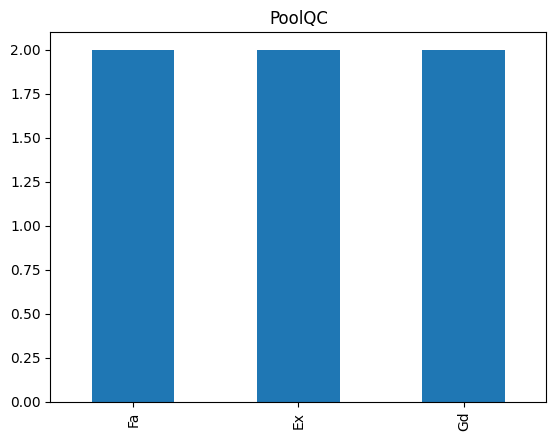

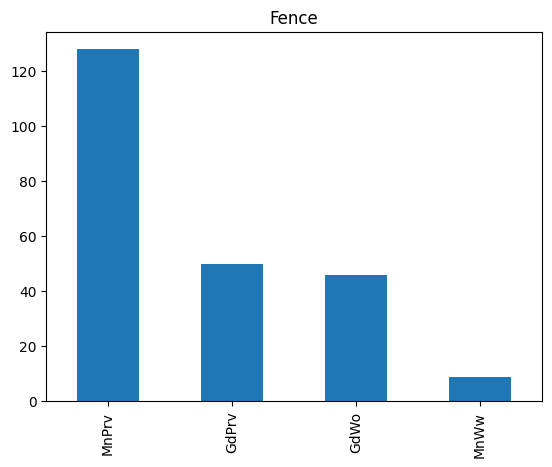

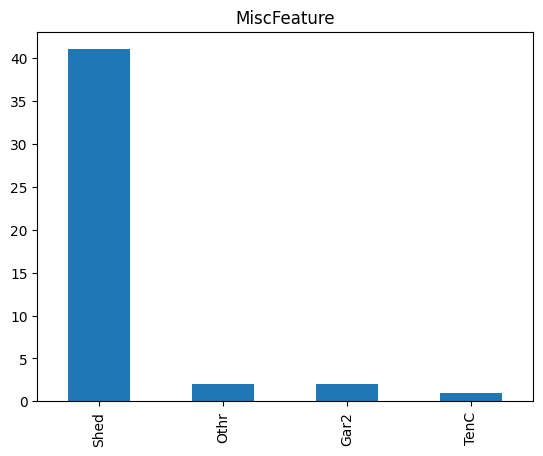

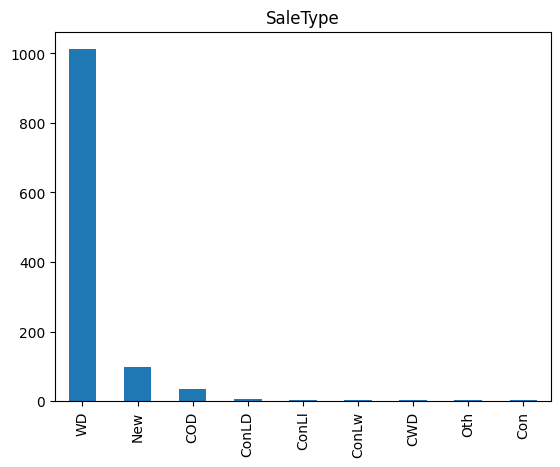

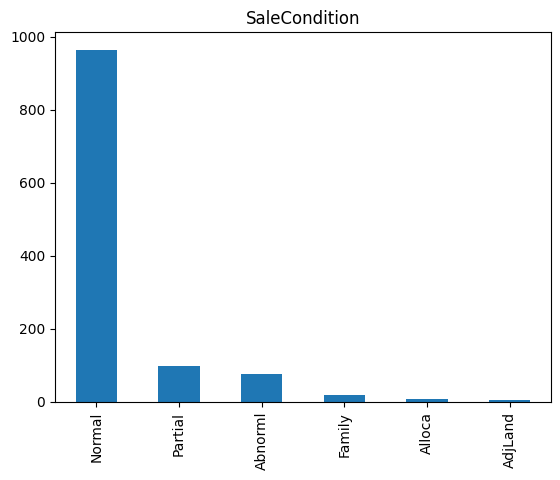

In [ ]:
for col in X_train.select_dtypes(include=['object', 'category']).columns:
    X_train[col].value_counts().plot(kind='bar')
    plt.title(col)
    plt.show()

## Feature engineering, bazirano na domenskom znanju

In [ ]:
X_train['HasPool'] = np.where(X_train['PoolArea']>0, 1, 0)
X_val['HasPool'] = np.where(X_test['PoolArea']>0, 1, 0)
X_test['HasPool'] = np.where(X_test['PoolArea']>0, 1, 0)

X_train['HasAlley'] = np.where(X_train['Alley'].isnull(), 0, 1)
X_val['HasAlley'] = np.where(X_val['Alley'].isnull(), 0, 1)
X_test['HasAlley'] = np.where(X_test['Alley'].isnull(), 0, 1)

Funkcija koja poredi medijan cene nekretnine u svakoj kategoriji (korisno za eksplorativnu analizu):

In [ ]:
import seaborn as sns

def plot_median_price(variables, limits):

    tmp = pd.concat([X_train[variables].reset_index(drop=True), y_train.reset_index(drop=True)], axis=1)

    # plot mean sale price per null value or otherwise
    g = sns.PairGrid(tmp, x_vars=variables, y_vars=['SalePrice'])
    g.map(sns.barplot)
    plt.ylim(limits)
    plt.show()

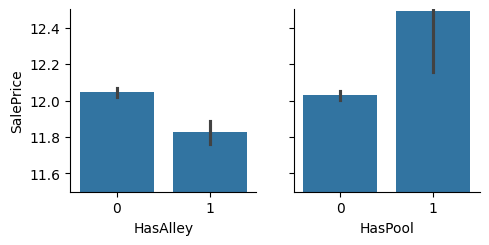

In [ ]:
plot_median_price(['HasAlley', 'HasPool'], (11.5,12.5))

Vidimo da se medijan cena nekretnina koja imaju Alley/Pool razlikuje od medijana cena nekretnina koje nemaju. Razlika nije velika, te je teško reći koliko su ova obeležja korisna (međutim, treba imati na umu da je y logaritmovano)

Iz opisa podataka:
* Condition1: Proximity to main road or railroad
* Condition2: Proximity to main road or railroad (if a second is present)
Kreiraćemo jednu varijablu koja agregira ove dve varijable (ako je kuća blizu više od 1 pogodnosti)


In [ ]:
X_train['Condition_total'] = np.where(X_train['Condition2'] == X_train['Condition1'], 0, 1)
X_val['Condition_total'] = np.where(X_val['Condition2'] == X_val['Condition1'], 0, 1)
X_test['Condition_total'] = np.where(X_test['Condition2'] == X_test['Condition1'], 0, 1)

X_train['Condition_total'].value_counts()

0    1009
1     159
Name: Condition_total, dtype: int64

Oko 10 % kuća su blizu 2 različite pogodnosti.

In [ ]:
# Exterior 1s and 2nd indicate the Exterior material covering on house:
# Create a variable that aggregates both, like we did for contition

X_train['Exterior_total'] = np.where(X_train['Exterior1st'] == X_train['Exterior2nd'], 0, 1)
X_val['Exterior_total'] = np.where(X_val['Exterior1st'] == X_val['Exterior2nd'], 0, 1)
X_test['Exterior_total'] = np.where(X_test['Exterior1st'] == X_test['Exterior2nd'], 0, 1)

# inspect the variable
X_train['Exterior_total'].value_counts()

0    993
1    175
Name: Exterior_total, dtype: int64

Roughly 20% of the houses ashow 2 materials in the exterior.

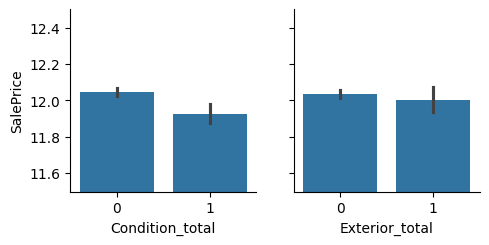

In [ ]:
plot_median_price(['Condition_total', 'Exterior_total'], (11.5,12.5))

Ponovo, nejasno je da li ove nove varijable donose vrednost - razlika u cenama nekretnine u različitim kategorijama izgleda minimalna.

## Kategoričke varijable

In [ ]:
categorical = [var for var in df.columns if df[var].dtype == 'O']

# MSSubClass je takođe kategorička po definiciji, iako sadrži numeričke vrednosti
categorical = categorical + ['MSSubClass']

# number of categorical variables
len(categorical)

44

Sve ove varijable ćemo namestiti da budu kategoričke:

In [ ]:
X_train[categorical] = X_train[categorical].astype('O')
X_test[categorical] = X_test[categorical].astype('O')
X_val[categorical] = X_val[categorical].astype('O')

### Nedostajuće vrednosti u kategoričkim varijablama

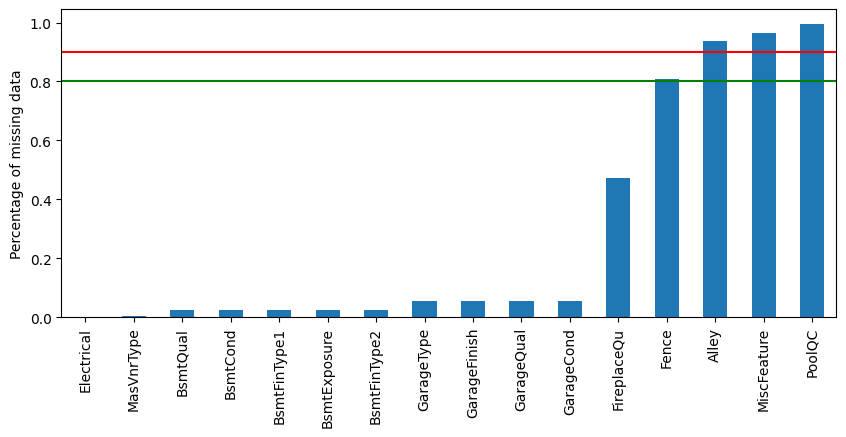

In [ ]:
null_cat = {var: df[var].isnull().mean() for var in categorical if df[var].isnull().mean()>0}

# plot
pd.Series(null_cat).sort_values().plot.bar(figsize=(10,4))
plt.ylabel('Percentage of missing data')
plt.axhline(y = 0.90, color = 'r', linestyle = '-')
plt.axhline(y = 0.80, color = 'g', linestyle = '-')

plt.show()

Ima nekoliko varijabli kojima nedostaje malo vrednosti. Ima i par varijabli kojima nedostaje dosta vrednosti, gde čak 3 varijable imaju preko 90% nedostajućih vrednosti (bar prelazi crvenu liniju).

Ispitaćemo da li su ove kolone sa nedostajućim vrednostima donekle korisne za predikciju cene nekretnine.

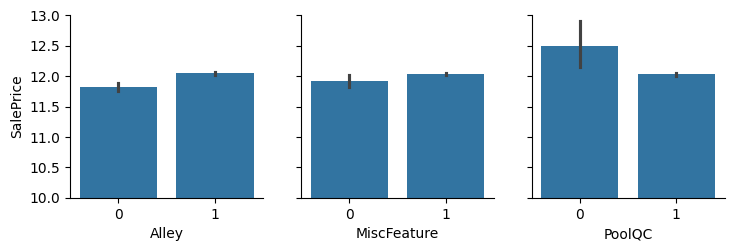

In [ ]:
tmp = pd.concat([X_train[['Alley', 'MiscFeature', 'PoolQC']].reset_index(drop=True), y_train.reset_index(drop=True)], axis=1)

# zamena nedostajućih vrednosti sa 1 (0 ako ne nedostaje vrednost)
for var in ['Alley', 'MiscFeature', 'PoolQC']:
    tmp[var] = np.where(tmp[var].isnull(), 1, 0)


# iscrtavamo srednju vrednost cene nekretnine za instance koje imaju 1 (instance sa nedostajućim vrednostima) naspram onih koje imaju 0 (instance bez nedostajućih vrednosti)
g = sns.PairGrid(tmp, x_vars=['Alley', 'MiscFeature', 'PoolQC'], y_vars=['SalePrice'])
g.map(sns.barplot)
plt.ylim(10,13)
plt.show()

Razlike u cenama nekretnina ne deluju velike. Uklonićemo ih (pogotovo s obzirom na to da su alley i pool već obuhvaćeni prethodno napravljenim obeležjima).

In [ ]:
# !pip install feature_engine

In [ ]:
from feature_engine import selection as sel

drop_features = sel.DropFeatures(features_to_drop = ['Alley', 'MiscFeature', 'PoolQC'])

X_train = drop_features.fit_transform(X_train)
X_val = drop_features.transform(X_val)
X_test = drop_features.transform(X_test)

X_train.shape, X_val.shape, X_test.shape

((1168, 81), (146, 81), (146, 81))

Za ostale nedostajuće vrednosti, uklonićemo instance sa nedostajućim vrednostima.

In [ ]:
from feature_engine import imputation as imp

cat_imputer = imp.CategoricalImputer(return_object=True)

cat_imputer.fit(X_train)

# the variables to impute are stored in the variables attribute
cat_imputer.variables_[0:10]

['MSSubClass',
 'MSZoning',
 'Street',
 'LotShape',
 'LandContour',
 'Utilities',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'Condition1']

In [ ]:
# the number of categorical variables detected by Feature-engine
len(cat_imputer.variables_)

41

In [ ]:
# the imputer will add a string 'Missing' to each categorical variable

cat_imputer.imputer_dict_

{'MSSubClass': 'Missing',
 'MSZoning': 'Missing',
 'Street': 'Missing',
 'LotShape': 'Missing',
 'LandContour': 'Missing',
 'Utilities': 'Missing',
 'LotConfig': 'Missing',
 'LandSlope': 'Missing',
 'Neighborhood': 'Missing',
 'Condition1': 'Missing',
 'Condition2': 'Missing',
 'BldgType': 'Missing',
 'HouseStyle': 'Missing',
 'RoofStyle': 'Missing',
 'RoofMatl': 'Missing',
 'Exterior1st': 'Missing',
 'Exterior2nd': 'Missing',
 'MasVnrType': 'Missing',
 'ExterQual': 'Missing',
 'ExterCond': 'Missing',
 'Foundation': 'Missing',
 'BsmtQual': 'Missing',
 'BsmtCond': 'Missing',
 'BsmtExposure': 'Missing',
 'BsmtFinType1': 'Missing',
 'BsmtFinType2': 'Missing',
 'Heating': 'Missing',
 'HeatingQC': 'Missing',
 'CentralAir': 'Missing',
 'Electrical': 'Missing',
 'KitchenQual': 'Missing',
 'Functional': 'Missing',
 'FireplaceQu': 'Missing',
 'GarageType': 'Missing',
 'GarageFinish': 'Missing',
 'GarageQual': 'Missing',
 'GarageCond': 'Missing',
 'PavedDrive': 'Missing',
 'Fence': 'Missing',
 '

In [ ]:
# remove missing data
X_train = cat_imputer.transform(X_train)
X_val = cat_imputer.transform(X_val)
X_test = cat_imputer.transform(X_test)

X_train.shape, X_val.shape, X_test.shape

((1168, 81), (146, 81), (146, 81))

In [ ]:
# check that we do not have more missing data in categorical variables
# if we do, the list should not be empty

[c for c in cat_imputer.variables_ if X_train[c].isnull().sum()>0]

[]

### Kvazi-konstantne varijable

Ispitaćemo da li postoje varijable koje imaju jednu dominantnu vrednosti u svim opservacijama (takve nisu korisne za predikciju).

In [ ]:
categorical = cat_imputer.variables_
# Imamo 41 kategoričku varijablu u skupu podataka
len(categorical)

41

Normalizovaćemo podatke, pazeći da koristimo isključivo informacije iz trening skupa. U slučaju z-normalizacije, za transformaciju obeležja u sva tri skupa, koristićemo prosek i standardnu devijaciju izračunate na trening skupu.

In [ ]:
# Uklonićemo sve varijable koje imaju istu vrednost u preko 94% instanci skupa podataka
constant = sel.DropConstantFeatures(tol=0.94, variables=categorical)

# find constant features
constant.fit(X_train)

# the quasi-constant features are stored in this attribute
constant.features_to_drop_

['Street', 'Utilities', 'LandSlope', 'Condition2', 'RoofMatl', 'Heating']

In [ ]:
# put data together for analysis
def create_master_data(train, validation, test, y_train, y_validation, y_test):

    train = train.copy()
    validation = validation.copy()
    test = test.copy()

    train['target'] = y_train
    train['data'] = 'train'
    train.reset_index(drop=True, inplace=True)

    validation['target'] = y_validation
    validation['data'] = 'validation'
    validation.reset_index(drop=True, inplace=True)

    test['target'] = y_test
    test['data'] = 'test'
    test.reset_index(drop=True, inplace=True)

    master_data = pd.concat([train, validation, test], axis=0)
    master_data.reset_index(drop=True, inplace=True)

    return master_data

data = create_master_data(X_train, X_val, X_test, y_train, y_val, y_test)
data.shape

(1460, 83)

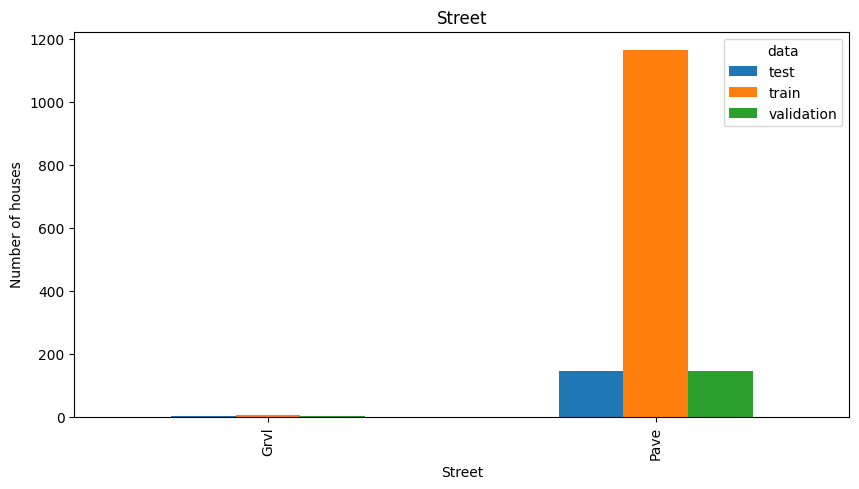

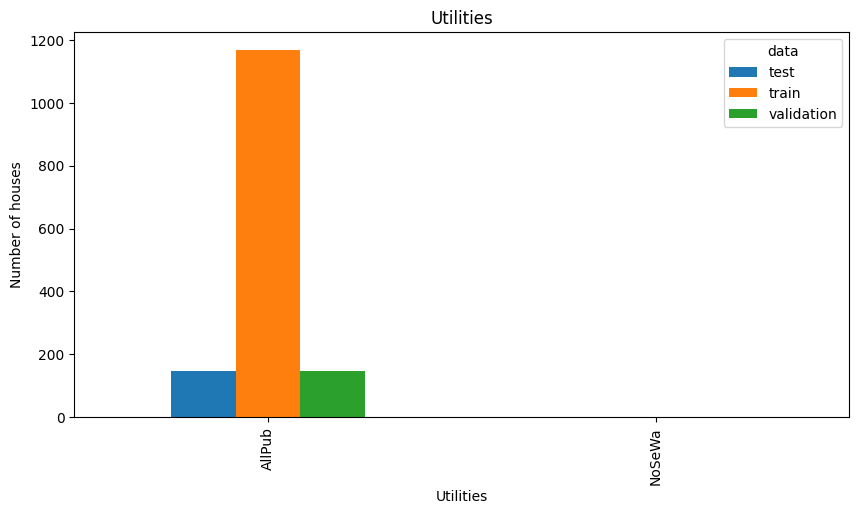

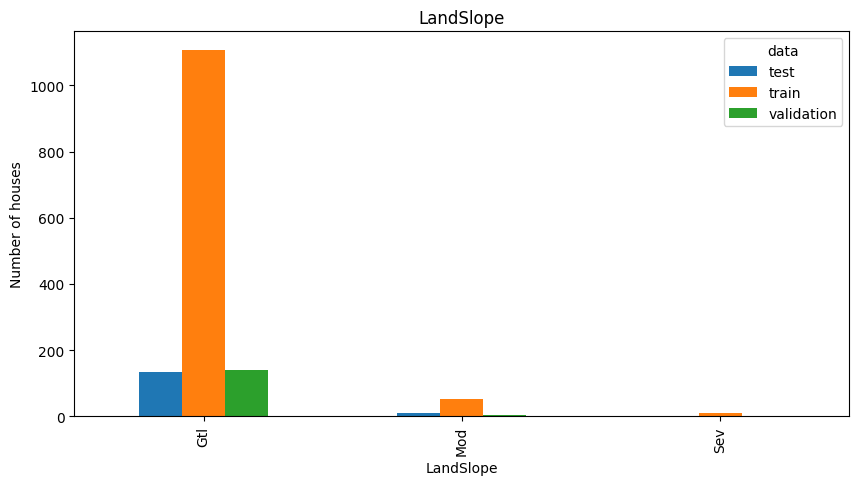

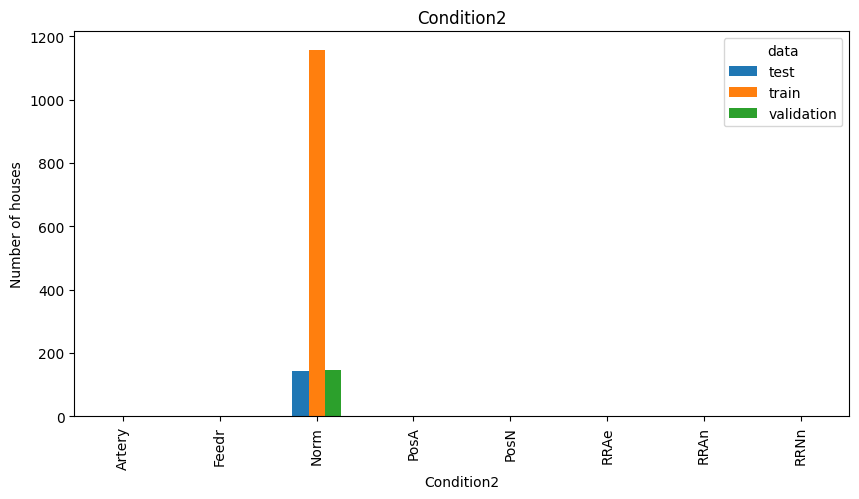

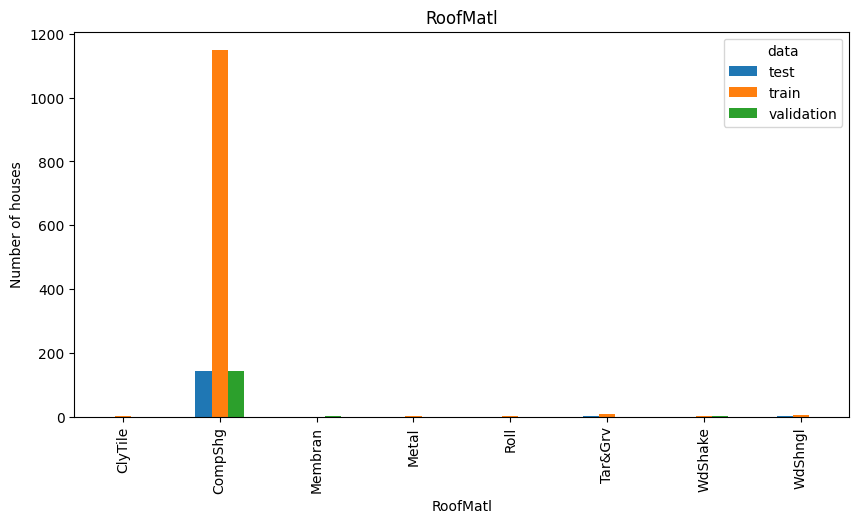

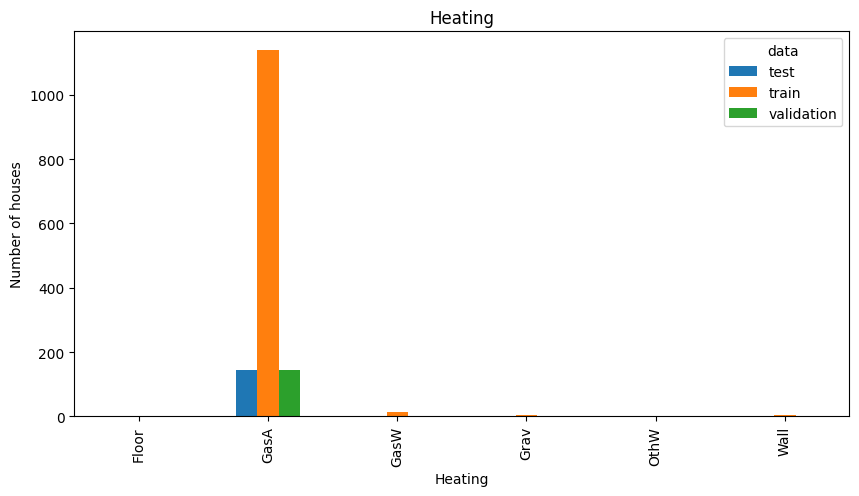

In [ ]:
# plot number of observations per category, per variable
# so that we see that these variables show mostly 1 value in most of the
# observations

for variable in constant.features_to_drop_:

    data.groupby(variable)['data'].value_counts().unstack().plot.bar(figsize=(10,5))
    plt.title(variable)
    plt.ylabel('Number of houses')
    plt.show()

Vidimo da ove varijable imaju većinski jednu vrednost za sve instance u skupu podataka. Re-mapiraćemo ove varijable tako da se sve manje frekventne vrednosti nalaze u kategoriji "Other".

In [ ]:
from feature_engine import encoding as enc

# Ako je kategorija prisutna u manje od 10% opservacija, biće mapirana u "Other" (sa drugim nefrekventnim kategorijama)
rare_enc = enc.RareLabelEncoder(tol = 0.1,
                                n_categories=1, # number of minimum categories per variable for the grouping to proceed
                                variables=constant.features_to_drop_, # the variables to pre-process
                                replace_with='Other', # the label to use to replace the original category
                               )

rare_enc.fit(X_train)

RareLabelEncoder(n_categories=1, replace_with='Other', tol=0.1,
                 variables=['Street', 'Utilities', 'LandSlope', 'Condition2',
                            'RoofMatl', 'Heating'])

In [ ]:
# make the grouping
X_train = rare_enc.transform(X_train)
X_val = rare_enc.transform(X_val)
X_test = rare_enc.transform(X_test)

Sada bismo trebalo videti samo dve kategorije za svaku varijablu:

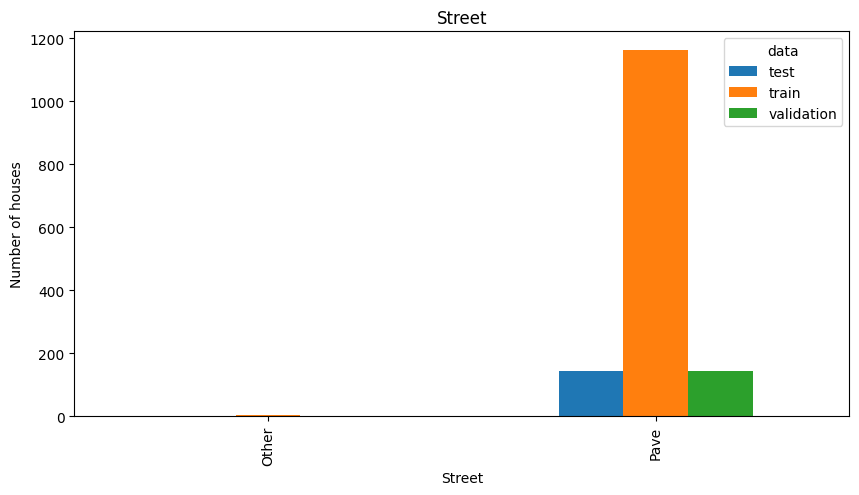

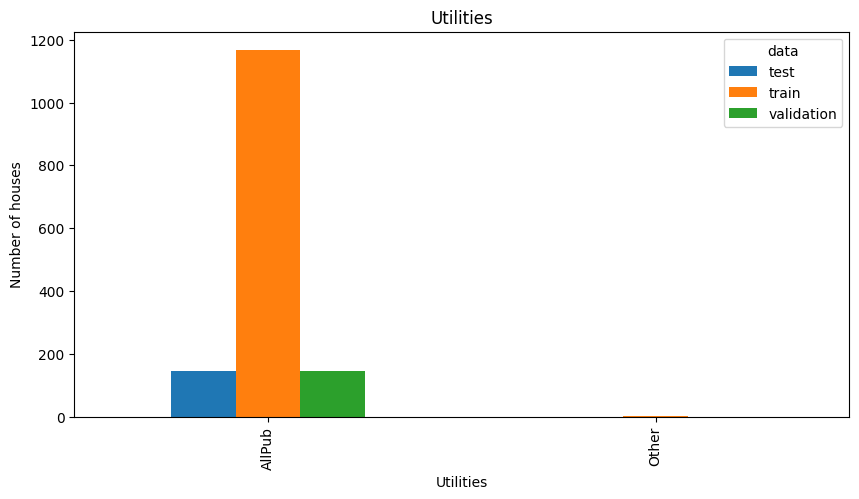

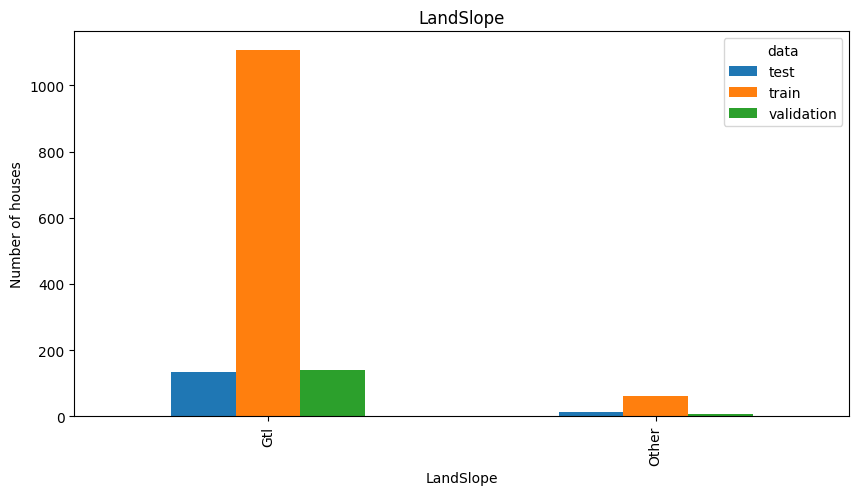

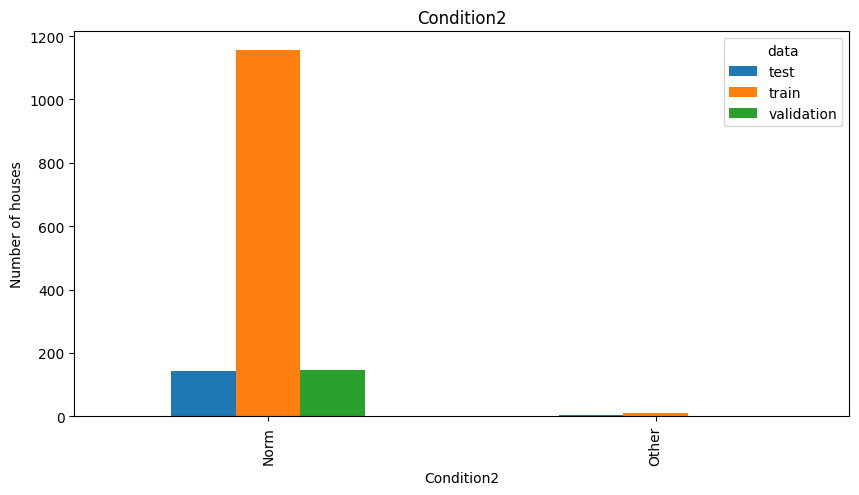

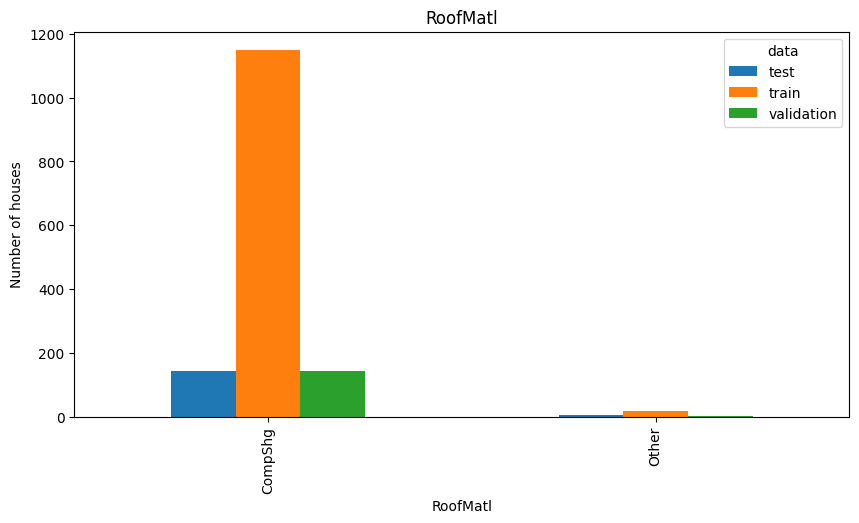

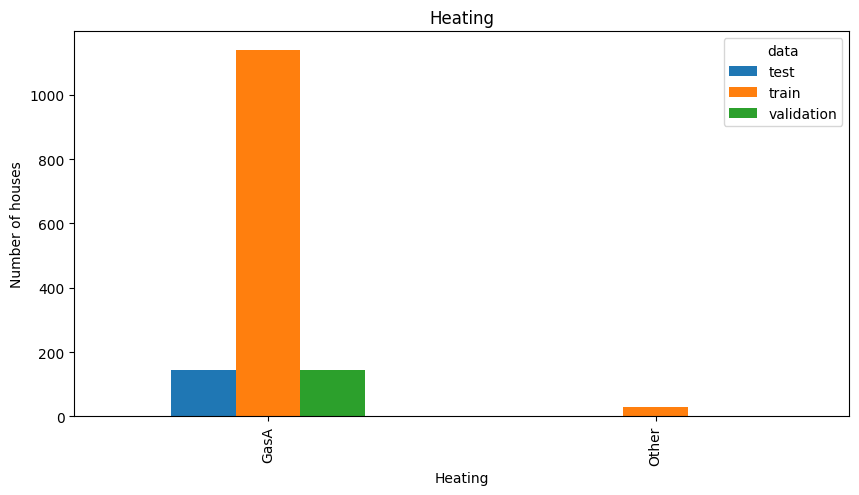

In [ ]:
data = create_master_data(X_train, X_val, X_test, y_train, y_val, y_test)

for variable in constant.features_to_drop_:

    data.groupby(variable)['data'].value_counts().unstack().plot.bar(figsize=(10,5))
    plt.title(variable)
    plt.ylabel('Number of houses')
    plt.show()

### Quality varijable

Postoji više varijable koje se odnose na kvalitet nekog aspekta kuće (npr., kvalitet garaže, ograde ili kuhinje). Zamenićemo ove kategorije sa vrednostima: Excellent - 5, Good - 4,...

In [ ]:
qual_mappings = {'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5, 'Missing': 0, 'NA': 0}

qual_vars = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond',
             'HeatingQC', 'KitchenQual', 'FireplaceQu',
             'GarageQual', 'GarageCond',
            ]

for var in qual_vars:
    X_train[var] = X_train[var].map(qual_mappings)
    X_val[var] = X_val[var].map(qual_mappings)
    X_test[var] = X_test[var].map(qual_mappings)

In [ ]:
exposure_mappings = {'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4, 'Missing': 0, 'NA': 0}

var = 'BsmtExposure'

X_train[var] = X_train[var].map(exposure_mappings)
X_val[var] = X_val[var].map(exposure_mappings)
X_test[var] = X_test[var].map(exposure_mappings)

In [ ]:
finish_mappings = {'Missing': 0, 'NA': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6}

finish_vars = ['BsmtFinType1', 'BsmtFinType2']

for var in finish_vars:
    X_train[var] = X_train[var].map(finish_mappings)
    X_val[var] = X_val[var].map(finish_mappings)
    X_test[var] = X_test[var].map(finish_mappings)

In [ ]:
garage_mappings = {'Missing': 0, 'NA': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}

var = 'GarageFinish'

X_train[var] = X_train[var].map(garage_mappings)
X_val[var] = X_val[var].map(garage_mappings)
X_test[var] = X_test[var].map(garage_mappings)

In [ ]:
fence_mappings = {'Missing': 0, 'NA': 0, 'MnWw': 1, 'GdWo': 2, 'MnPrv': 3, 'GdPrv': 4}

var = 'Fence'

X_train[var] = X_train[var].map(fence_mappings)
X_val[var] = X_val[var].map(fence_mappings)
X_test[var] = X_test[var].map(fence_mappings)

In [ ]:
# capture all quality variables
qual_vars  = qual_vars + finish_vars + ['BsmtExposure','GarageFinish','Fence']

Da bismo proverili korisnost varijabli, iscrtaćemo kako se menja srednja vrednost cene nekretnine, bazirano na kvalitetu različitih atributa.

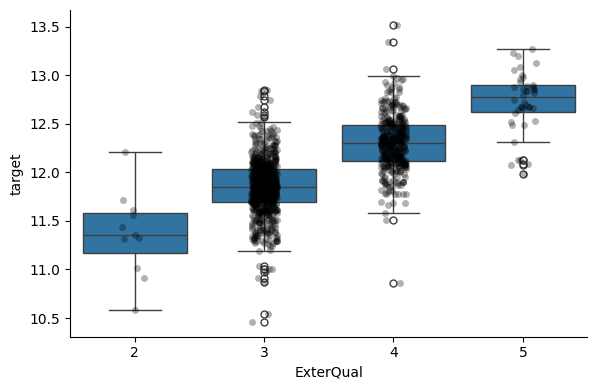

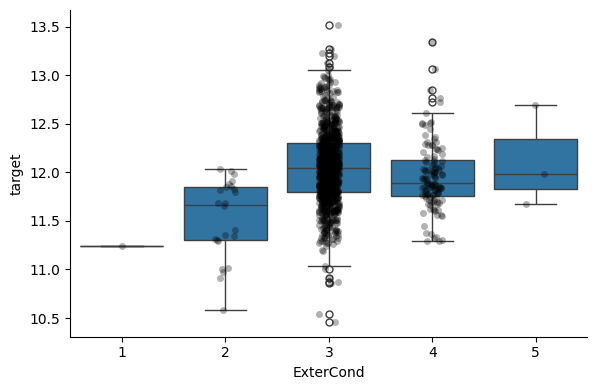

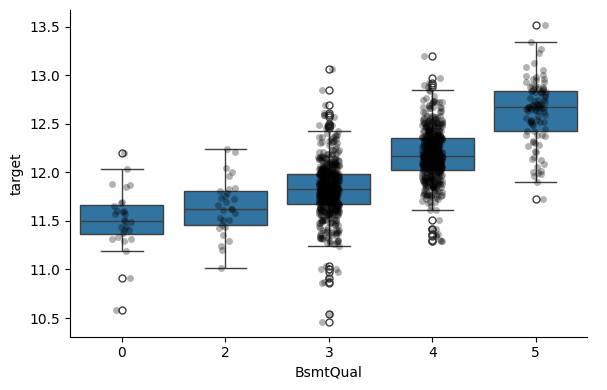

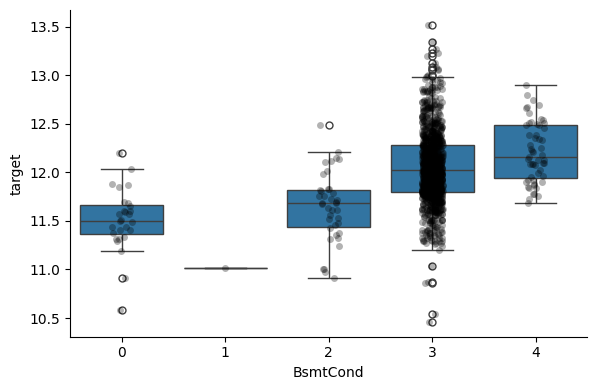

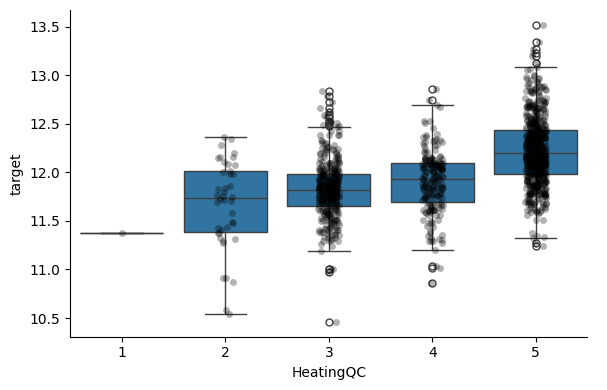

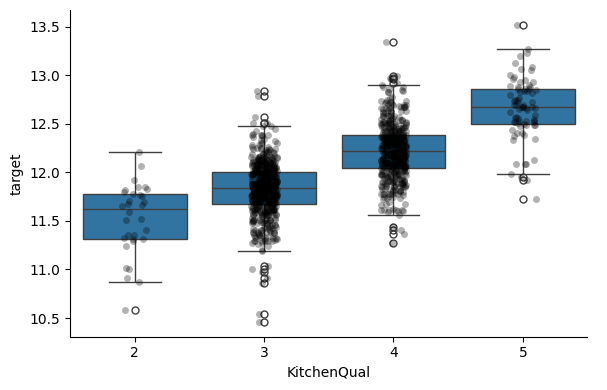

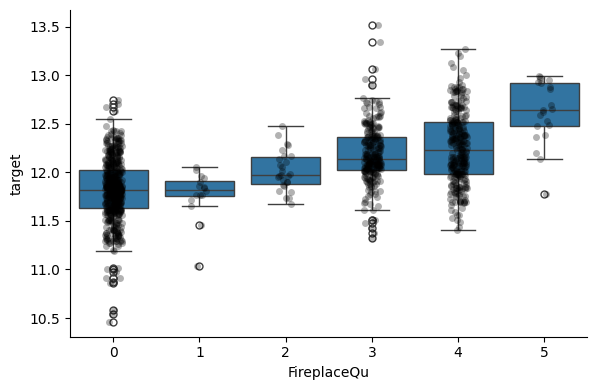

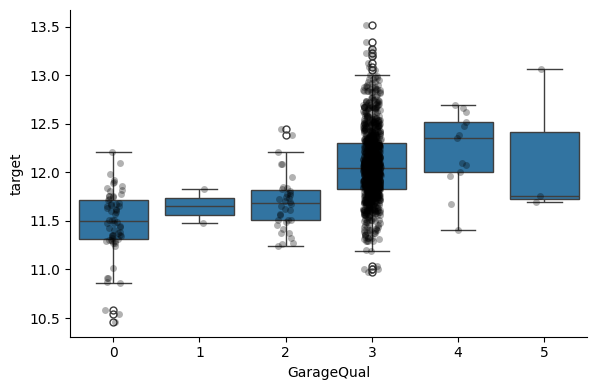

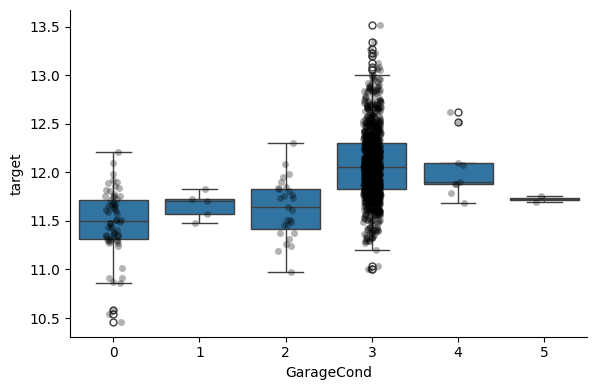

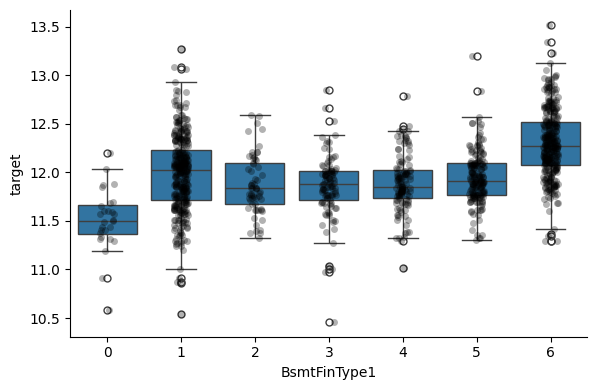

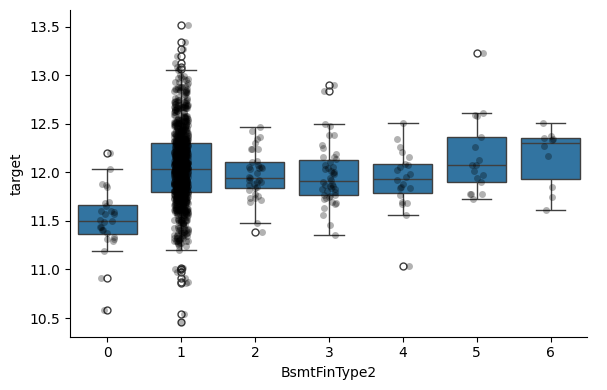

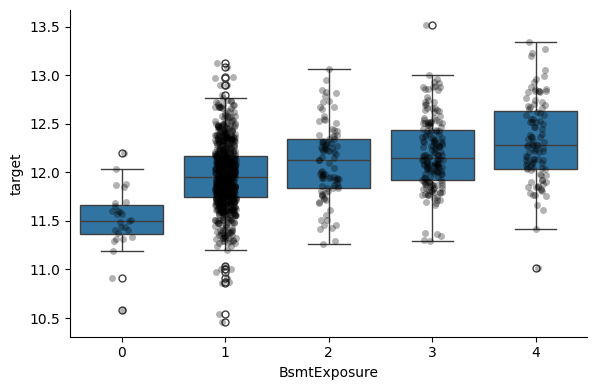

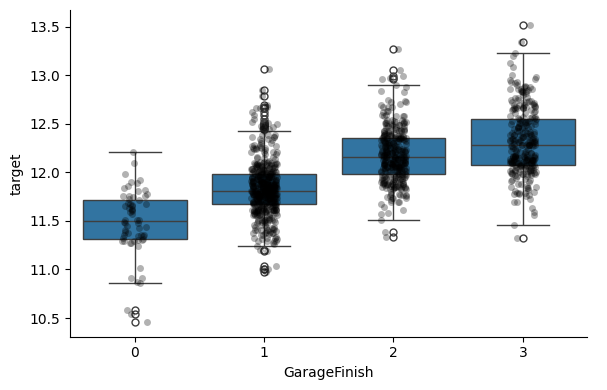

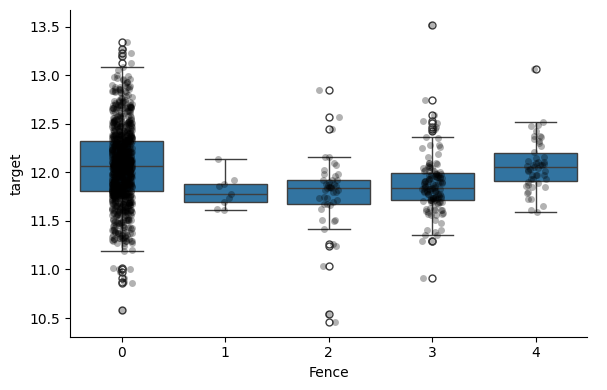

In [ ]:
# put data together for analysis
data = create_master_data(X_train, X_val, X_test, y_train, y_val, y_test)

for var in qual_vars:
    # make boxplot with Catplot
    sns.catplot(x=var, y='target', data=data[data['data']=='train'], kind="box", height=4, aspect=1.5)
    # add data points to boxplot with stripplot
    sns.stripplot(x=var, y='target', data=data[data['data']=='train'], jitter=0.1, alpha=0.3, color='k')
    plt.show()


Za mnoge varijable, vidimo da se sa kvalitetom povećava cena kuće.

### Kardinalitet (broj jedinstvenih vrednosti kategoričkih varijabli)

Što je veća kardinalnost, teže je raditi sa varijablom (iako varijabla može da pruži više informacija).

In [ ]:
# preostale kategoričke varijable:
categorical = [c for c in categorical if c not in constant.features_to_drop_]
categorical = [c for c in categorical if c not in qual_vars]

len(categorical)

21

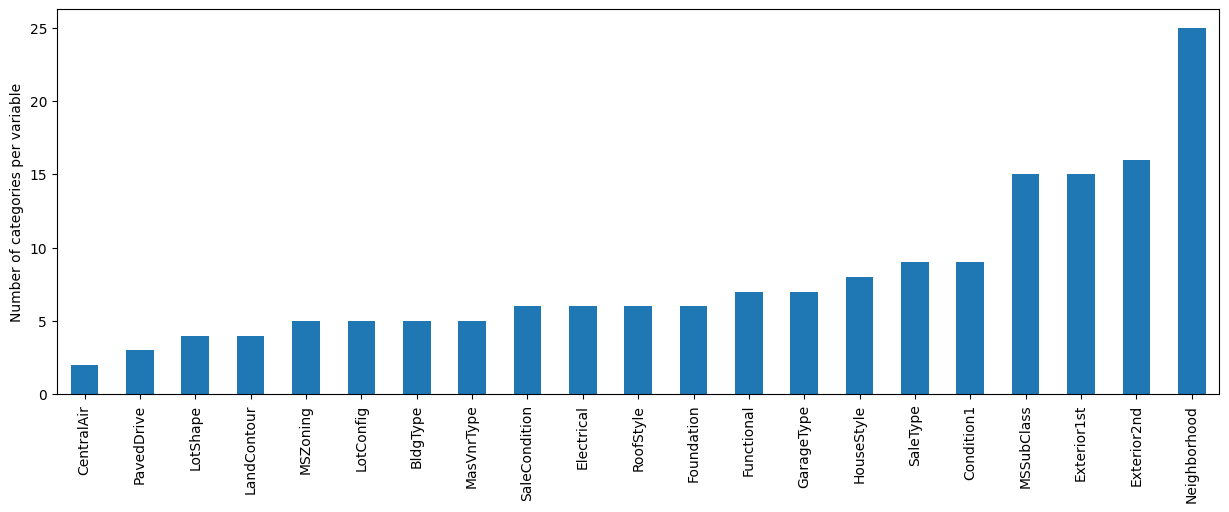

In [ ]:
# Sa nunique metodom iz pandas biblioteke možemo odrediti broj jedinstvenih vrednosti kategoričke varijable:
data[categorical].nunique().sort_values().plot.bar(figsize=(15,5))
plt.ylabel('Number of categories per variable')
plt.show()

Vidimo na neke varijable imaju mali broj kategorija (mala kardinalnost), a druge velik (velika kardinalnost).

Pored kardinalnosti, treba da razmotrimo i broj instanci koje pripadaju svakoj od kategorija. Kategorije koje su slabo zastupljene u skupu podataka mogu praviti problem pri izgradnji modela.

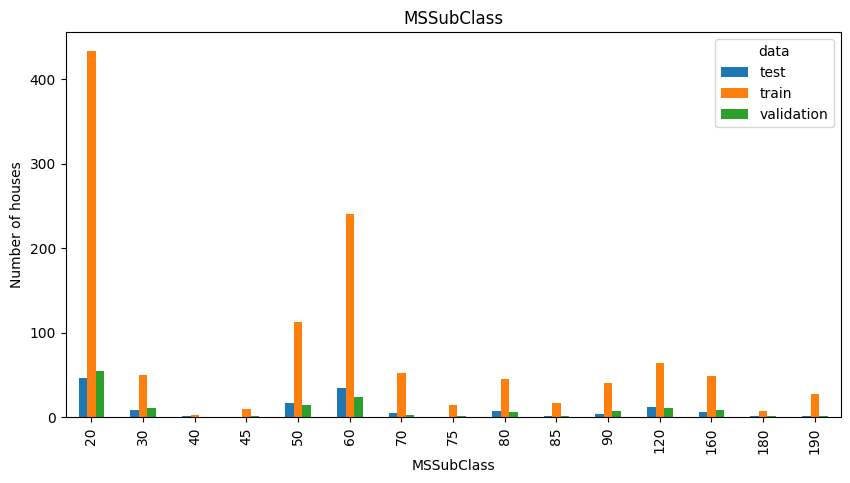

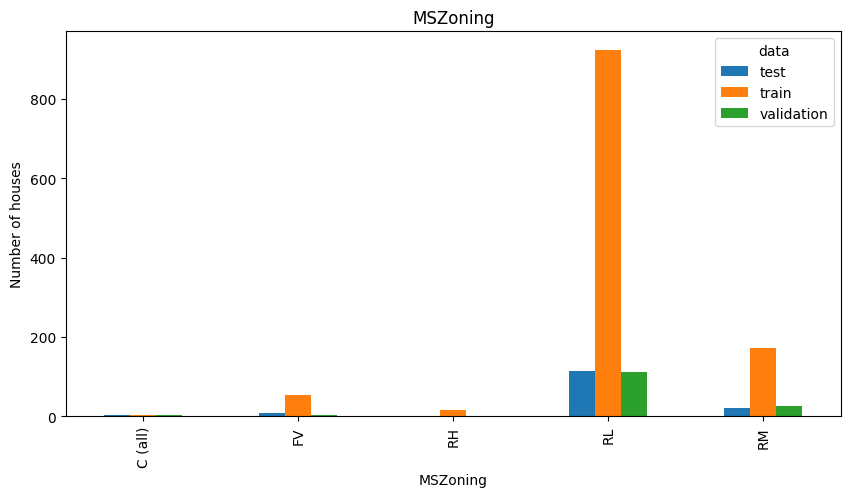

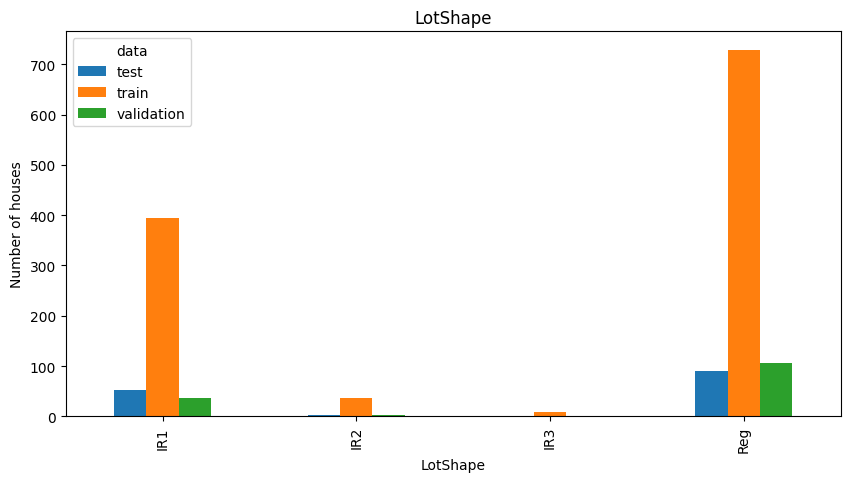

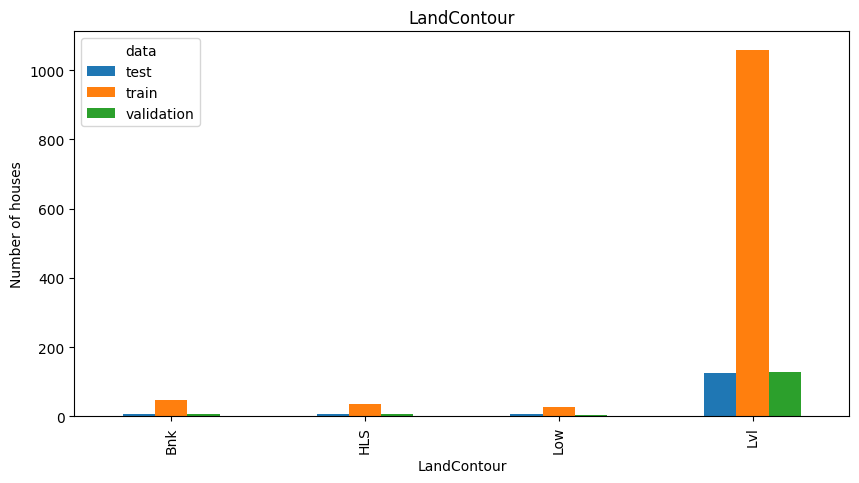

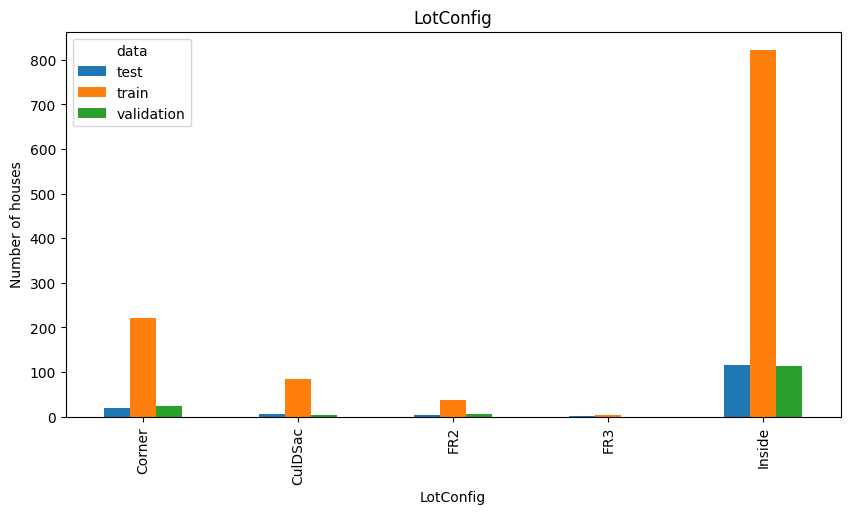

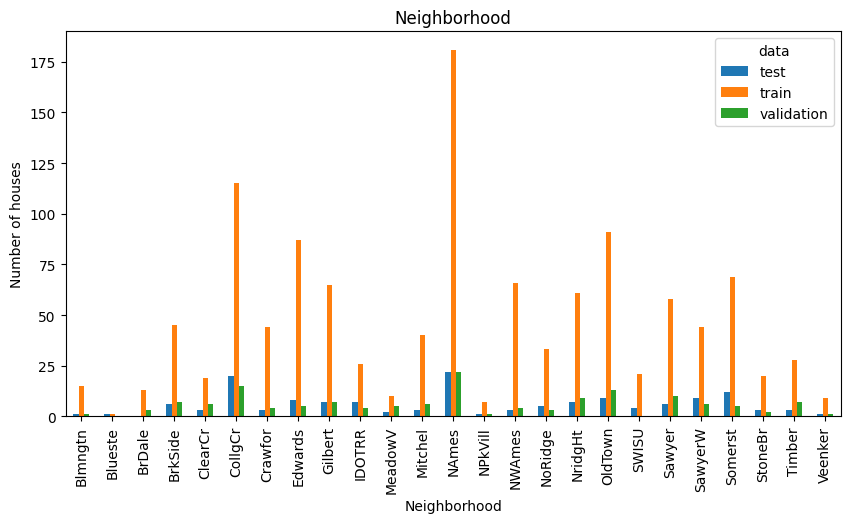

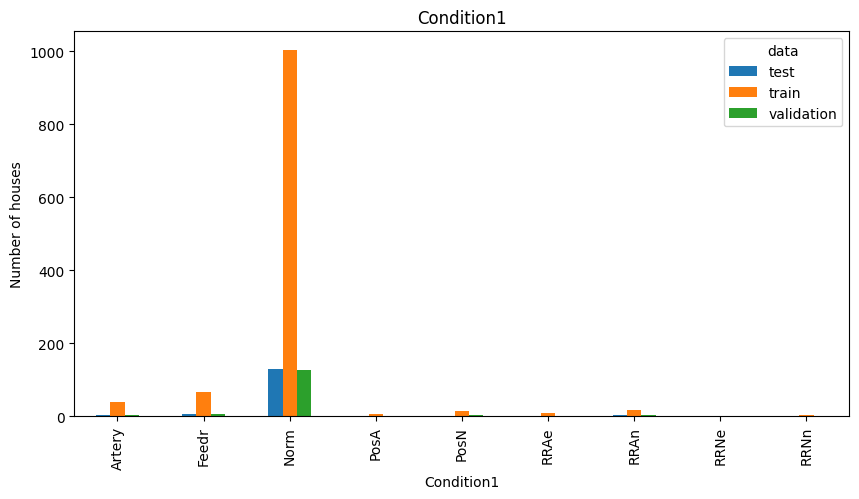

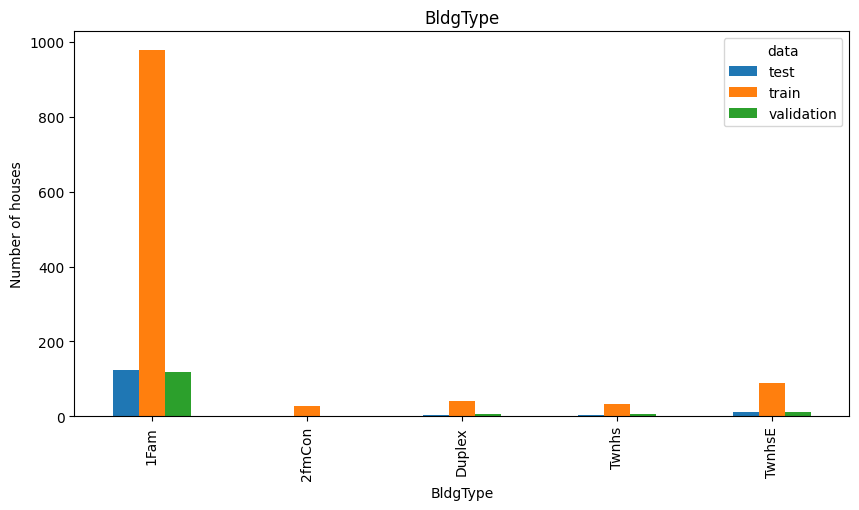

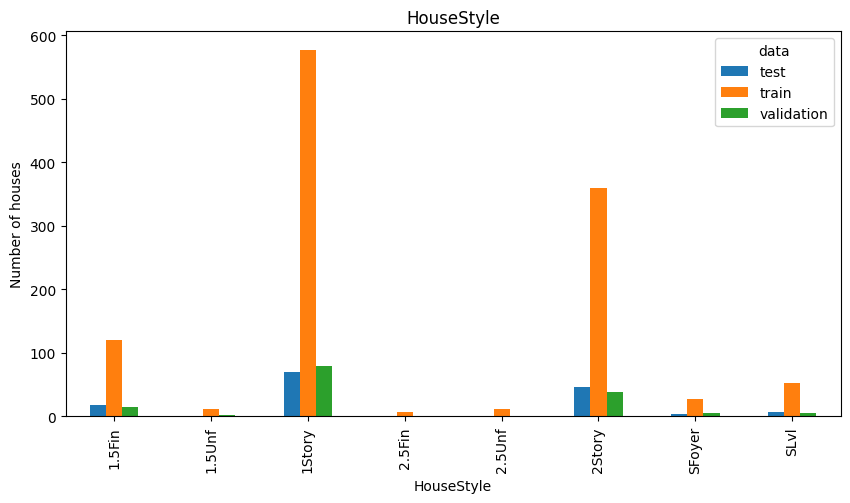

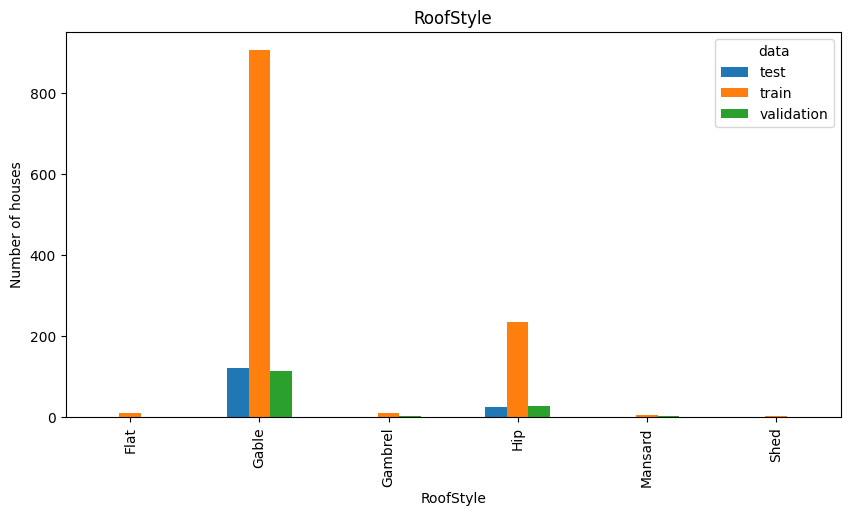

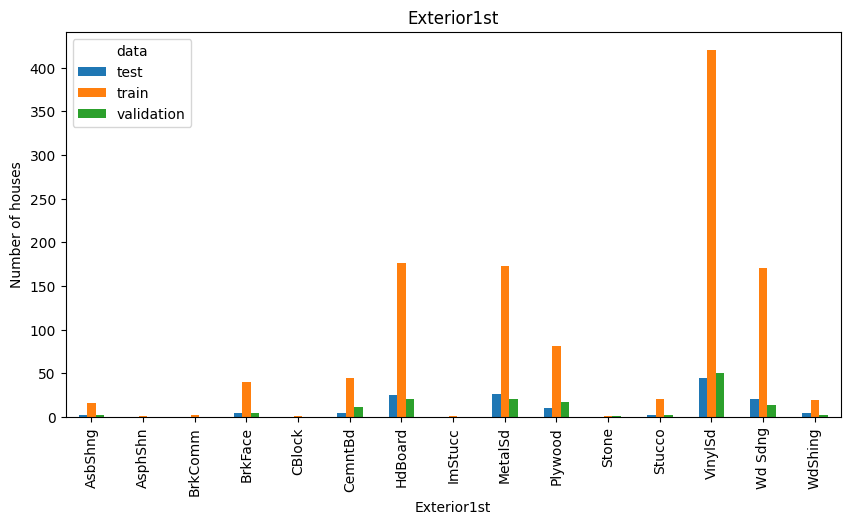

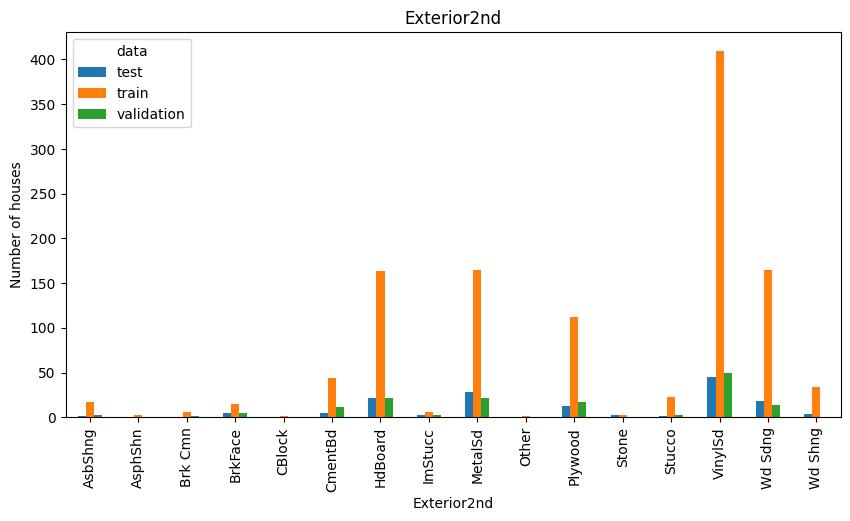

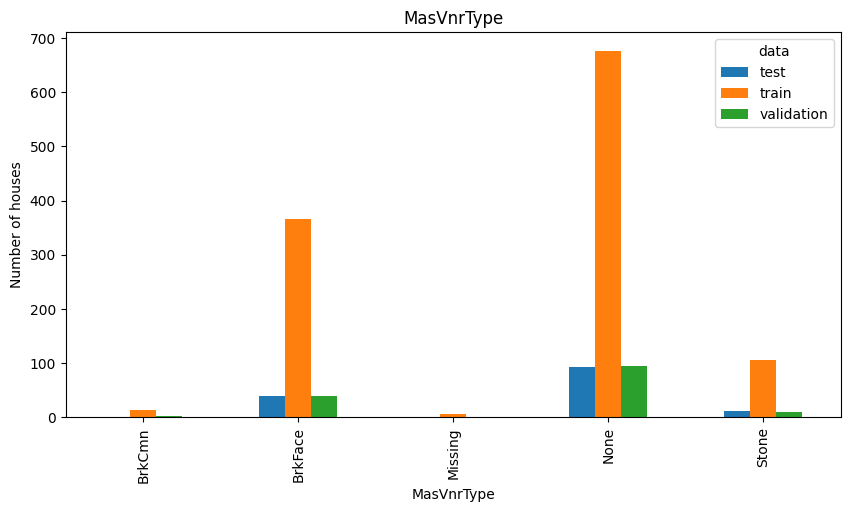

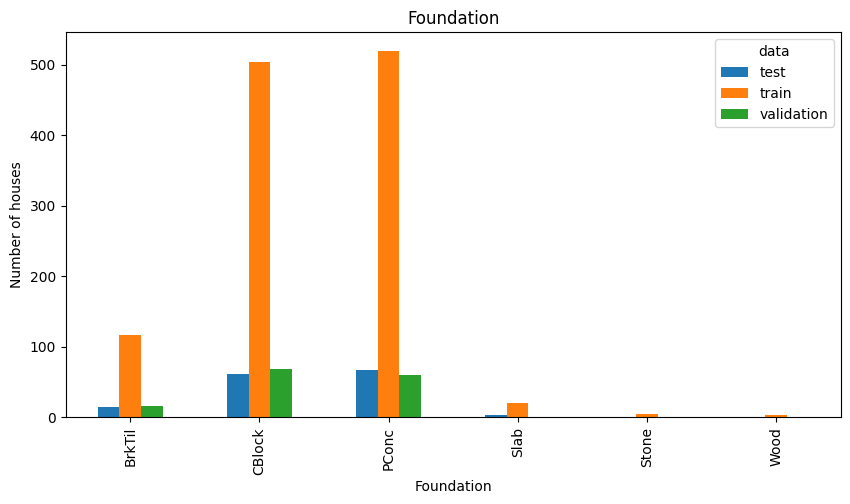

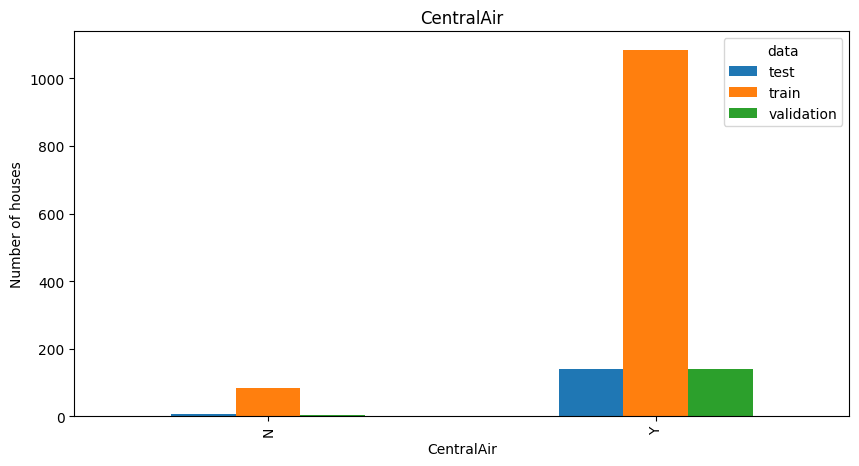

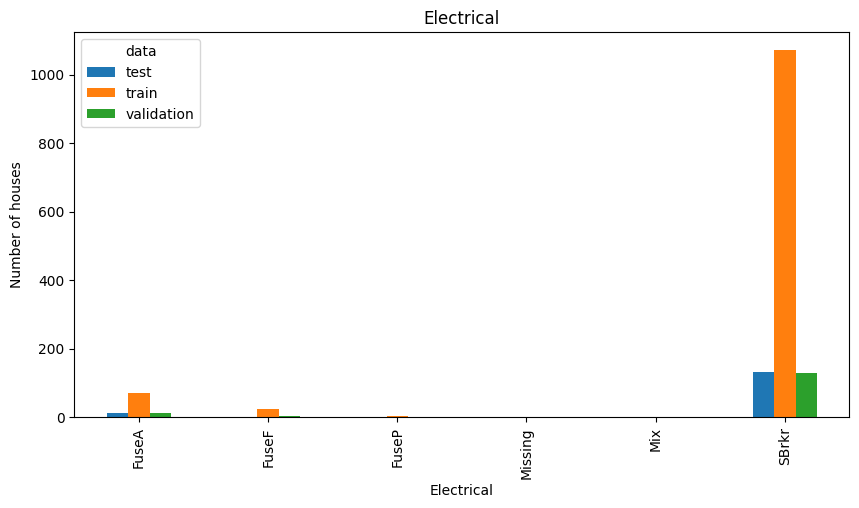

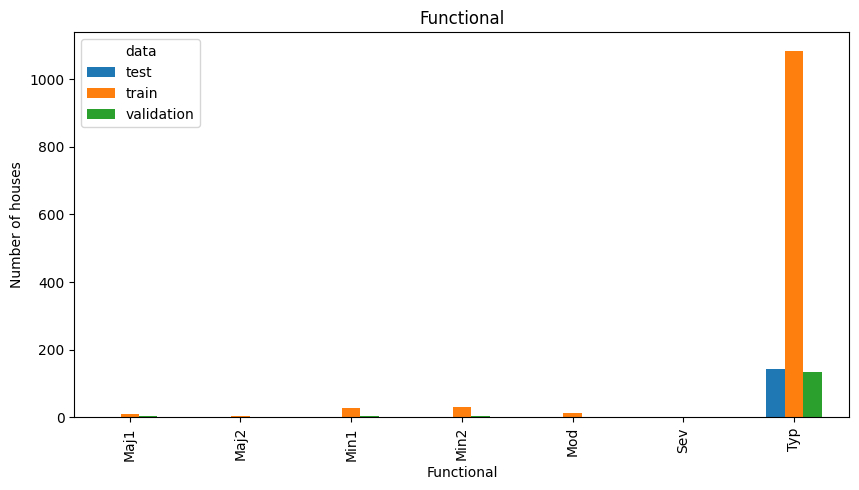

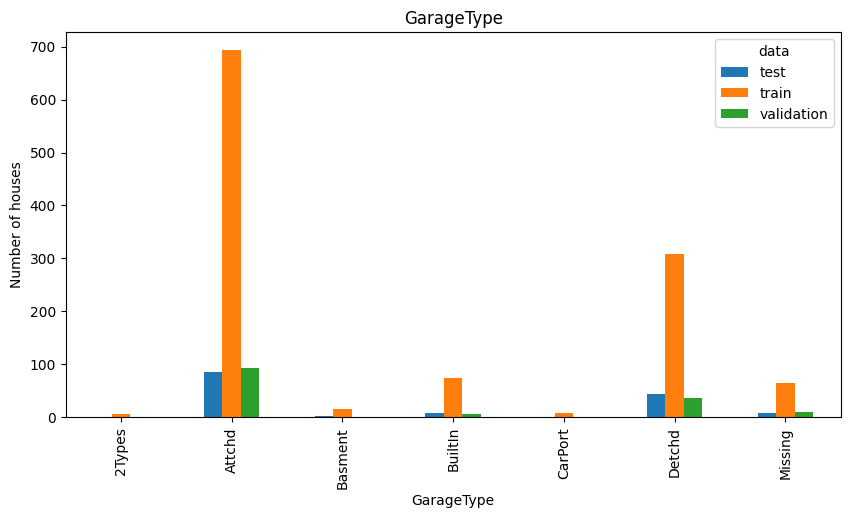

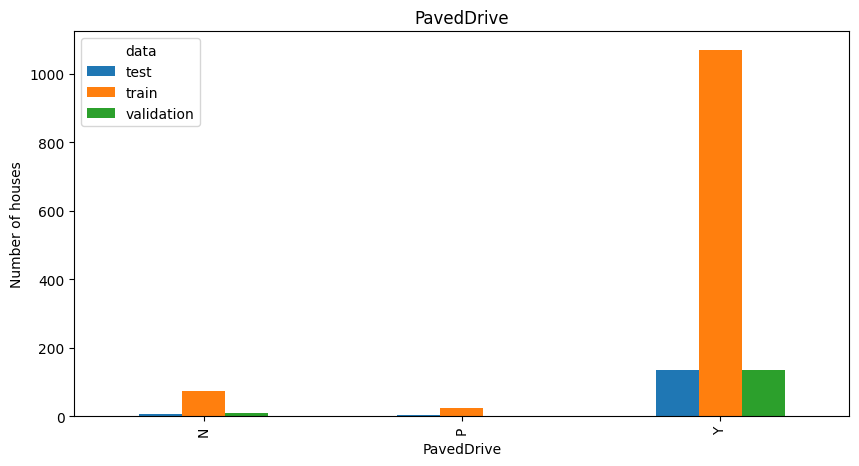

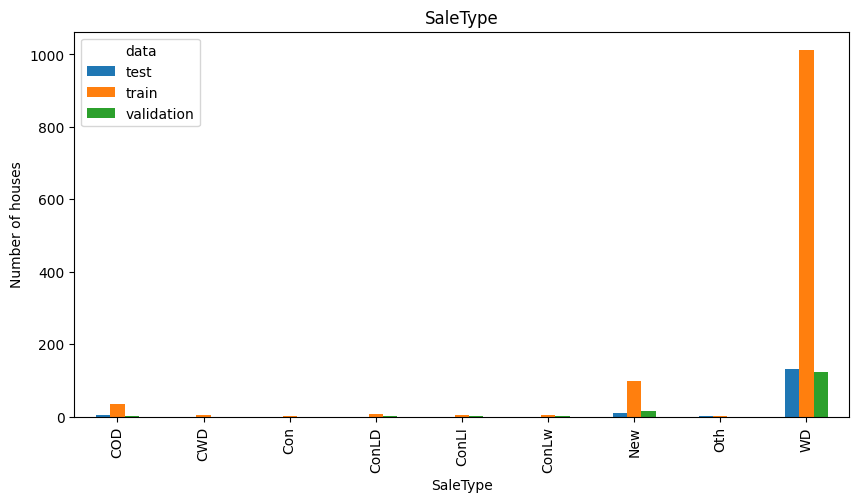

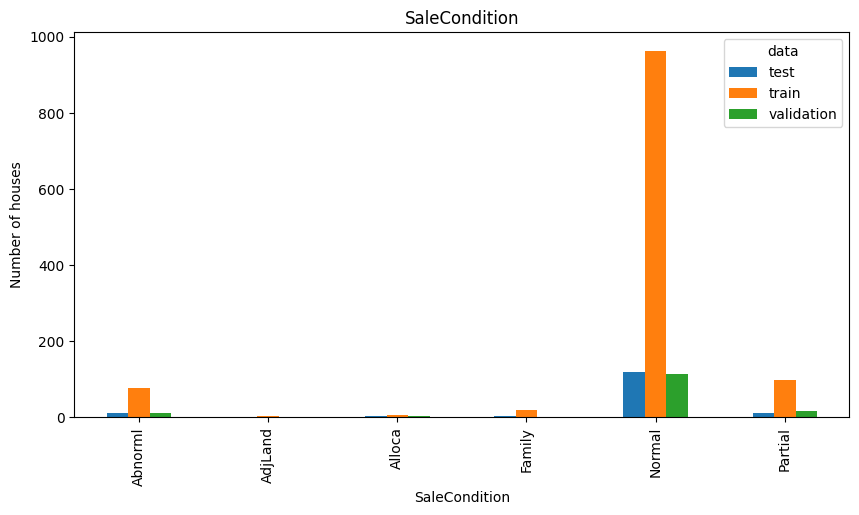

In [ ]:
# plot number of observations / houses per category, per variable
for variable in categorical:
    data.groupby(variable)['data'].value_counts().unstack().plot.bar(figsize=(10,5))
    plt.title(variable)
    plt.ylabel('Number of houses')
    plt.show()

Vidimo da u gotovo svakoj kategoričkoj varijabli, većina nekretnina deli jednu kategoriju, a da su druge kategorije prisutne u veoma maloj meri u skupu podataka. Za te slabo-prisutne varijable:
* ne znamo da li možemo da verujemo cenama nekretnine jer imamo malo takvih nekretnina iz kojih možemo da učimo.
* Određena retka kategorija se može naći samo u trening skupu, a da ne postoji u vaidacionim i test podacima. Model može biti overfitovan na ove kategorije
* Ako se kategorija pojavi samo u validacionom ili test skupu (a nema je u trening skupu), model može da ne zna da donese odluku.

Zato ćemo sve ne-frekventne labele grupisati u jednu kategoriju "Rare". Međutim, pre toga, treba da istražimo da li ipak postoji neka vrednost u ovim kategorijama.

In [ ]:
# Funkcija računa
# 1) % nekretnina po kategoriji
# 2) Srednju vrednost SalePrice po kategoriji
# i vraća dataframe sa ove dve varijable:
def calculate_mean_target_per_category(df, var):

    df = pd.concat([df, y_train], axis=1)

    # total number of houses
    total_houses = len(df)

    # percentage of houses per category
    temp_df = pd.Series(df[var].value_counts() / total_houses).reset_index()
    temp_df.columns = [var, 'perc_houses']

    # add the mean SalePrice
    temp_df = temp_df.merge(df.groupby([var])['SalePrice'].mean().reset_index(),
                            on=var,
                            how='left')

    return temp_df

In [ ]:
# Hajde da razmotrimo 'Neighborhood' varijablu:
temp_df = calculate_mean_target_per_category(X_train, 'Neighborhood')

temp_df.head()

,Neighborhood,perc_houses,SalePrice
0,NAmes,0.154966,11.877946
1,CollgCr,0.098459,12.179079
2,OldTown,0.077911,11.734458
3,Edwards,0.074486,11.712066
4,Somerst,0.059075,12.297926


In [ ]:
# Funkcija koja iscrtava frekvenciju kategorije naspram srednje vrednosti SalePrice.
# Na ovaj način možemo oceniti odnos kategorija obeležja i ciljne varijable.
def plot_categories(df, var):

    fig, ax = plt.subplots(figsize=(8, 4))
    plt.xticks(df.index, df[var], rotation=90)

    ax2 = ax.twinx()
    ax.bar(df.index, df["perc_houses"], color='lightgrey')
    ax2.plot(df.index, df["SalePrice"], color='green', label='Seconds')
    ax.axhline(y=0.05, color='red')
    ax.set_ylabel('percentage of houses per category')
    ax.set_xlabel(var)
    ax2.set_ylabel('Average Sale Price per category')
    plt.show()

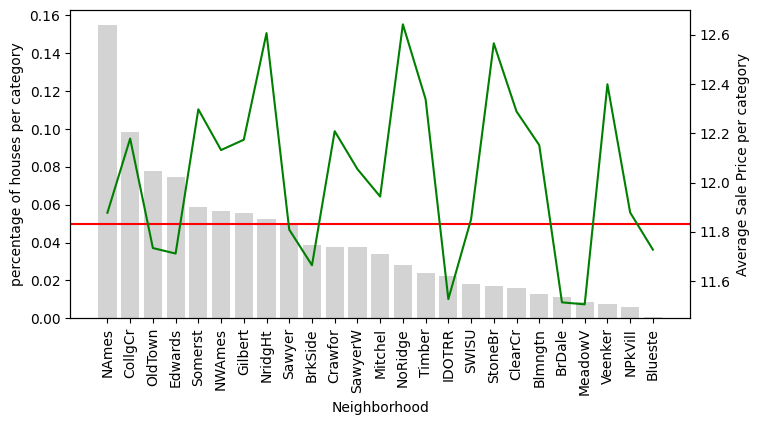

In [ ]:
plot_categories(temp_df, 'Neighborhood')

Sa grafika iznad vidimo da postoje "skupa" susedstva i "jeftina" susedstva.

In [ ]:
temp_df['SalePrice'].describe()

count    25.000000
mean     12.031658
std       0.342182
min      11.505808
25%      11.734458
50%      12.055096
75%      12.289177
max      12.642993
Name: SalePrice, dtype: float64

In [ ]:
# Lista najjeftinijih susedstava:
cheap_neighbourhoods = temp_df[temp_df['SalePrice']<11.75]['Neighborhood'].unique()
cheap_neighbourhoods

array(['OldTown', 'Edwards', 'BrkSide', 'IDOTRR', 'BrDale', 'MeadowV',
       'Blueste'], dtype=object)

In [ ]:
# Lista najskupljih susedstava:
expensive_neighbourhoods = temp_df[temp_df['SalePrice']>12.2]['Neighborhood'].unique()
expensive_neighbourhoods

array(['Somerst', 'NridgHt', 'Crawfor', 'NoRidge', 'Timber', 'StoneBr',
       'ClearCr', 'Veenker'], dtype=object)

In [ ]:
# nova varijabla koja agregira susedsva prema ovim listama:
X_train['Neigh_Price'] = np.where(X_train['Neighborhood'].isin(cheap_neighbourhoods),
                                  0, np.where(X_train['Neighborhood'].isin(expensive_neighbourhoods),
                                              2, 1))

X_test['Neigh_Price'] = np.where(X_test['Neighborhood'].isin(cheap_neighbourhoods),
                                  0, np.where(X_test['Neighborhood'].isin(expensive_neighbourhoods),
                                              2, 1))

X_val['Neigh_Price'] = np.where(X_val['Neighborhood'].isin(cheap_neighbourhoods),
                                  0, np.where(X_val['Neighborhood'].isin(expensive_neighbourhoods),
                                              2, 1))

X_train['Neigh_Price'].value_counts()

1    612
2    283
0    273
Name: Neigh_Price, dtype: int64

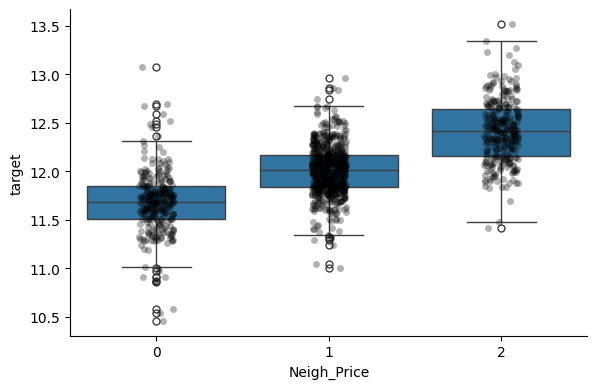

In [ ]:
# let's inspect the value of our new variable
data = create_master_data(X_train, X_val, X_test, y_train, y_val, y_test)

sns.catplot(x='Neigh_Price', y='target', data=data[data['data']=='train'], kind="box", height=4, aspect=1.5)
sns.stripplot(x='Neigh_Price', y='target', data=data[data['data']=='train'], jitter=0.1, alpha=0.3, color='k')
plt.show()

Izgleda da nova varijabla donosi vrednost.

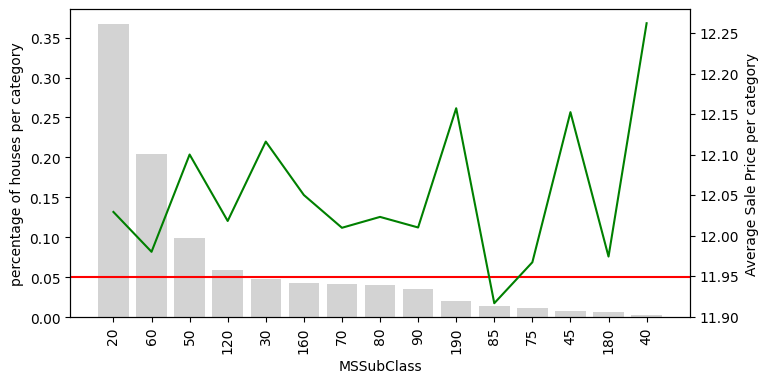

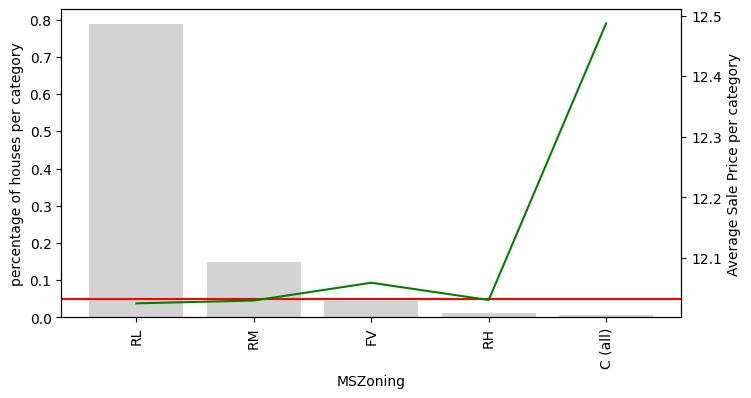

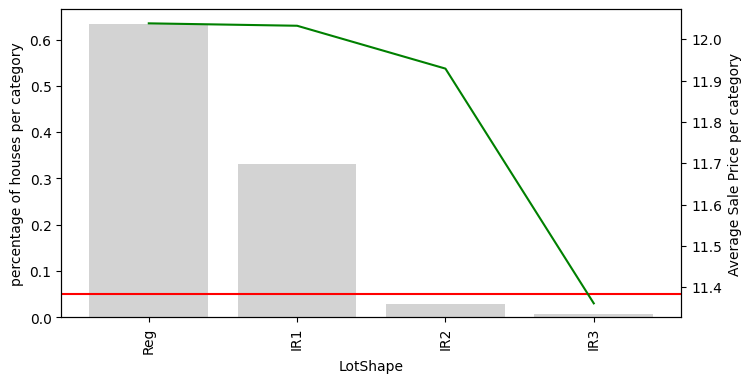

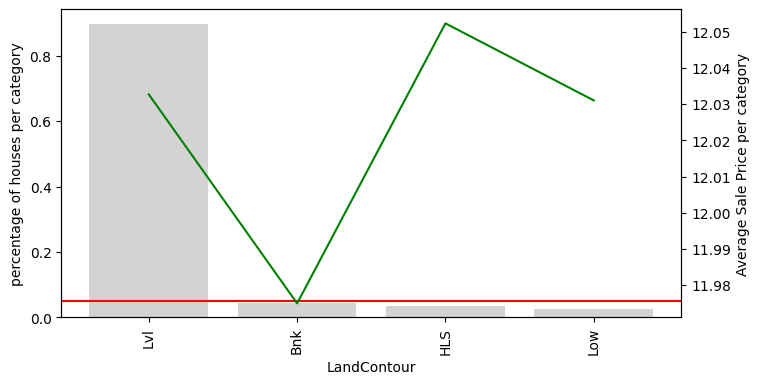

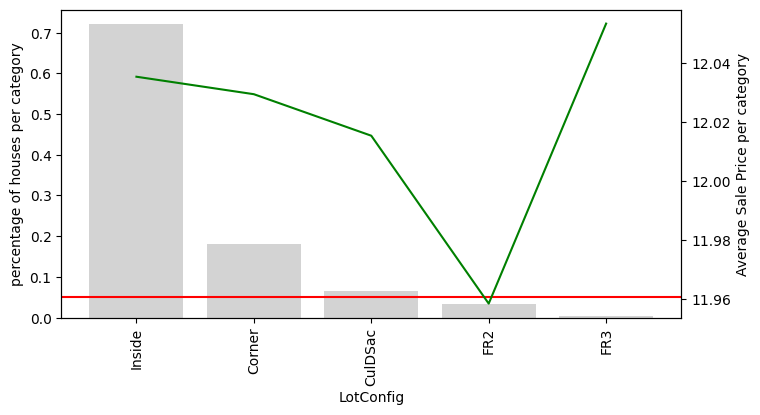

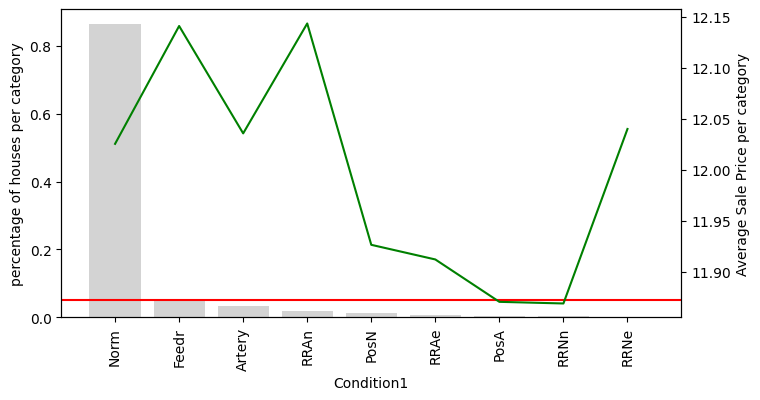

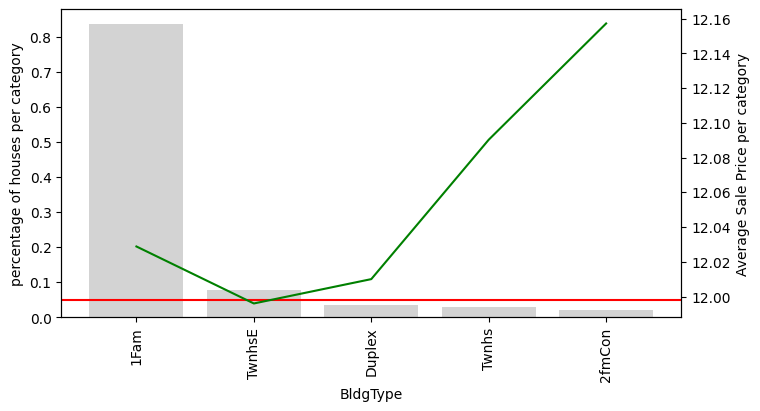

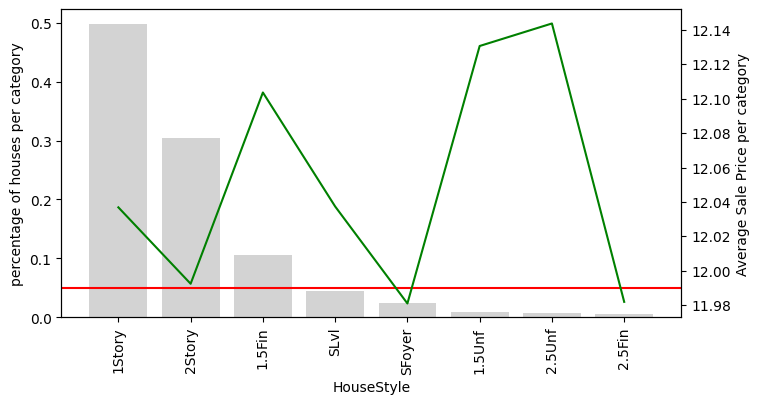

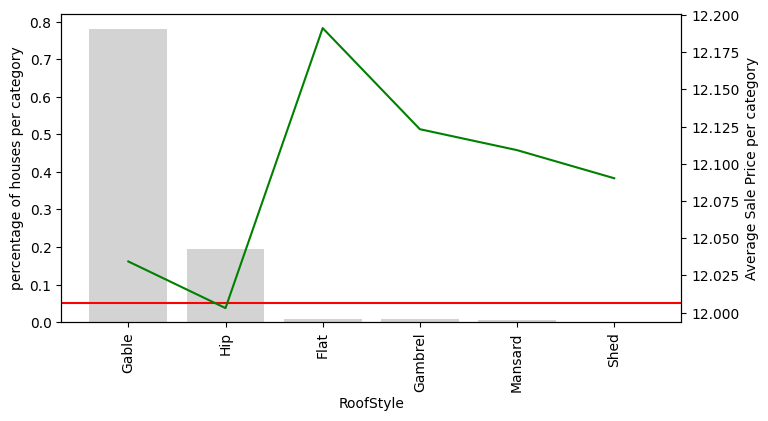

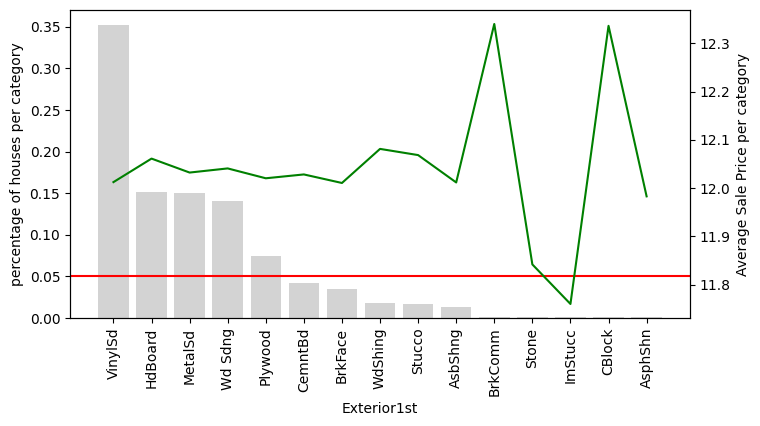

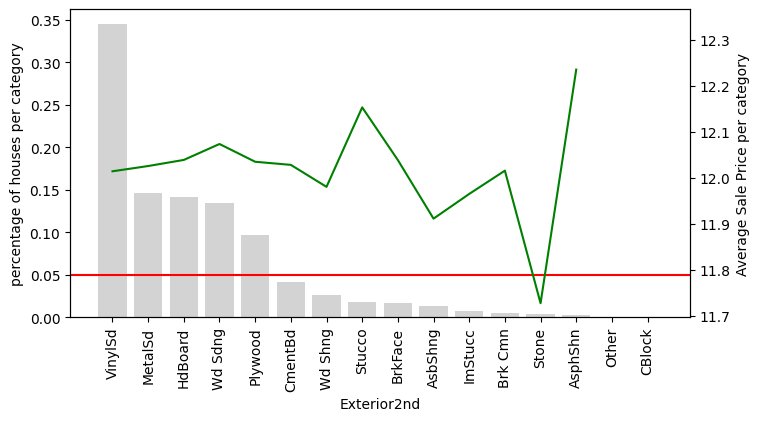

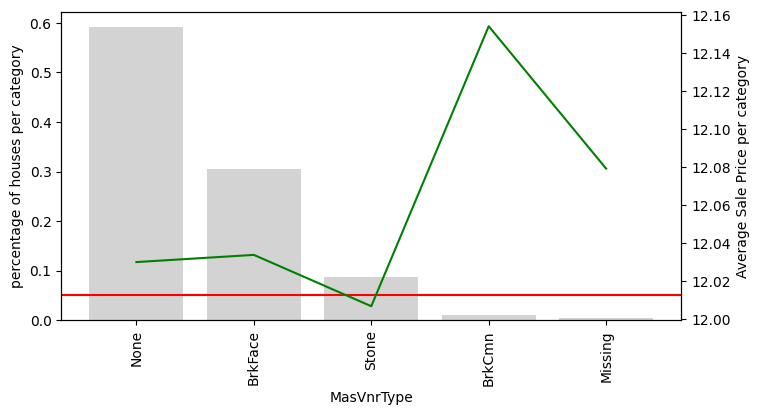

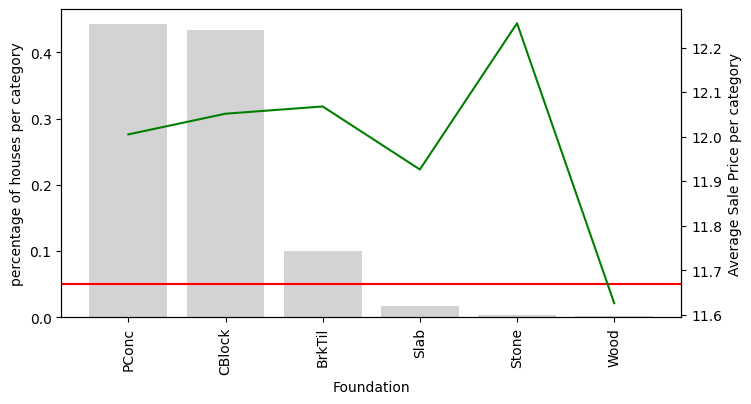

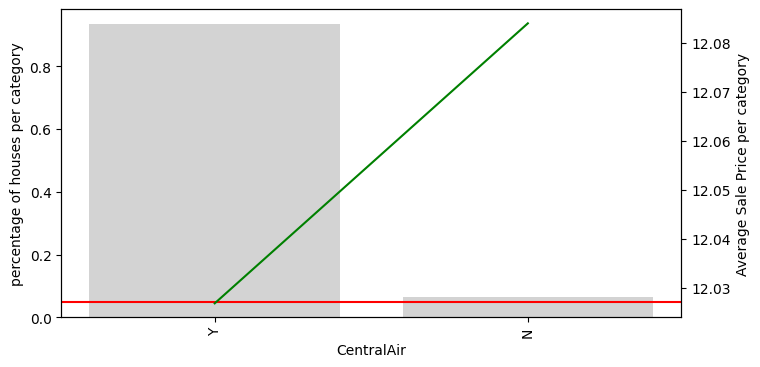

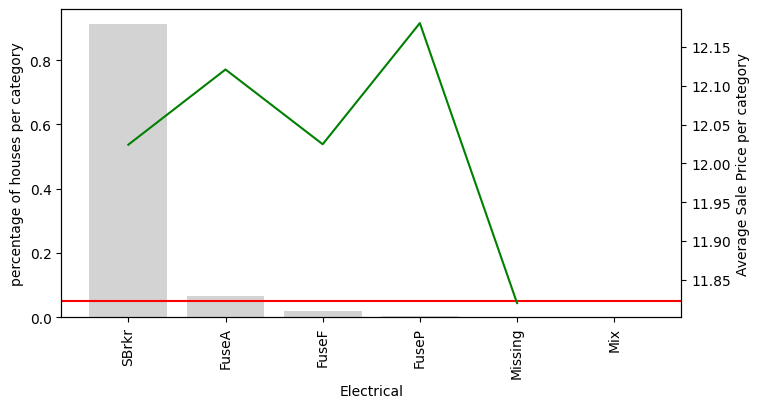

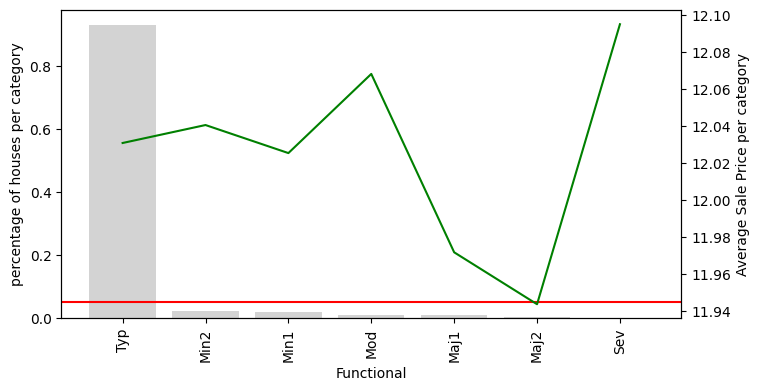

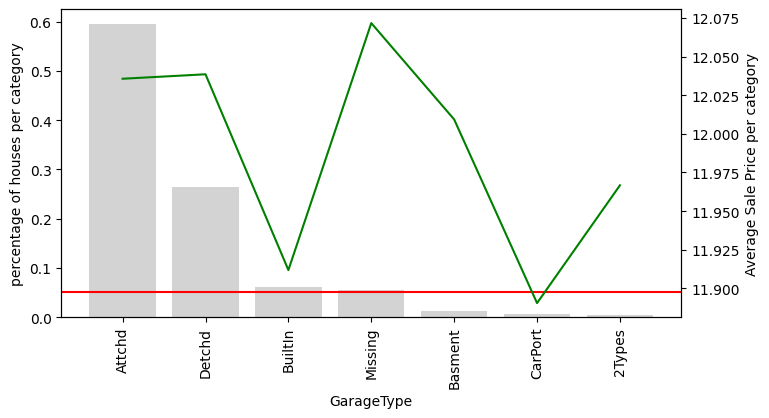

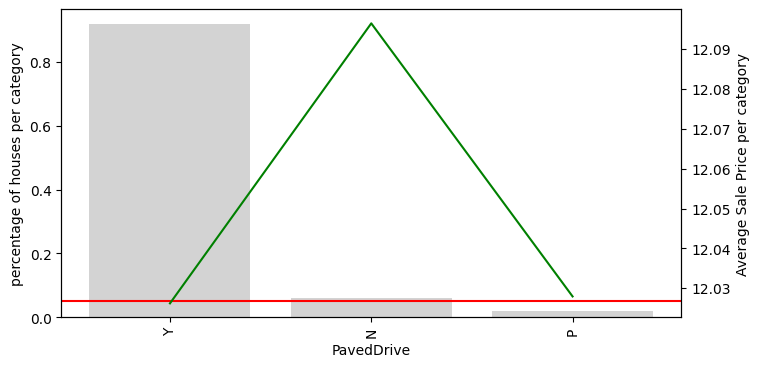

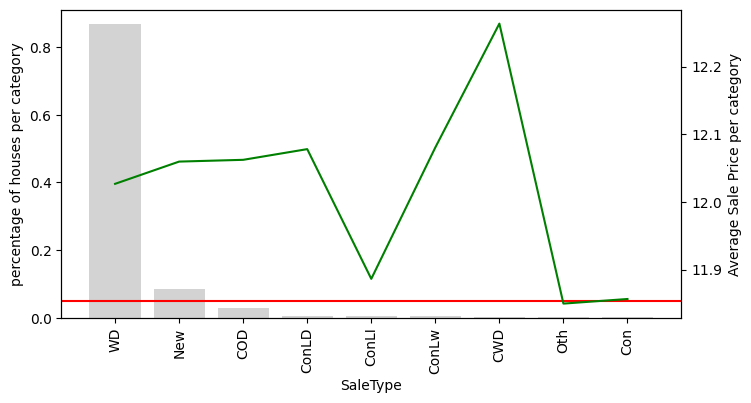

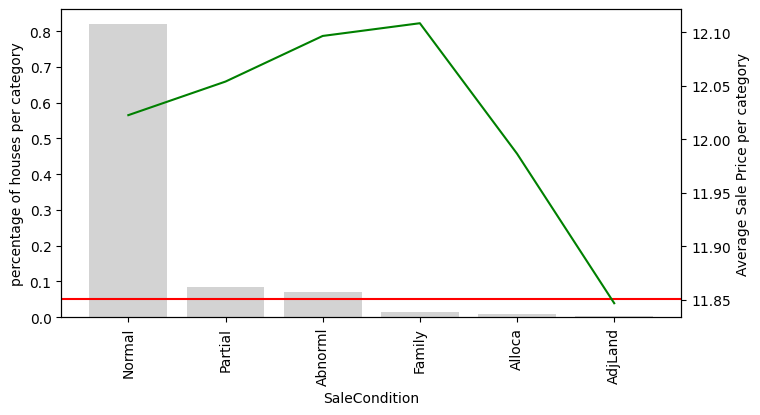

In [ ]:
# Uradimo slično za ostale kategoričke varijable:

for col in categorical:
    # već smo iscrtali za Neighborhood
    if col !='Neighborhood':
        temp_df = calculate_mean_target_per_category(data, col)
        plot_categories(temp_df, col)

Ostale varijable ne pokazuju jasne varijacije cena za određene kategorije, te nećemo od njih praviti nova obeležja. Grupisaćemo neferkventne kategorije:

In [ ]:
# Ako je kategorija prisutna u manje od 5% instanci, grupišemo je sa drugim nefrekventnim kategorijama:
rare_enc = enc.RareLabelEncoder(tol = 0.05,
                                n_categories=4, # number of minimum categories per variable for the grouping to proceed
                                variables=categorical
                               )

rare_enc.fit(X_train)

/usr/local/lib/python3.10/dist-packages/feature_engine/encoding/rare_label.py:216: UserWarning: The number of unique categories for variable LotShape is less than that indicated in n_categories. Thus, all categories will be considered frequent
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/feature_engine/encoding/rare_label.py:216: UserWarning: The number of unique categories for variable LandContour is less than that indicated in n_categories. Thus, all categories will be considered frequent
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/feature_engine/encoding/rare_label.py:216: UserWarning: The number of unique categories for variable CentralAir is less than that indicated in n_categories. Thus, all categories will be considered frequent
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/feature_engine/encoding/rare_label.py:216: UserWarning: The number of unique categories for variable PavedDrive is less than that indicated in n_categories. Thus, all categ

RareLabelEncoder(n_categories=4,
                 variables=['MSSubClass', 'MSZoning', 'LotShape', 'LandContour',
                            'LotConfig', 'Neighborhood', 'Condition1',
                            'BldgType', 'HouseStyle', 'RoofStyle',
                            'Exterior1st', 'Exterior2nd', 'MasVnrType',
                            'Foundation', 'CentralAir', 'Electrical',
                            'Functional', 'GarageType', 'PavedDrive',
                            'SaleType', 'SaleCondition'])

Warnings - postoji nekoliko kategoričkih varijabli koje imaju manje od 4 jedinstvene kategorije, te transformer te neće pretprocesirati (iznad u kodu n_categories=4)

In [ ]:
X_train = rare_enc.transform(X_train)
X_val = rare_enc.transform(X_val)
X_test = rare_enc.transform(X_test)

X_train.shape, X_val.shape, X_test.shape

((1168, 82), (146, 82), (146, 82))

In [ ]:
data = create_master_data(X_train, X_val, X_test, y_train, y_val, y_test)

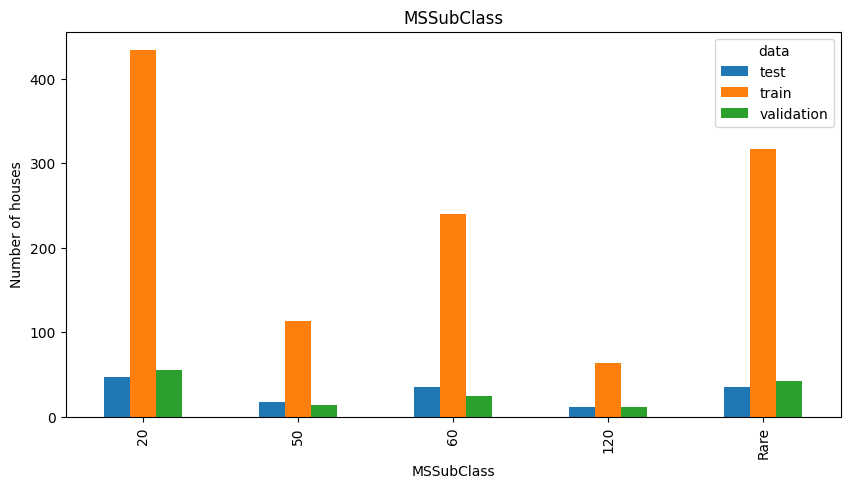

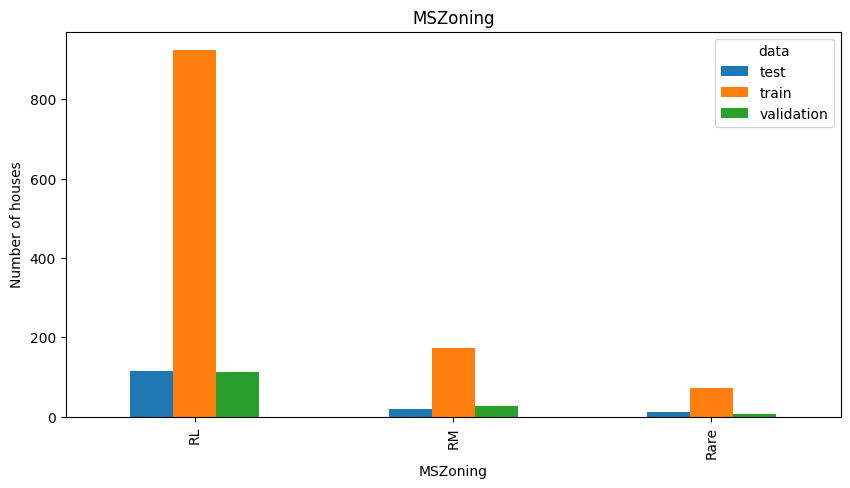

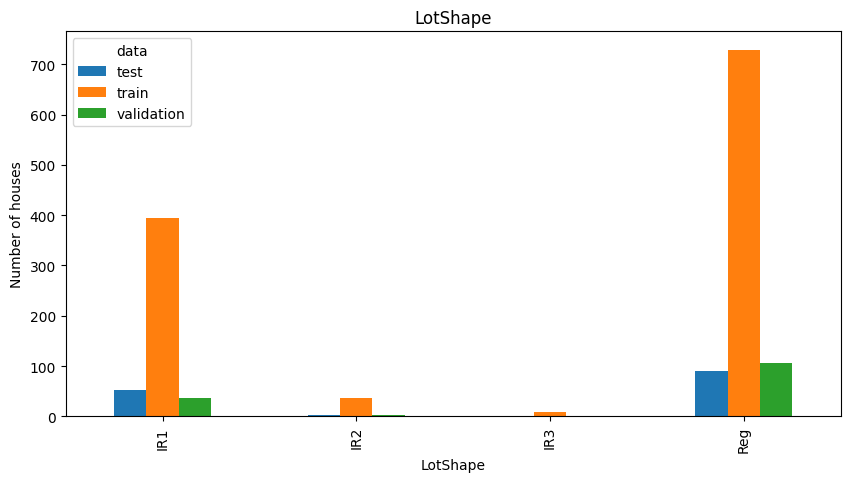

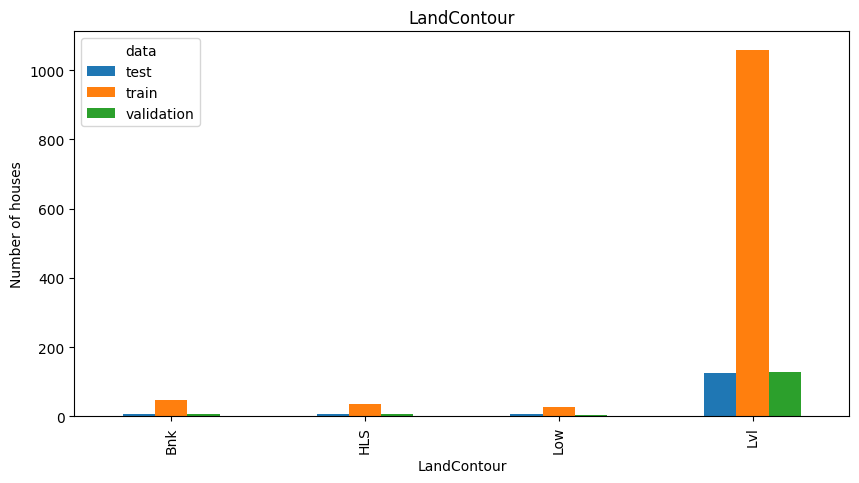

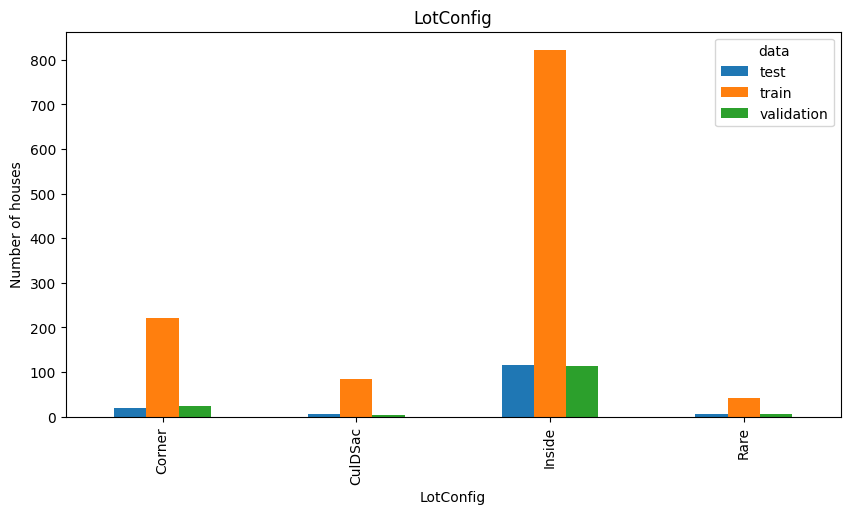

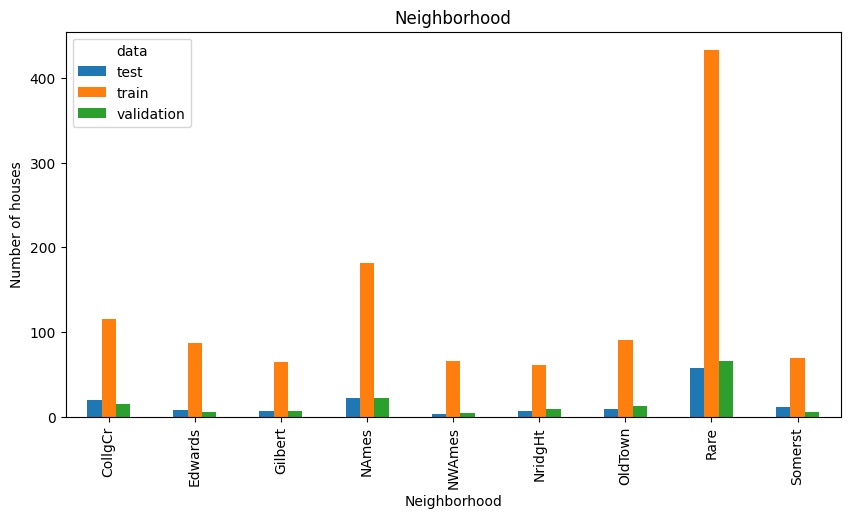

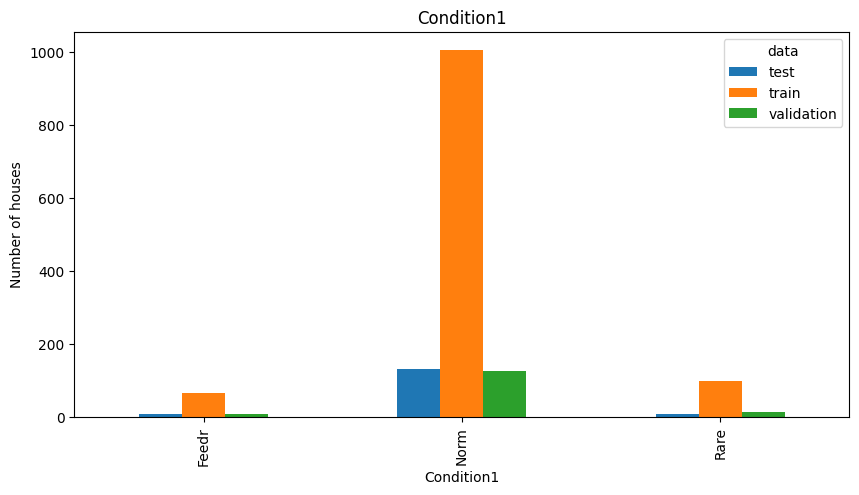

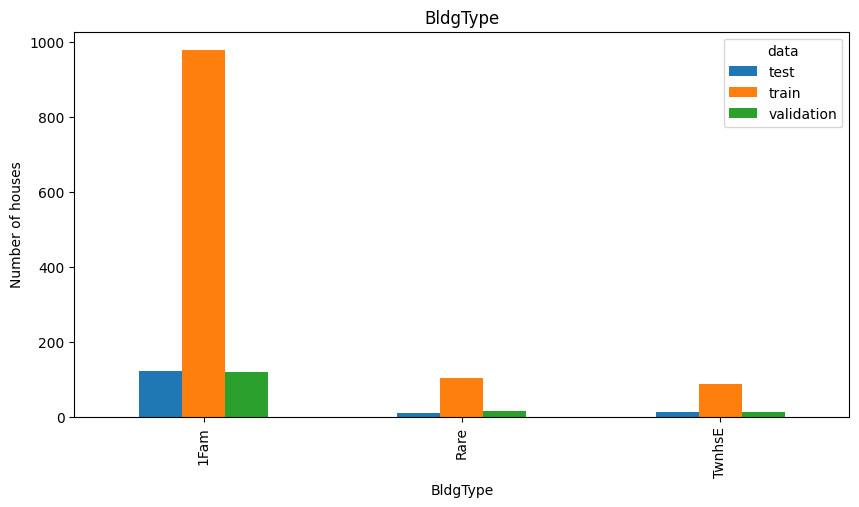

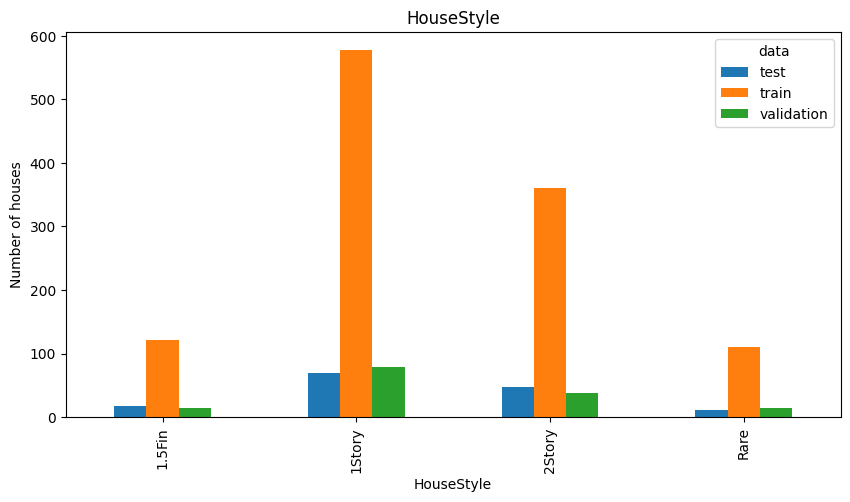

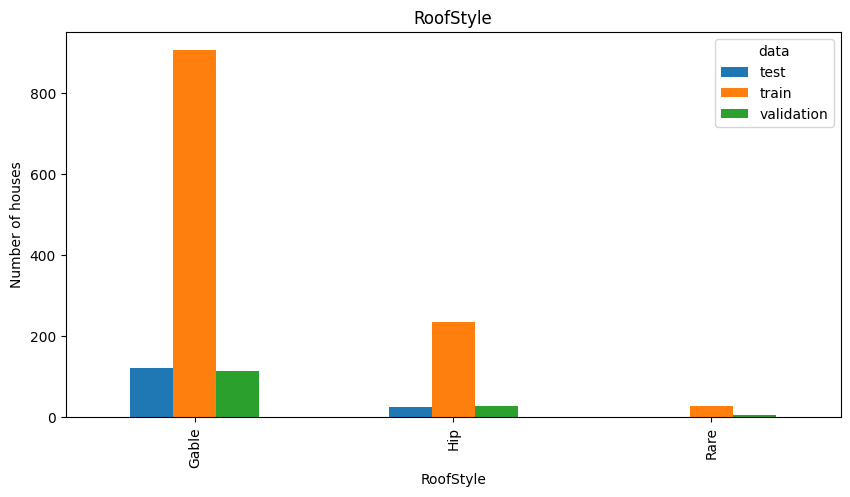

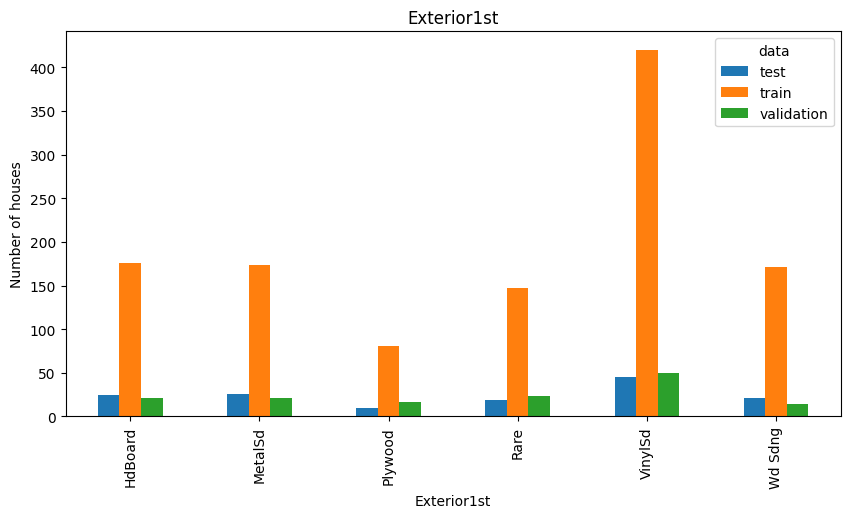

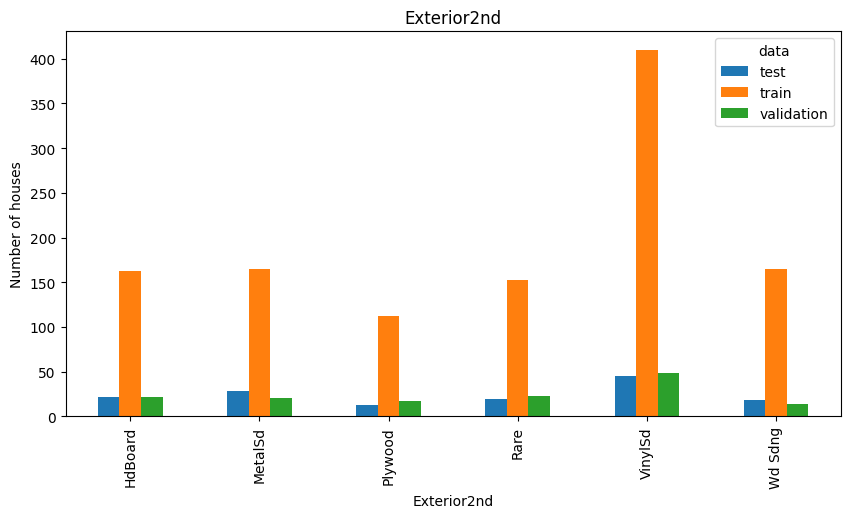

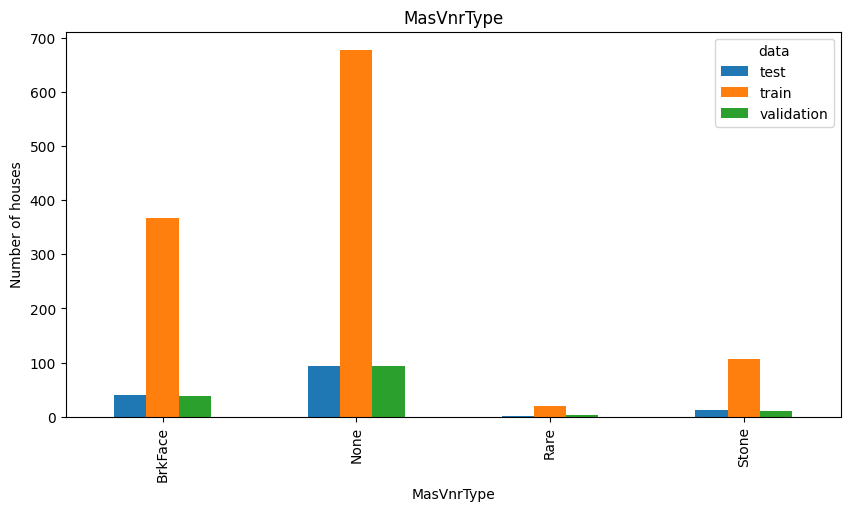

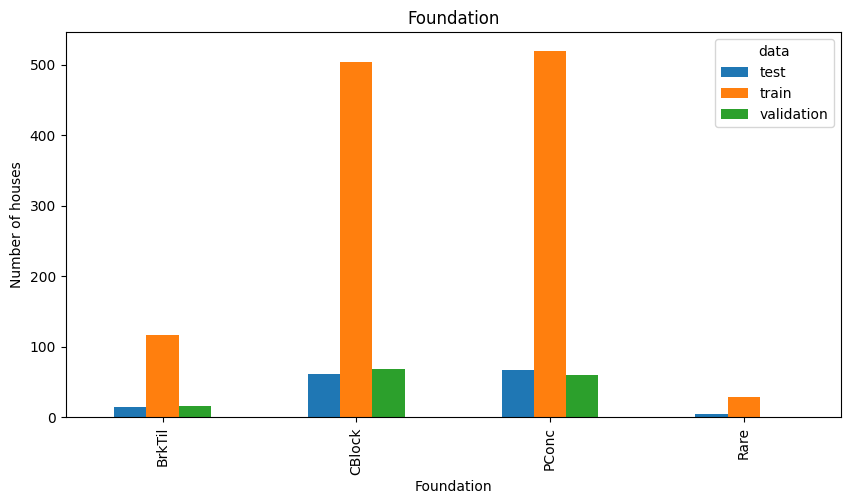

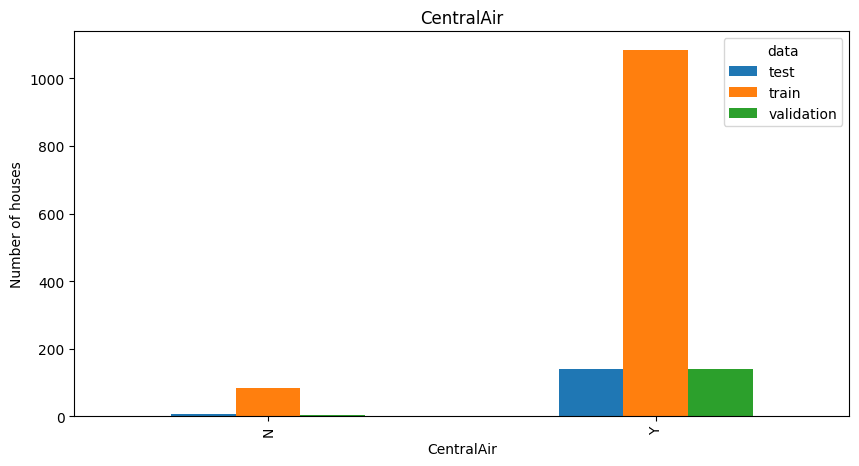

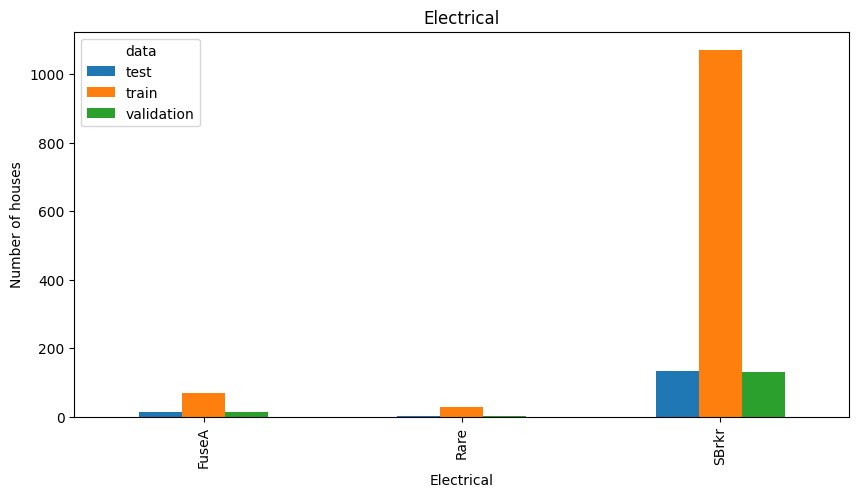

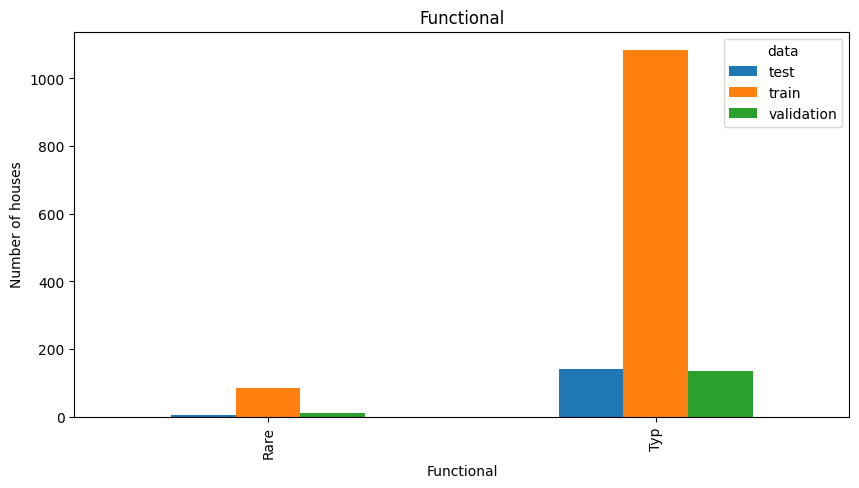

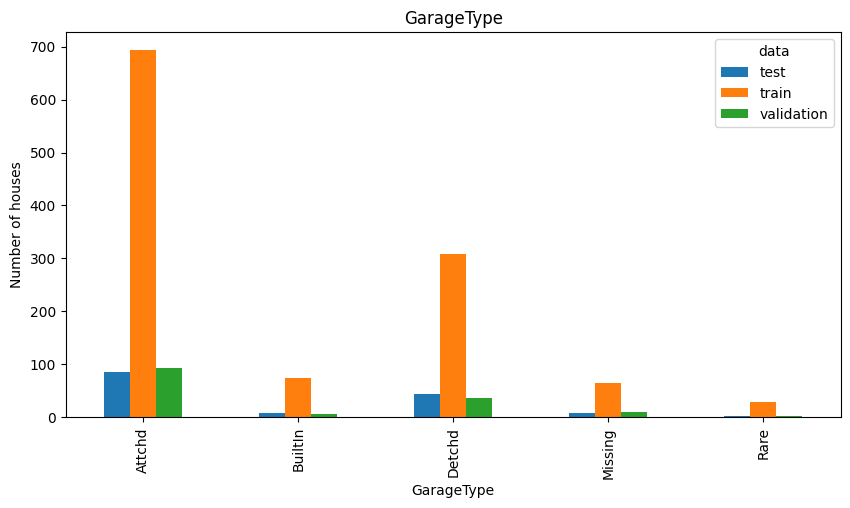

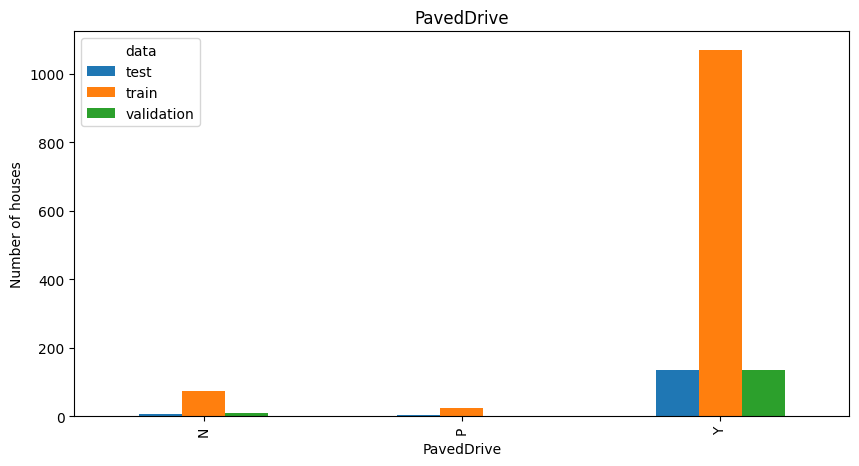

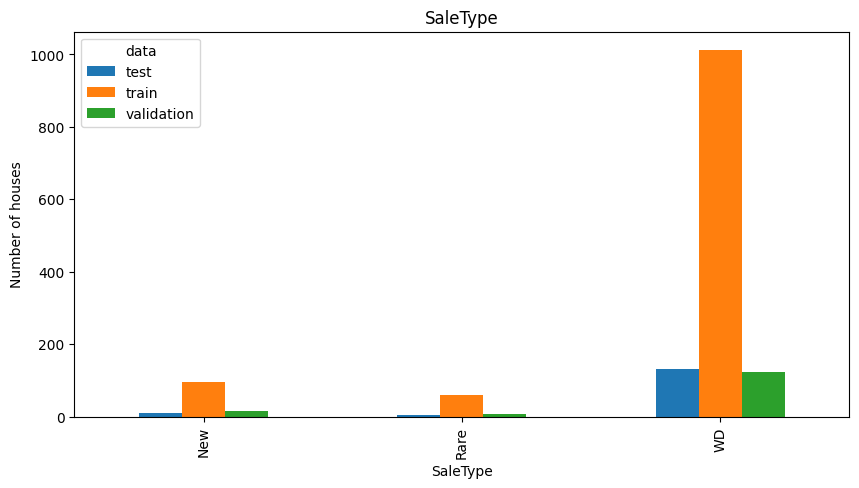

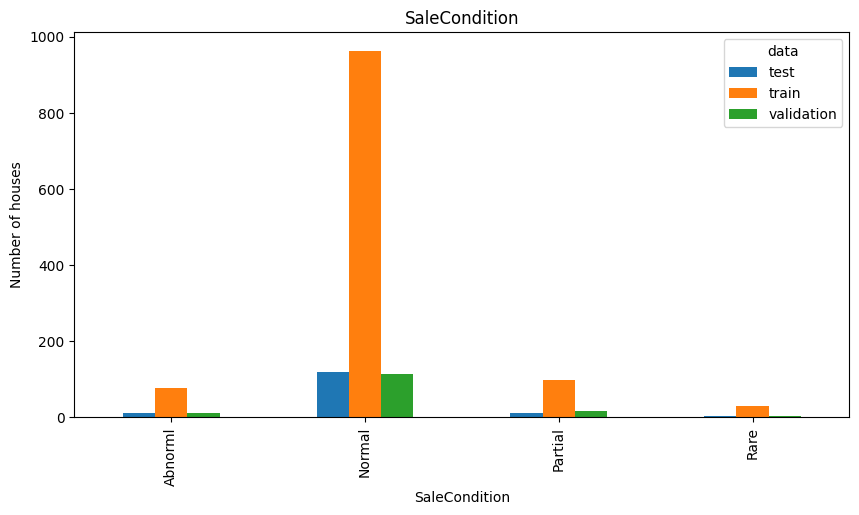

In [ ]:
for variable in categorical:
    data.groupby(variable)['data'].value_counts().unstack().plot.bar(figsize=(10,5))
    plt.title(variable)
    plt.ylabel('Number of houses')
    plt.show()

Nakon grupisanja, imamo kategorije koje se nalaze u sva 3 skupa (train, validation, test) i postoje u više od 5% instanci skupa podataka.

### Važnost kategoričkih varijabli

Iscrtaćemo SalePrice distribuciju za svaku kategoričku varijablu.

Jitter - da se ne preklapaju tačke na grafiku.

Box plot - želimo da vdimo da se box plots različitih kategorija ne preklapaju.

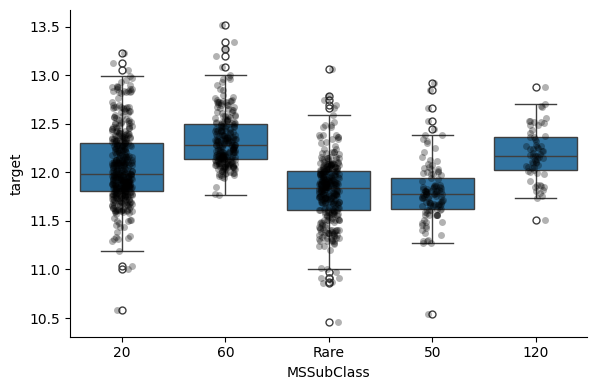

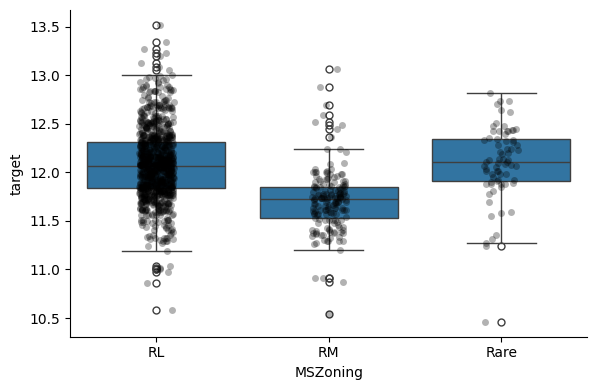

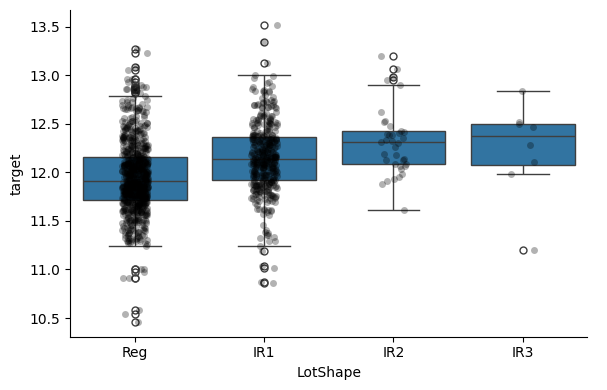

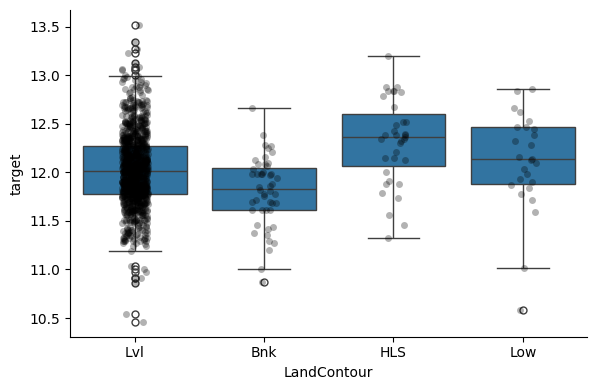

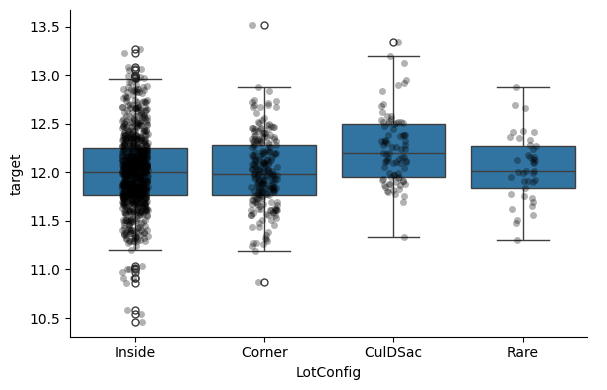

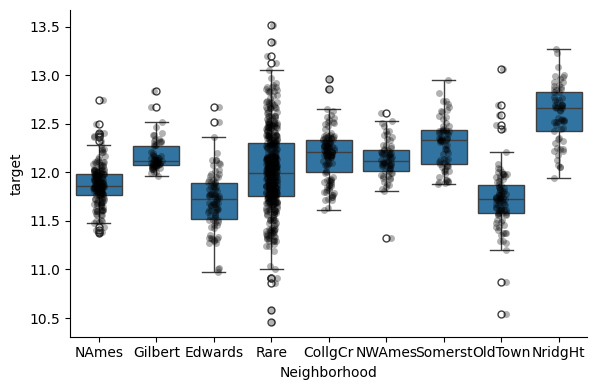

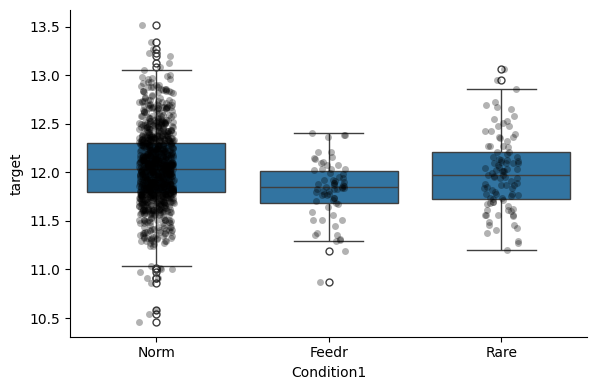

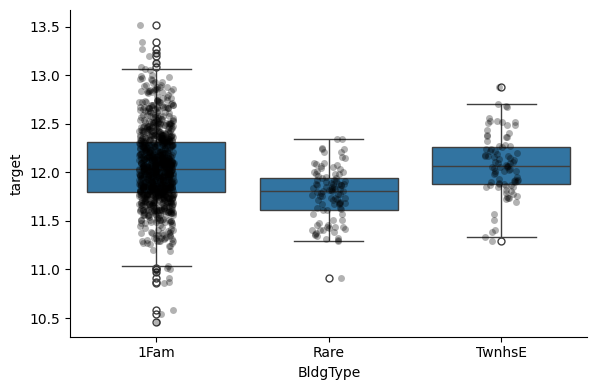

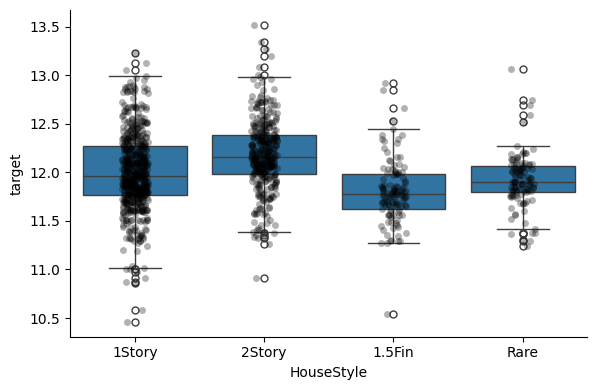

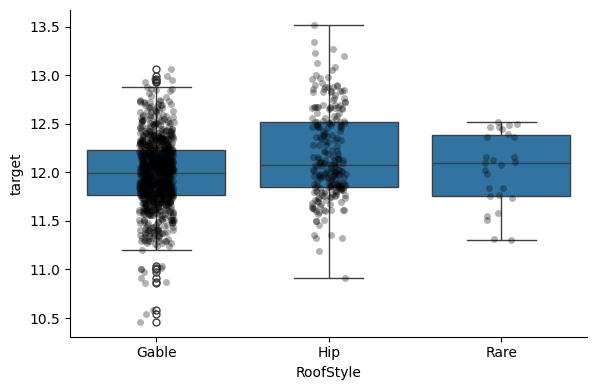

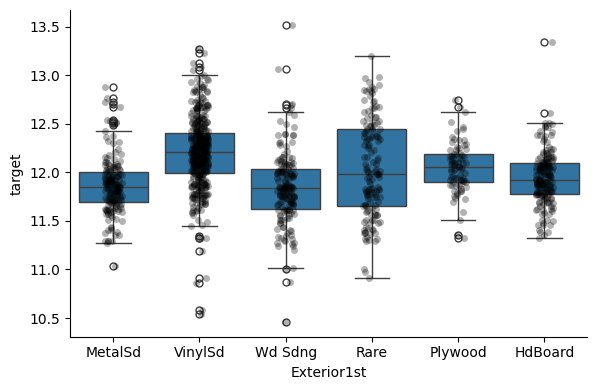

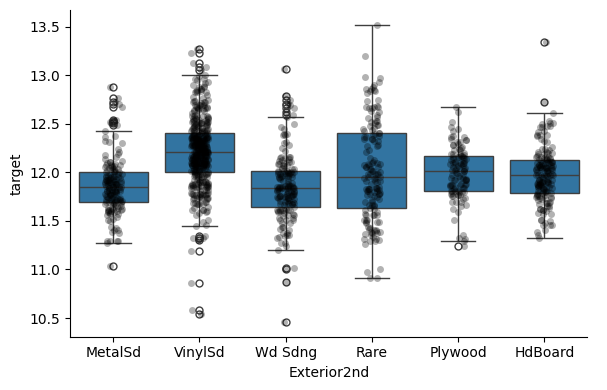

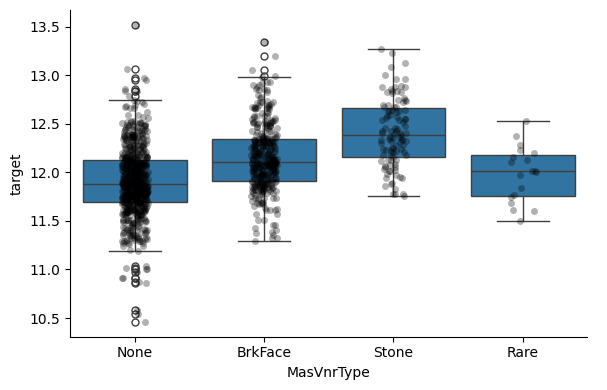

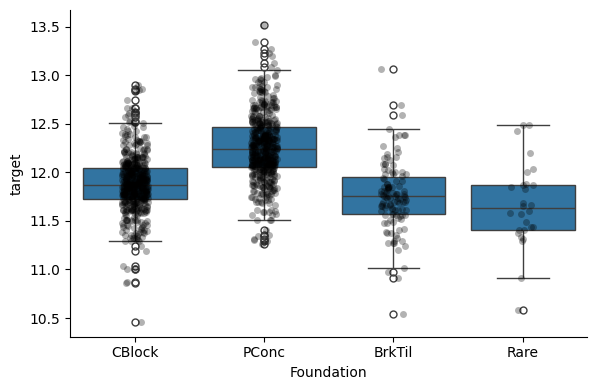

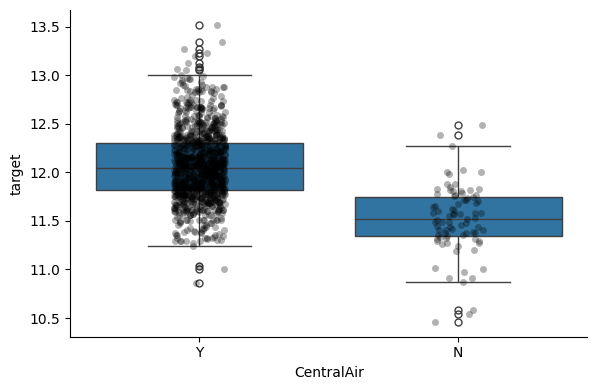

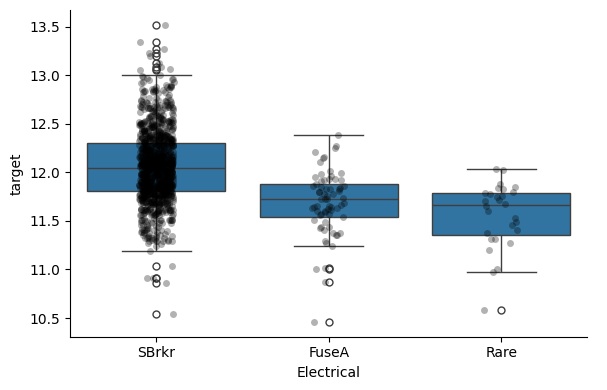

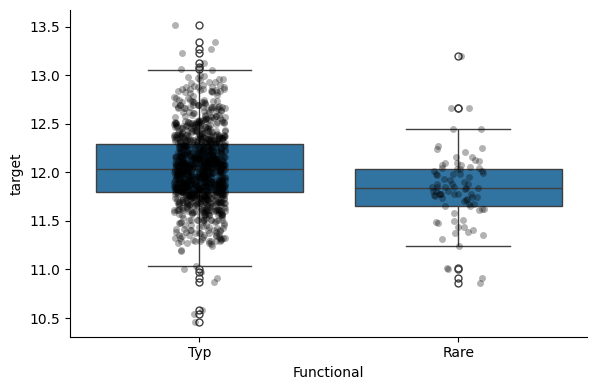

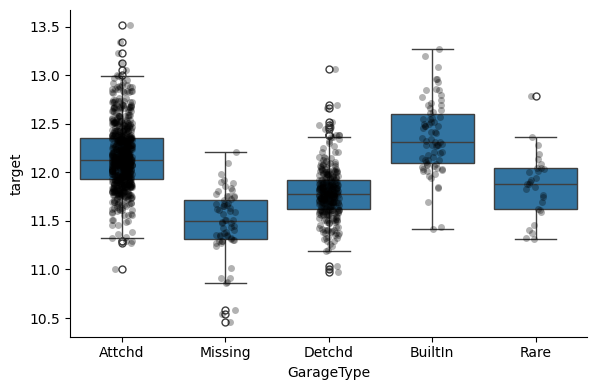

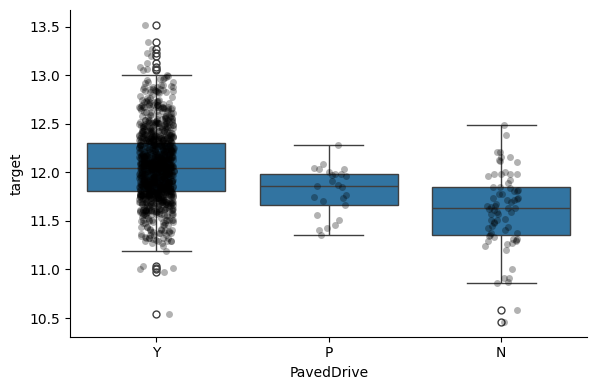

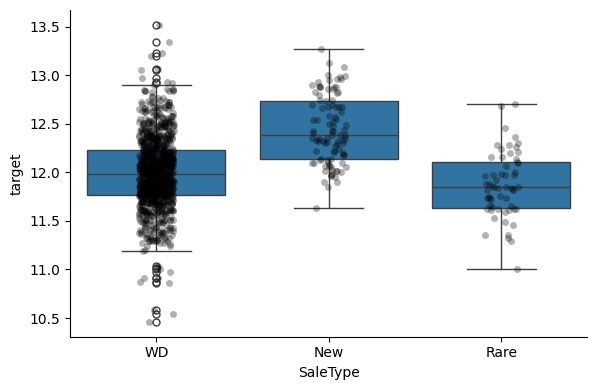

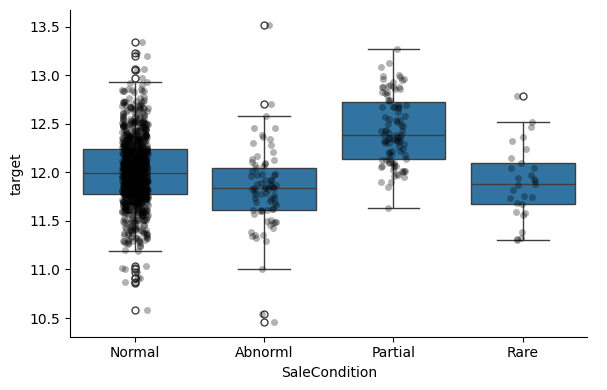

In [ ]:
for variable in categorical:
    # make boxplot with Catplot
    sns.catplot(x=variable, y='target', data=data[data['data']=='train'], kind="box", height=4, aspect=1.5)
    # add data points to boxplot with stripplot
    sns.stripplot(x=variable, y='target', data=data[data['data']=='train'], jitter=0.1, alpha=0.3, color='k')
    plt.show()

Neke kategorije koreliraju sa visokom/niskom cenom nekretnine, dok druge ne. Na primer, "Foundation", "Sale condition" - vidimo razlike u ceni nekretnina.




Jedan (automatski) način da vidimo koje varijable su bitne za predikciju jeste da ih zamenimo sa srednjom vrednošću SalePrice (labele).

For each categorical variable:
* Determines the mean target value per category in the training folds.
* Replaces the categories by the target mean values in the test folds.
* Determines the performance of the transformed variables in the test folds.

In [ ]:
selector = sel.SelectByTargetMeanPerformance(
    variables=categorical, # the variables to examine
    scoring='r2', # the metric to use for the performance evaluation
    threshold=0.1, # the minimum performance threshold for a variable to be selected
    cv=2,
    regression=True)

# find the variables that are important
selector.fit(X_train, y_train)

SelectByTargetMeanPerformance(cv=2, regression=True, scoring='r2',
                              threshold=0.1,
                              variables=['MSSubClass', 'MSZoning', 'LotShape',
                                         'LandContour', 'LotConfig',
                                         'Neighborhood', 'Condition1',
                                         'BldgType', 'HouseStyle', 'RoofStyle',
                                         'Exterior1st', 'Exterior2nd',
                                         'MasVnrType', 'Foundation',
                                         'CentralAir', 'Electrical',
                                         'Functional', 'GarageType',
                                         'PavedDrive', 'SaleType',
                                         'SaleCondition'])

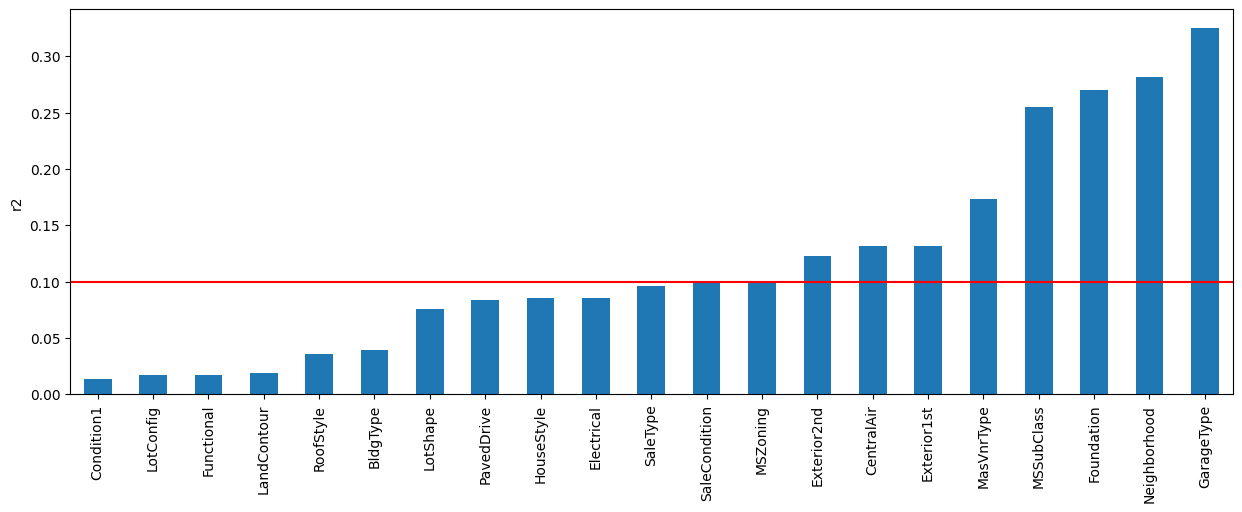

In [ ]:
# in the attribute feature_performance_ the class stores the performance of each feature
pd.Series(selector.feature_performance_).sort_values().plot.bar(figsize=(15,5))
plt.ylabel('r2')

# the red line is the threshold we selected.
plt.axhline(y = 0.1, color = 'r', linestyle = '-')
plt.show()

Možete se "igrati" sa pragom (ovde 0.1) da selektujete više ili manje obeležja. Prag od 0.1 - obeležje objašnjava 10% varijabilnosti u podacima.

In [ ]:
len(selector.features_to_drop_)

12

In [ ]:
# remove non predictive categorical variables
X_train = selector.transform(X_train)
X_val = selector.transform(X_val)
X_test = selector.transform(X_test)

X_train.shape, X_val.shape, X_test.shape

((1168, 70), (146, 70), (146, 70))

### Enkodiranje kategoričkih varijabli

Dodelićemo brojeve kategorijama - brojevi će ići od manjih ka većima, bazirano na srednjoj vrednosti SalePrice (y) u kategoriji. Na ovaj način se nadamo da ćemo kreirati monotonu vezu između enkodirane varijable i y, što može unaprediti performanse modela.

In [ ]:
# let's identify all remaining categorical variables (remember that we encoded some into numbers already)
categorical = [var for var in X_train.columns if X_train[var].dtype == 'O']

# number of categorical variables
len(categorical)

15

In [ ]:
X_train[categorical] = X_train[categorical].astype('O')
X_val[categorical] = X_val[categorical].astype('O')
X_test[categorical] = X_test[categorical].astype('O')

In [ ]:
encoder = enc.OrdinalEncoder(encoding_method='ordered', variables=categorical)
encoder.fit(X_train, y_train)

OrdinalEncoder(variables=['MSSubClass', 'MSZoning', 'Street', 'Utilities',
                          'LandSlope', 'Neighborhood', 'Condition2', 'RoofMatl',
                          'Exterior1st', 'Exterior2nd', 'MasVnrType',
                          'Foundation', 'Heating', 'CentralAir', 'GarageType'])

In [ ]:
# in this attribute we find the numbers that will replace each category in each variable
encoder.encoder_dict_

{'MSSubClass': {50: 0, 'Rare': 1, 20: 2, 120: 3, 60: 4},
 'MSZoning': {'RM': 0, 'RL': 1, 'Rare': 2},
 'Street': {'Other': 0, 'Pave': 1},
 'Utilities': {'Other': 0, 'AllPub': 1},
 'LandSlope': {'Gtl': 0, 'Other': 1},
 'Neighborhood': {'Edwards': 0,
  'OldTown': 1,
  'NAmes': 2,
  'Rare': 3,
  'NWAmes': 4,
  'Gilbert': 5,
  'CollgCr': 6,
  'Somerst': 7,
  'NridgHt': 8},
 'Condition2': {'Other': 0, 'Norm': 1},
 'RoofMatl': {'CompShg': 0, 'Other': 1},
 'Exterior1st': {'Wd Sdng': 0,
  'MetalSd': 1,
  'HdBoard': 2,
  'Rare': 3,
  'Plywood': 4,
  'VinylSd': 5},
 'Exterior2nd': {'Wd Sdng': 0,
  'MetalSd': 1,
  'HdBoard': 2,
  'Plywood': 3,
  'Rare': 4,
  'VinylSd': 5},
 'MasVnrType': {'None': 0, 'Rare': 1, 'BrkFace': 2, 'Stone': 3},
 'Foundation': {'Rare': 0, 'BrkTil': 1, 'CBlock': 2, 'PConc': 3},
 'Heating': {'Other': 0, 'GasA': 1},
 'CentralAir': {'N': 0, 'Y': 1},
 'GarageType': {'Missing': 0,
  'Detchd': 1,
  'Rare': 2,
  'Attchd': 3,
  'BuiltIn': 4}}

In [ ]:
X_train = encoder.transform(X_train)
X_val = encoder.transform(X_val)
X_test = encoder.transform(X_test)

X_train.shape, X_val.shape, X_test.shape

((1168, 70), (146, 70), (146, 70))

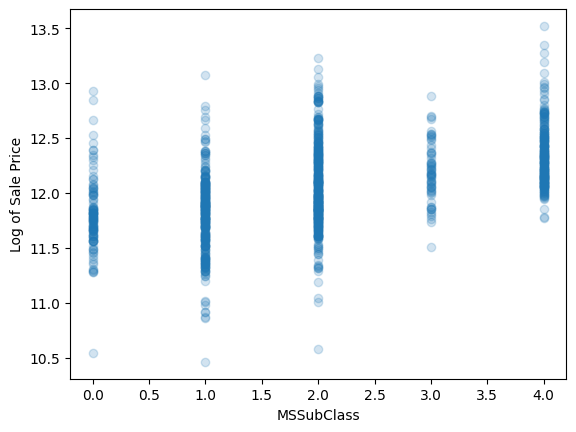

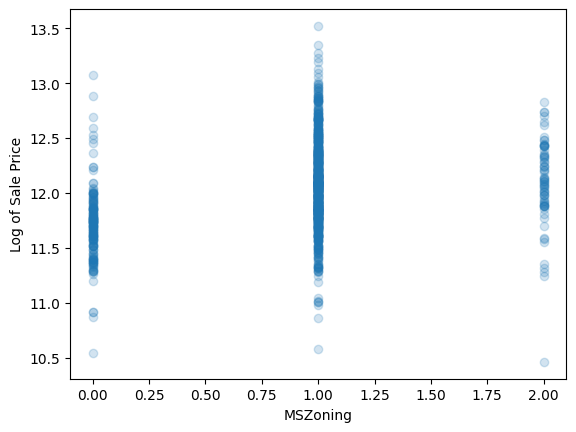

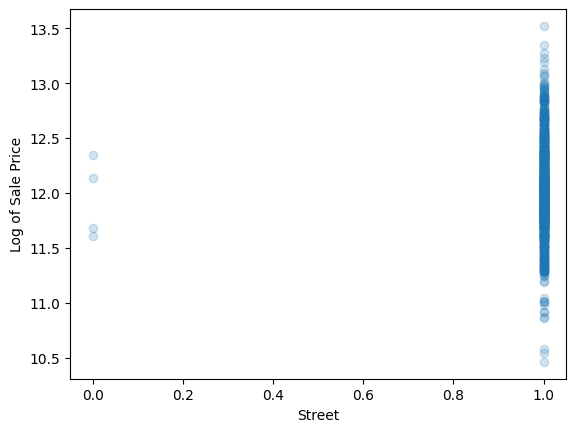

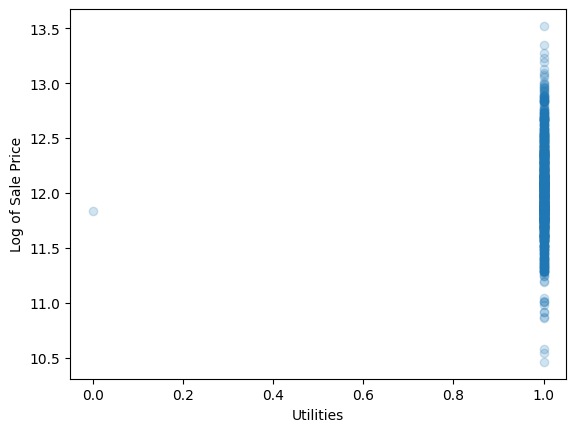

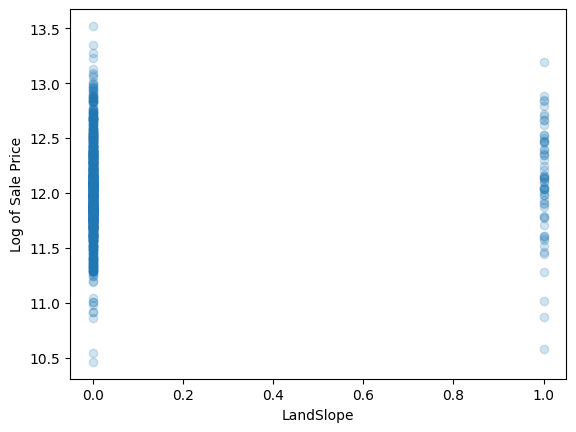

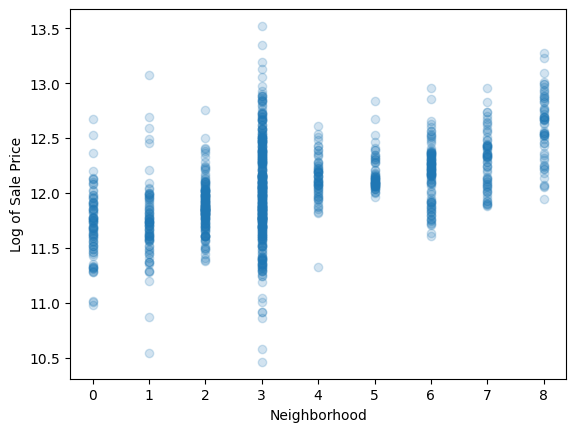

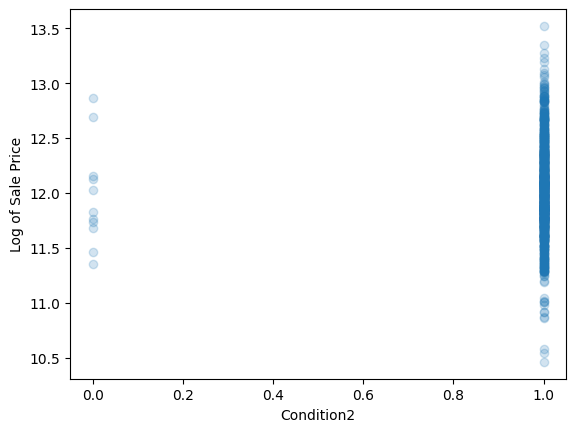

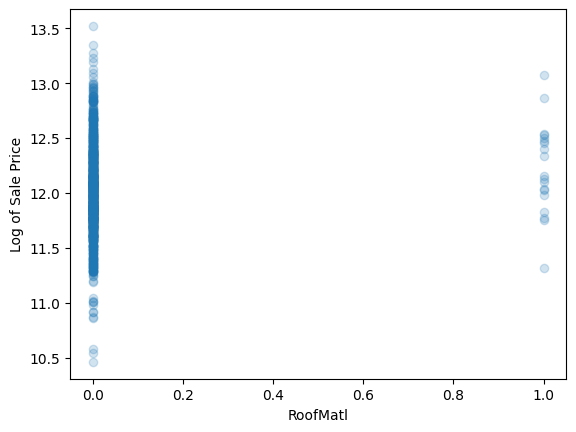

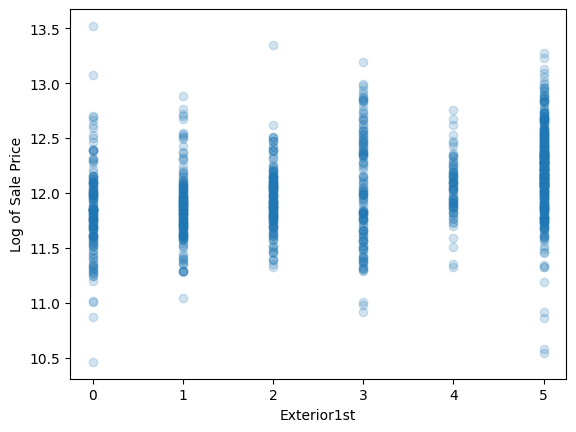

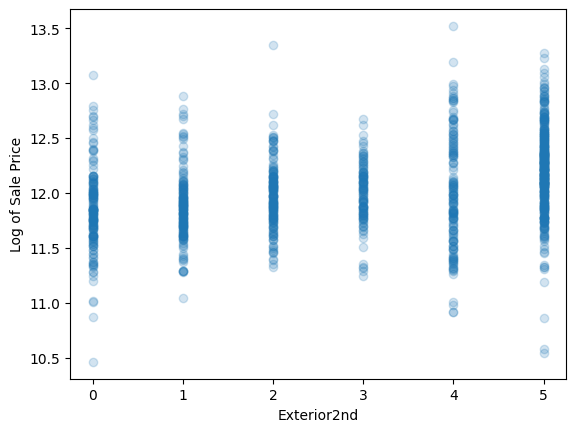

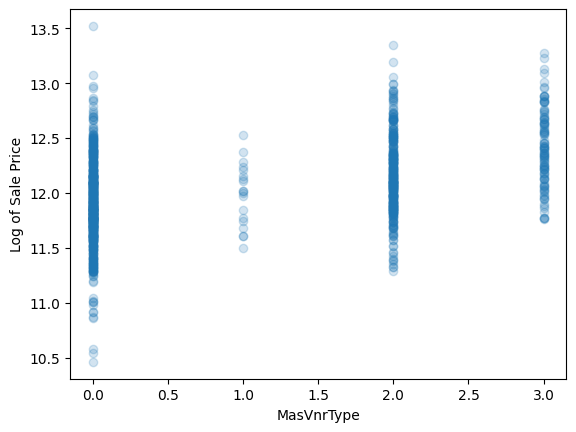

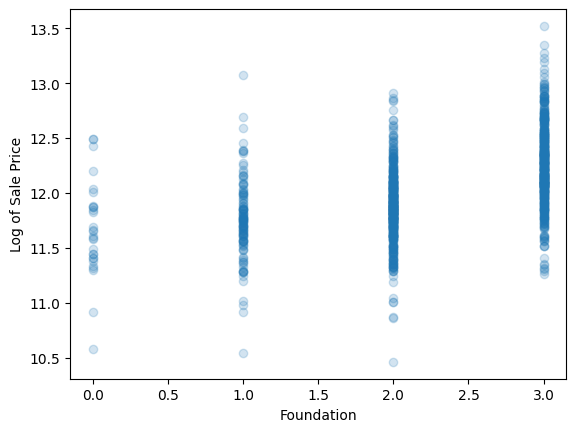

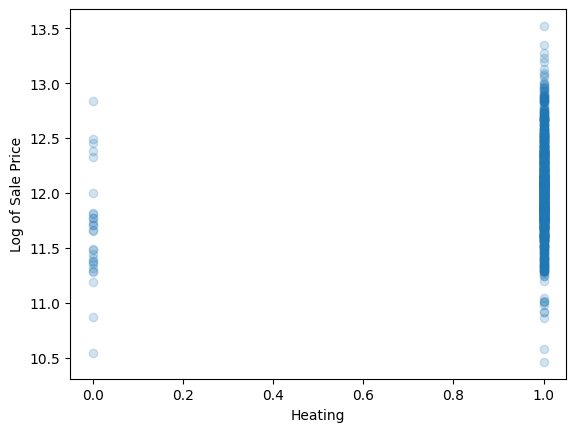

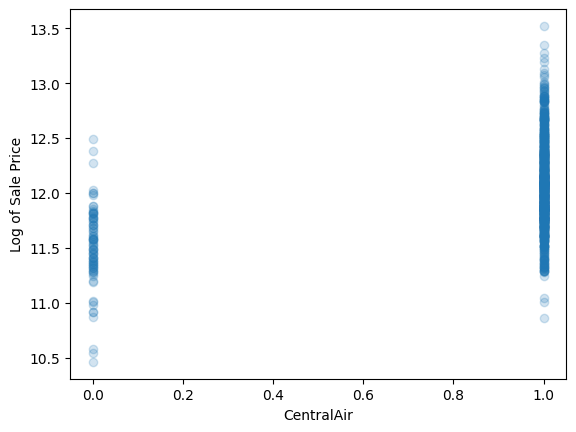

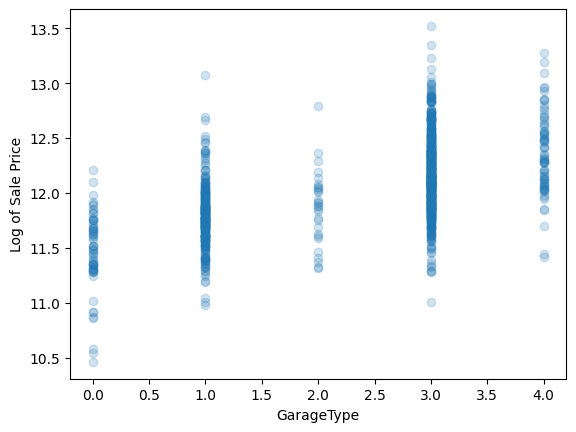

In [ ]:
# Now let's examine the monotonic relationships
for var in categorical:
    plt.scatter(X_train[var], y_train, alpha=0.2)
    plt.ylabel('Log of Sale Price')
    plt.xlabel(var)
    plt.show()

Za određene varijable vidimo porast cene nekretnine sa leva na desno (sa porastom vrednosti enkodirane varijable)

In [ ]:
# check that NAN were not introduced during the encoding
[c for c in categorical if X_train[c].isnull().sum()>0]

[]

In [ ]:
# check that NAN were not introduced during the encoding
[c for c in categorical if X_test[c].isnull().sum()>0]

[]

In [ ]:
[c for c in categorical if X_val[c].isnull().sum()>0]

[]

### Vremenske varijable

Na primer, godina prodaje kuće, godina kada je garaža izgrađena.

In [ ]:
year_vars = [var for var in data.columns if 'Yr' in var or 'Year' in var]
year_vars

['YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'YrSold']

Iscrtaćemo cene nekretnina tokom godina.

In [ ]:
data = create_master_data(X_train, X_val, X_test, y_train, y_val, y_test)

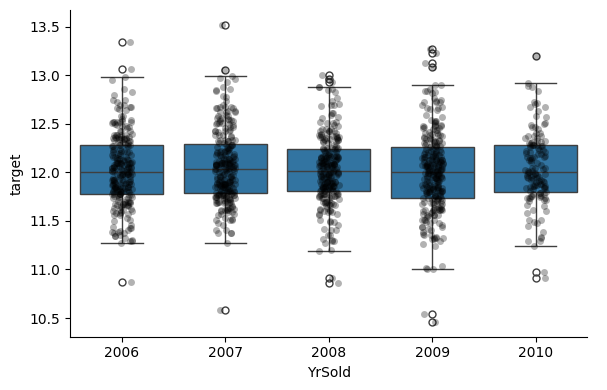

In [ ]:
# make boxplot with Catplot
sns.catplot(x='YrSold', y='target', data=data[data['data']=='train'], kind="box", height=4, aspect=1.5)
# add data points to boxplot with stripplot
sns.stripplot(x='YrSold', y='target', data=data[data['data']=='train'], jitter=0.1, alpha=0.3, color='k')
plt.show()

Vidimo da su cene nekretnina stabilne preko godina za koje imamo podatke.

Hajde da vidimo cene nekretnina naspram toga kada je kuća bila renovirana. Očekujemo veće cene nedavno renoviranih nekretnina.

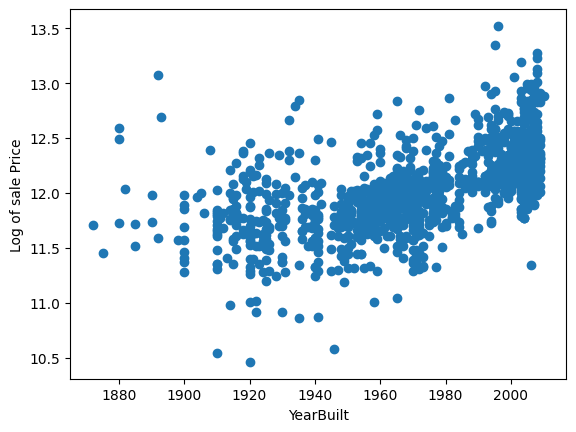

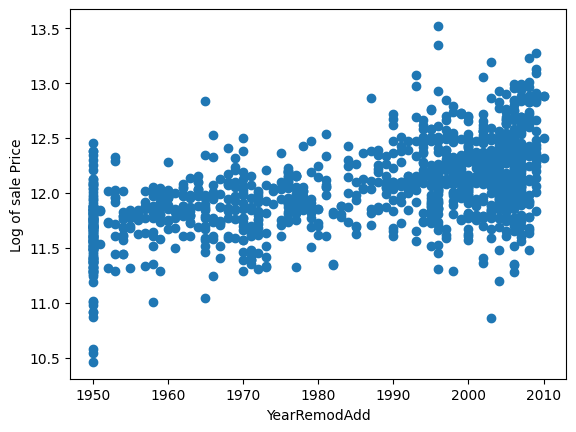

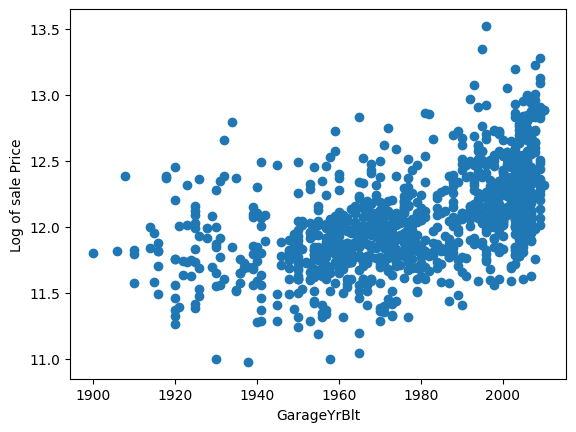

In [ ]:
for variable in ['YearBuilt', 'YearRemodAdd', 'GarageYrBlt']:
    plt.scatter(X_train[variable], y_train)
    plt.ylabel('Log of sale Price')
    plt.xlabel(variable)
    plt.show()

Izgleda da postoji određeni linearni trend porasta cene nekretnina za kuće koje su renovirane u kasnijim godinama. Pokušaćemo da uhvatimo razlike između godine u kojoj je nešto bilo renovirano ili izgrađeno i vremena prodaje.

In [ ]:
from feature_engine import creation

# this transformer will substract all the variables in the reference list, from YrSold
# to determine the age of remodelling at point of sale
create = creation.RelativeFeatures(
    variables = ['YrSold'],
    reference = ['YearBuilt', 'YearRemodAdd', 'GarageYrBlt'],
    func=['sub'],
)

create.fit(X_train)

RelativeFeatures(func=['sub'],
                 reference=['YearBuilt', 'YearRemodAdd', 'GarageYrBlt'],
                 variables=['YrSold'])

In [ ]:
X_train = create.transform(X_train)
X_val = create.transform(X_val)
X_test = create.transform(X_test)

X_train.shape, X_val.shape, X_test.shape

((1168, 73), (146, 73), (146, 73))

In [ ]:
# we can see the new variables at the right of the dataframe
X_train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Utilities,LandSlope,Neighborhood,Condition2,...,MoSold,YrSold,HasPool,HasAlley,Condition_total,Exterior_total,Neigh_Price,YrSold_sub_YearBuilt,YrSold_sub_YearRemodAdd,YrSold_sub_GarageYrBlt
254,255,2,1,70.0,8400,1,1,0,2,1,...,6,2010,0,0,0,0,1,53,53,53.0
1066,1067,4,1,59.0,7837,1,1,0,5,1,...,5,2009,0,0,0,0,1,16,15,16.0
638,639,1,1,67.0,8777,1,1,0,0,1,...,5,2008,0,0,1,1,0,98,58,NaN
799,800,0,1,60.0,7200,1,1,0,3,1,...,6,2007,0,0,1,0,1,70,57,68.0
380,381,0,1,50.0,5000,1,1,0,3,1,...,5,2010,0,1,0,1,1,86,60,86.0


In [ ]:
# if the variable 'YearRemodAdd' shows the same value as the # variable 'YearBuilt', that means that the house has not been remodelled
# so let's create a new feature that captures this.

remodelled = creation.RelativeFeatures(
    variables = ['YearRemodAdd'],
    reference = ['YearBuilt'],
    func=['sub'],
)

remodelled.fit(X_train)

RelativeFeatures(func=['sub'], reference=['YearBuilt'],
                 variables=['YearRemodAdd'])

In [ ]:
X_train = remodelled.transform(X_train)
X_val = remodelled.transform(X_val)
X_test = remodelled.transform(X_test)

X_train.shape, X_val.shape, X_test.shape

((1168, 74), (146, 74), (146, 74))

In [ ]:
# we can see the new variable at the right of the dataframe
X_train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Utilities,LandSlope,Neighborhood,Condition2,...,YrSold,HasPool,HasAlley,Condition_total,Exterior_total,Neigh_Price,YrSold_sub_YearBuilt,YrSold_sub_YearRemodAdd,YrSold_sub_GarageYrBlt,YearRemodAdd_sub_YearBuilt
254,255,2,1,70.0,8400,1,1,0,2,1,...,2010,0,0,0,0,1,53,53,53.0,0
1066,1067,4,1,59.0,7837,1,1,0,5,1,...,2009,0,0,0,0,1,16,15,16.0,1
638,639,1,1,67.0,8777,1,1,0,0,1,...,2008,0,0,1,1,0,98,58,NaN,40
799,800,0,1,60.0,7200,1,1,0,3,1,...,2007,0,0,1,0,1,70,57,68.0,13
380,381,0,1,50.0,5000,1,1,0,3,1,...,2010,0,1,0,1,1,86,60,86.0,26


In [ ]:
# now we need to remove the original time features
drop_features = sel.DropFeatures(features_to_drop =['YearBuilt', 'YearRemodAdd', 'GarageYrBlt','YrSold'])

X_train = drop_features.fit_transform(X_train)
X_val = drop_features.transform(X_val)
X_test = drop_features.transform(X_test)

X_train.shape, X_val.shape, X_test.shape

((1168, 70), (146, 70), (146, 70))

Nedostajuće vrednosti:

In [ ]:
# let's check if the variables have missing data
X_train[[
    'YrSold_sub_YearBuilt', 'YrSold_sub_YearRemodAdd' ,'YrSold_sub_GarageYrBlt', 'YearRemodAdd_sub_YearBuilt']
].isnull().mean()

YrSold_sub_YearBuilt          0.000000
YrSold_sub_YearRemodAdd       0.000000
YrSold_sub_GarageYrBlt        0.054795
YearRemodAdd_sub_YearBuilt    0.000000
dtype: float64

In [ ]:
X_test[[
    'YrSold_sub_YearBuilt', 'YrSold_sub_YearRemodAdd' ,'YrSold_sub_GarageYrBlt', 'YearRemodAdd_sub_YearBuilt']
].isnull().mean()

YrSold_sub_YearBuilt          0.000000
YrSold_sub_YearRemodAdd       0.000000
YrSold_sub_GarageYrBlt        0.047945
YearRemodAdd_sub_YearBuilt    0.000000
dtype: float64

In [ ]:
X_val[[
    'YrSold_sub_YearBuilt', 'YrSold_sub_YearRemodAdd' ,'YrSold_sub_GarageYrBlt', 'YearRemodAdd_sub_YearBuilt']
].isnull().mean()

YrSold_sub_YearBuilt          0.000000
YrSold_sub_YearRemodAdd       0.000000
YrSold_sub_GarageYrBlt        0.068493
YearRemodAdd_sub_YearBuilt    0.000000
dtype: float64

YrSold_sub_GarageYrBlt sadrži nedostajuće vrednosti. Imputiraćemo ih kasnije sa svim ostalim numeričkim varijablama.

Konačna vremenska varijabla je mesec u kom je nekretnina prodata. Proverićemo da li postoji neka veza između te varijable i cene nekretnine:

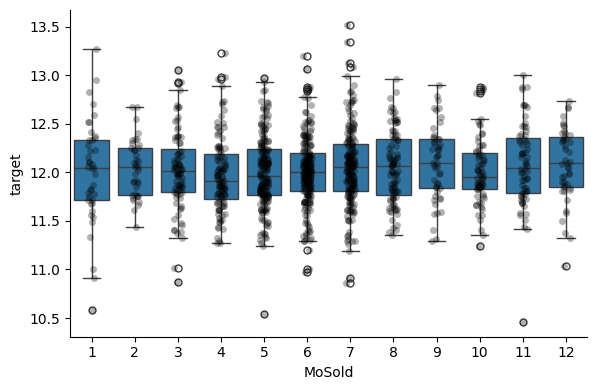

In [ ]:
# make boxplot with Catplot
sns.catplot(x='MoSold', y='target', data=data[data['data']=='train'], kind="box", height=4, aspect=1.5)
# add data points to boxplot with stripplot
sns.stripplot(x='MoSold', y='target', data=data[data['data']=='train'], jitter=0.1, alpha=0.3, color='k')
plt.show()

Srednja vrednost nekretnine izgleda slična, gledano kroz mesece. Međutim, postoji razlika u broju prodatih nekretnina (manje nekretnina se proda u januaru i februaru, dok se više nekretnina proda u letnjim mesecima).

### Nominalne varijable
(za razliku od kategoričkih nemaju ordering)

In [ ]:
discrete = [
    var for var in X_train.columns if X_train[var].dtype != 'O'
    and var not in year_vars
    and var not in qual_vars+categorical
    and len(X_train[var].unique()) < 20
]

# number of discrete variables
len(discrete)

20

Proverićemo vezu sa vrednostima ovih varijabli i cene nekretnine.

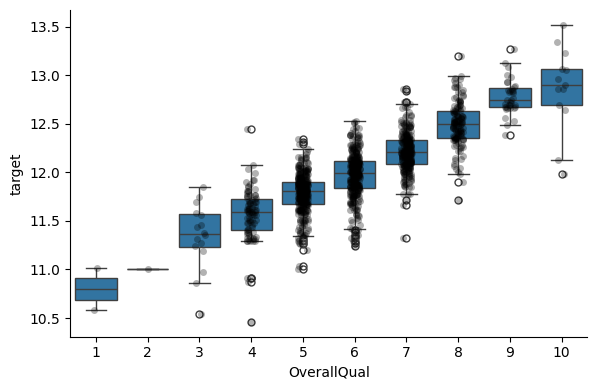

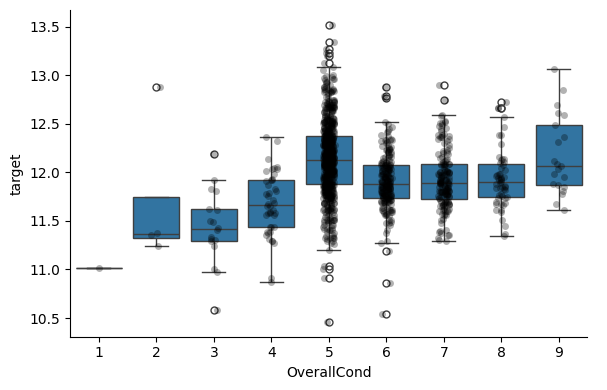

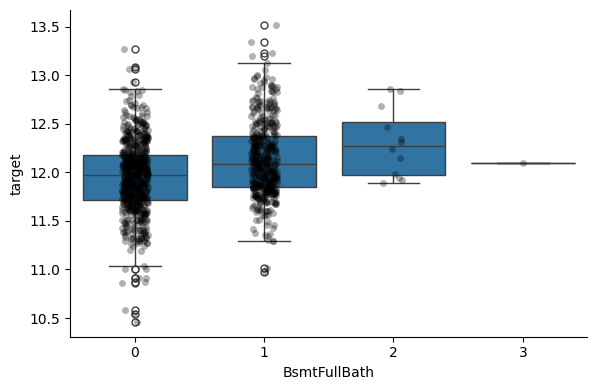

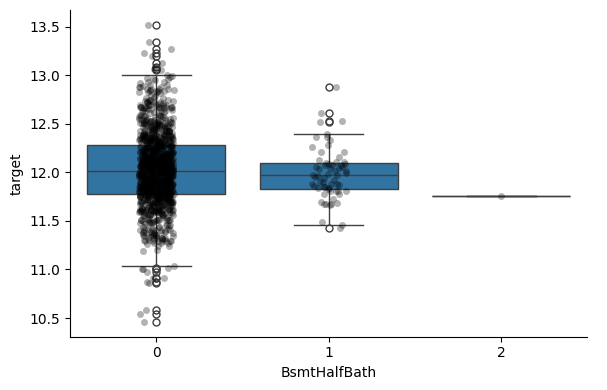

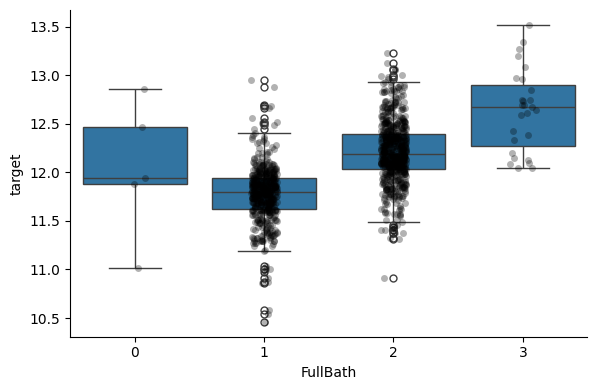

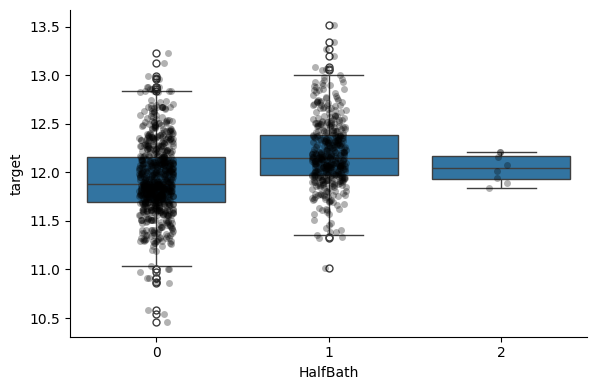

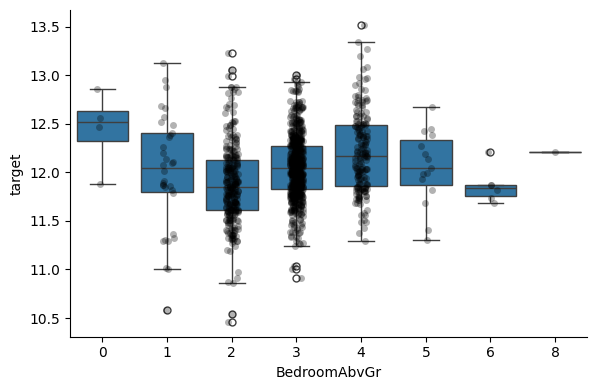

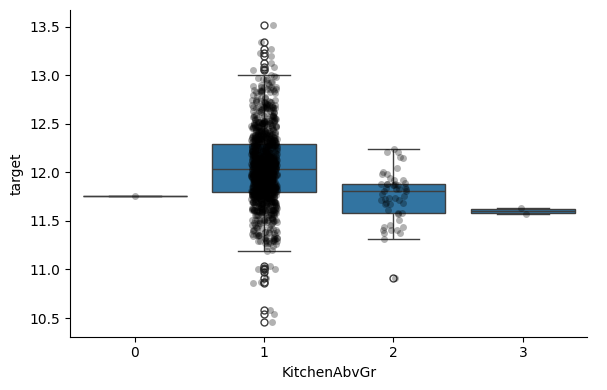

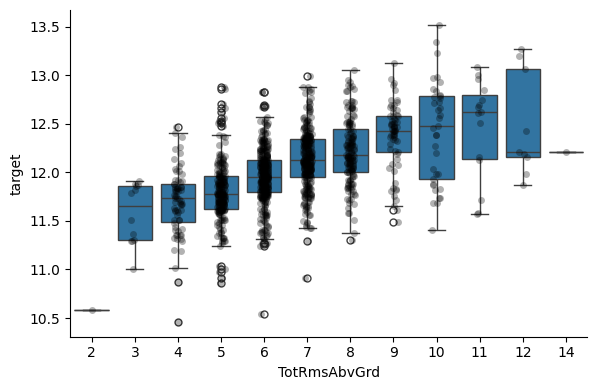

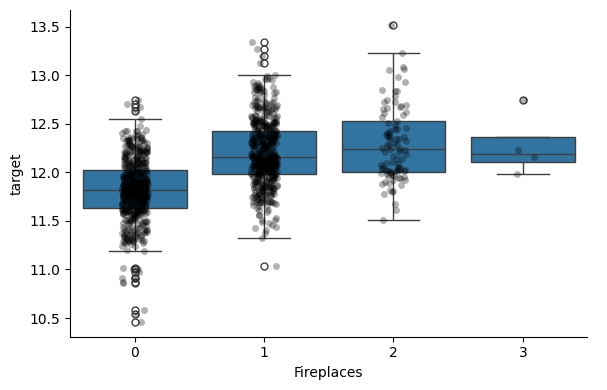

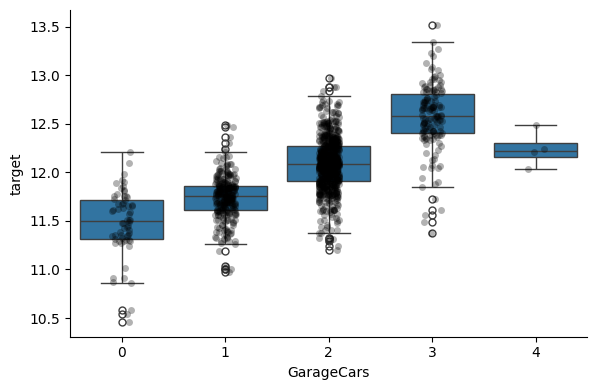

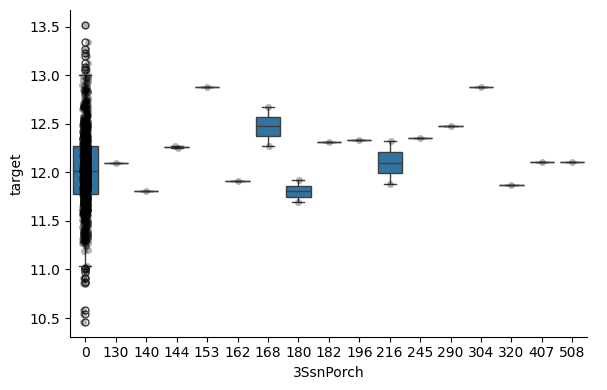

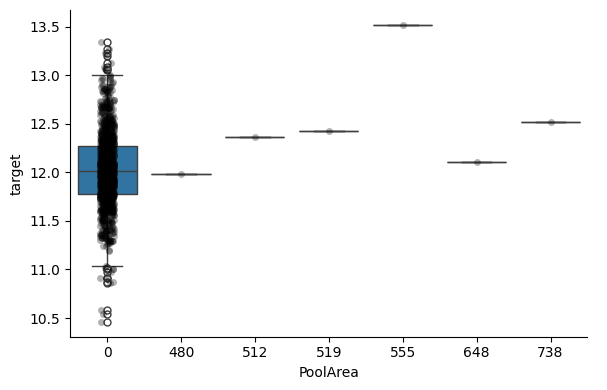

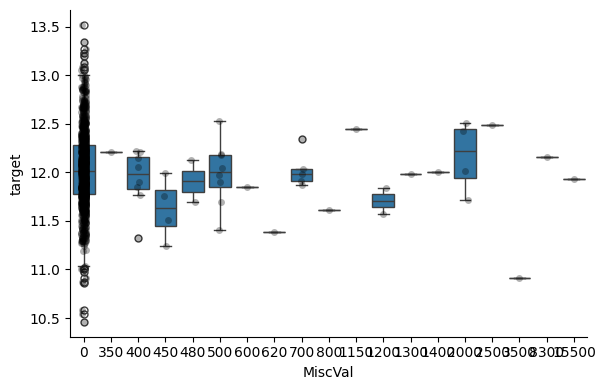

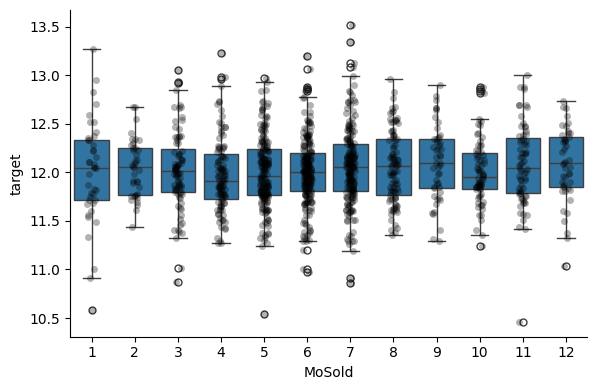

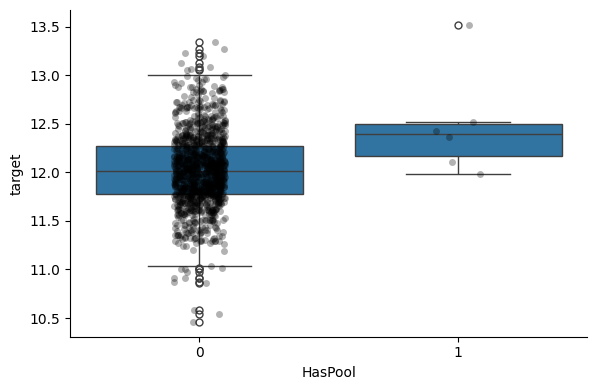

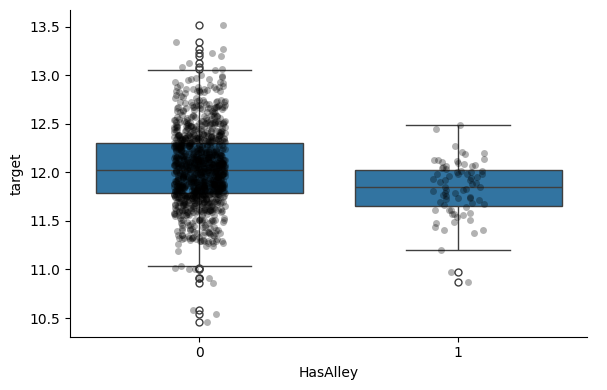

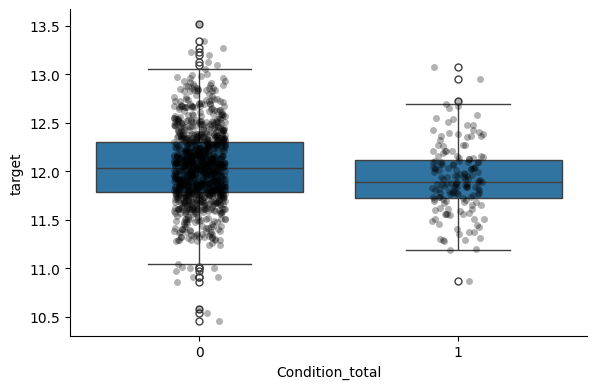

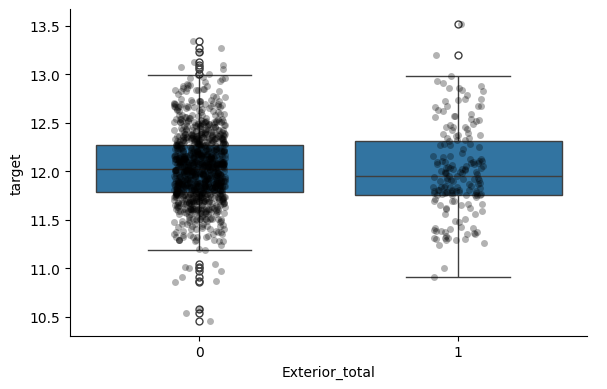

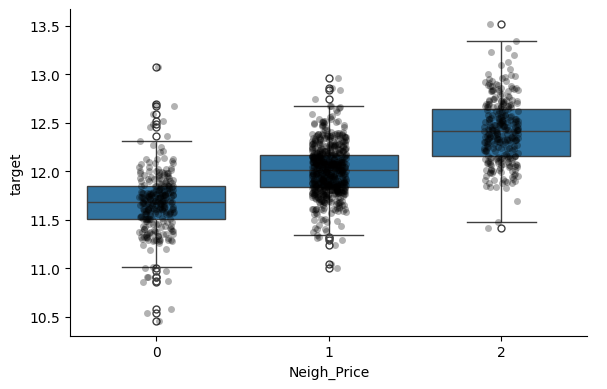

In [ ]:
for var in discrete:
    # make boxplot with Catplot
    sns.catplot(x=var, y='target', data=data[data['data']=='train'], kind="box", height=4, aspect=1.5)
    # add data points to boxplot with stripplot
    sns.stripplot(x=var, y='target', data=data[data['data']=='train'], jitter=0.1, alpha=0.3, color='k')
    plt.show()

Za većinu ovih varijabli postoji korelacija između dodeljenog broja i cene nekretnine. Naročito za varijable gde je čovek dodelio vrednost (OverallQual, OverallCond). Međutim, postoji i za broj soba i kupatila.

Jedina varijabla koja ima samo jednu dominantnu vrednost je PoolArea - nju ćemo ukloniti iz skupa podataka.

In [ ]:
# remove original feature

drop_features = sel.DropFeatures(features_to_drop =['PoolArea'])

X_train = drop_features.fit_transform(X_train)
X_test = drop_features.transform(X_test)
X_val = drop_features.transform(X_val)

X_train.shape, X_val.shape, X_test.shape

((1168, 69), (146, 69), (146, 69))

Nedostajući podaci

In [ ]:
null_disc = {var: data[var].isnull().mean() for var in discrete if data[var].isnull().mean()>0}
null_disc

{}

### Numeričke varijable

In [ ]:
numerical = [
    var for var in X_train.columns
    if var not in categorical + qual_vars + discrete + year_vars
]

len(numerical)

21

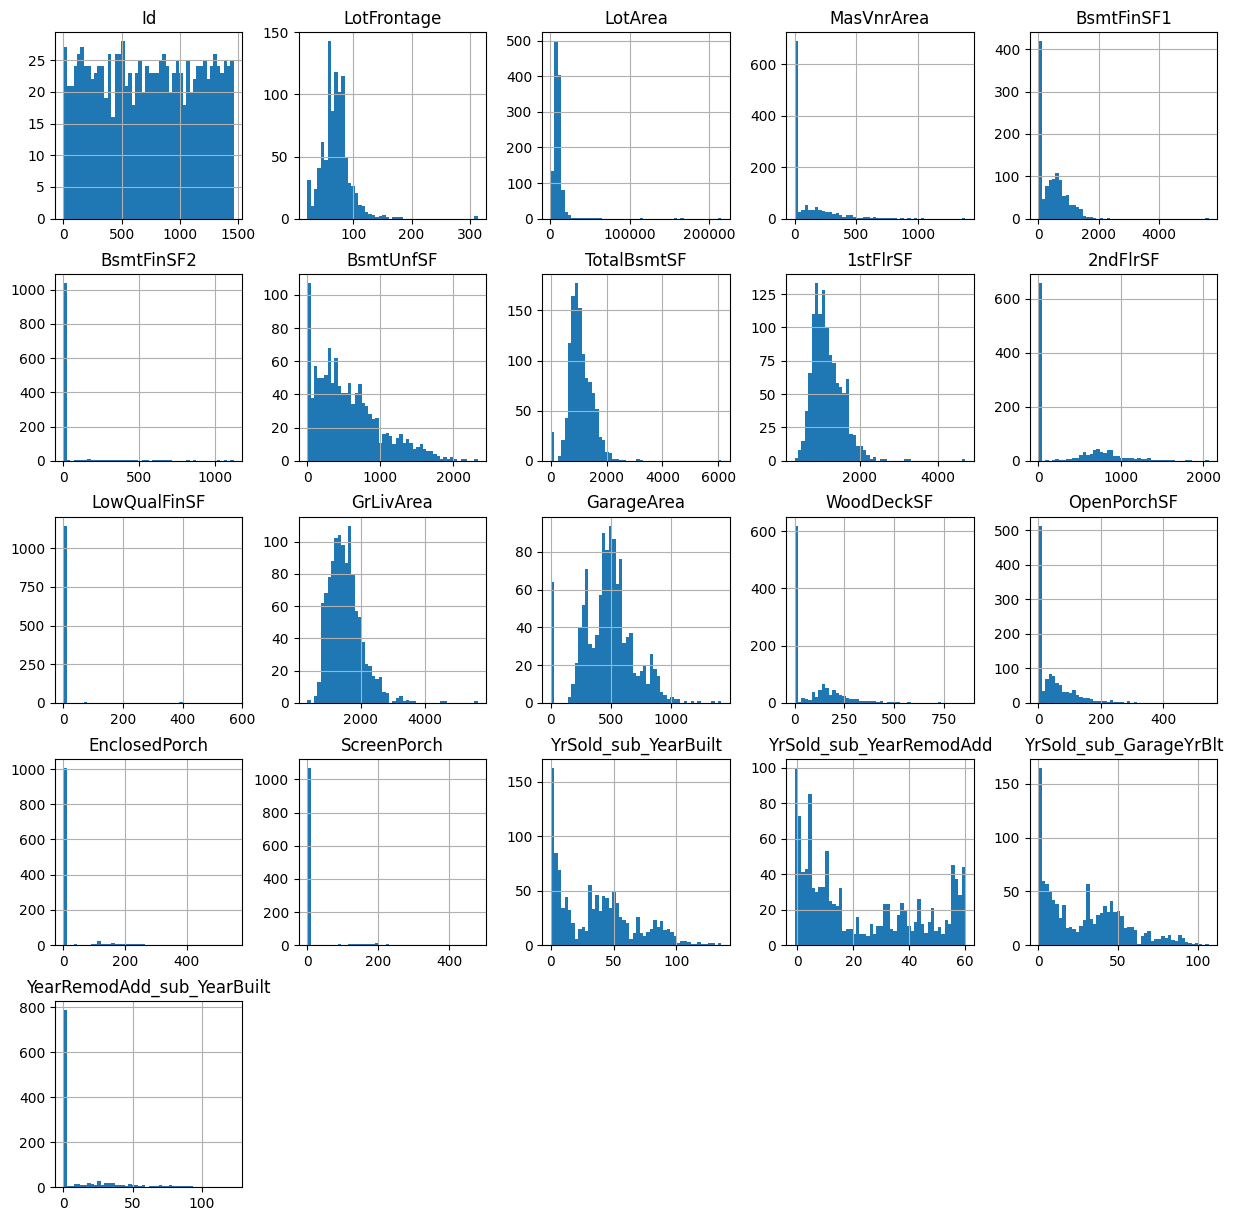

In [ ]:
# let's examine the distribution of the numerical continuous variables
X_train[numerical].hist(bins=50, figsize=(15,15))
plt.show()

Postoje neke varijable koje imaju jednu dominantnu vrednost (MiscVal, ScreenPorch, LowQualFinSF). Možemo ih ukloniti sa *constant features selector* ili možemo pustiti model da odluči da li su bitne.

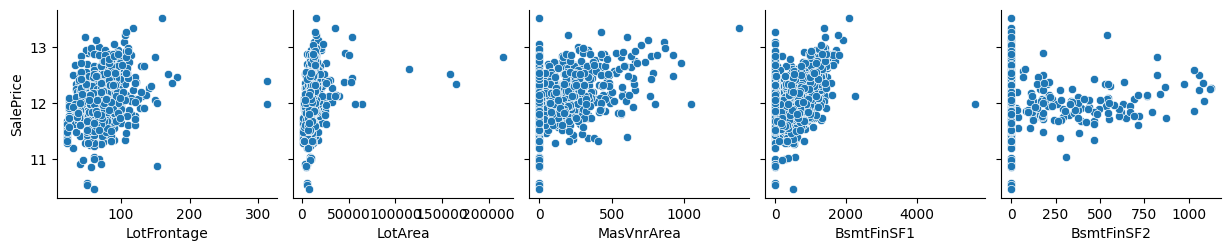

In [ ]:
# let's plot the sale price vs the numerical variables

tmp = pd.concat([X_train, y_train], axis=1)

sns.pairplot(data=tmp,
             y_vars='SalePrice',
             x_vars=['LotFrontage',
                     'LotArea',
                     'MasVnrArea',
                     'BsmtFinSF1',
                     'BsmtFinSF2', ])
plt.show()

Vidimo da sa uvećanjem vrednosti varijable raste i cena nekretnine, za većinu ovih varijabli.

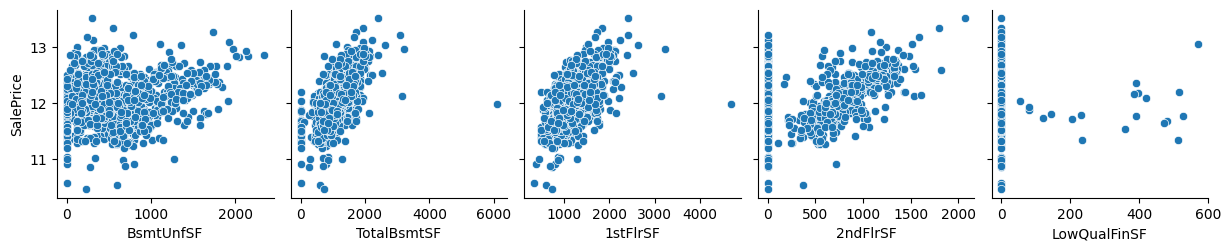

In [ ]:
sns.pairplot(data=tmp,
             y_vars=['SalePrice'],
             x_vars=['BsmtUnfSF',
                     'TotalBsmtSF',
                     '1stFlrSF',
                     '2ndFlrSF',
                     'LowQualFinSF', ])
plt.show()

Isto važi i za ove varijable.

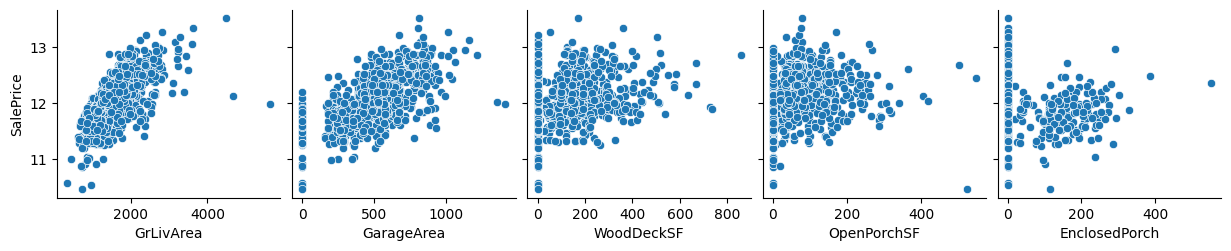

In [ ]:
sns.pairplot(data=tmp,
             y_vars=['SalePrice'],
             x_vars=['GrLivArea',
                     'GarageArea',
                     'WoodDeckSF',
                     'OpenPorchSF',
                     'EnclosedPorch', ])

plt.show()

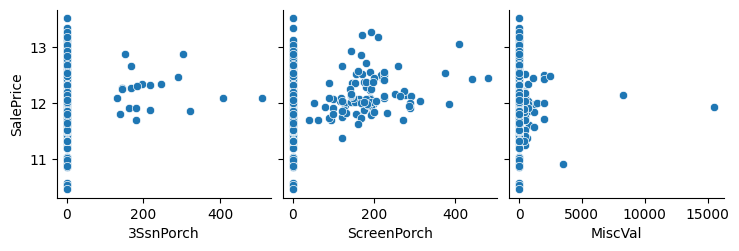

In [ ]:
sns.pairplot(data=tmp,
             y_vars=['SalePrice'],
             x_vars=['3SsnPorch',
                     'ScreenPorch',
                     'MiscVal'])

plt.show()

Za ove varijable deluje da ne postoji jasan trend.

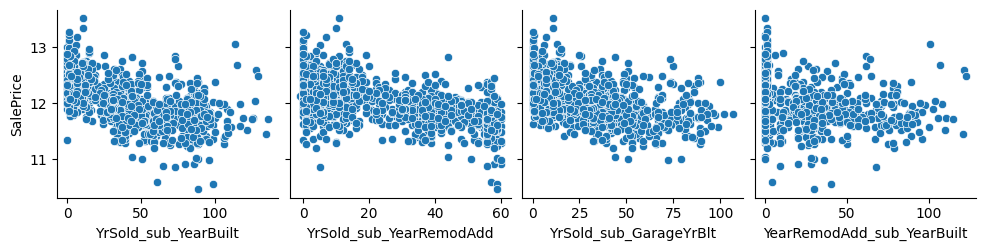

In [ ]:
# and now the time variables we created before

sns.pairplot(data=tmp,
             y_vars=['SalePrice'],
             x_vars=['YrSold_sub_YearBuilt',
                     'YrSold_sub_YearRemodAdd' ,
                     'YrSold_sub_GarageYrBlt',
                     'YearRemodAdd_sub_YearBuilt'])

plt.show()

Ove varijable su donekle obećavajuće.

Nedostajuće vrednosti:

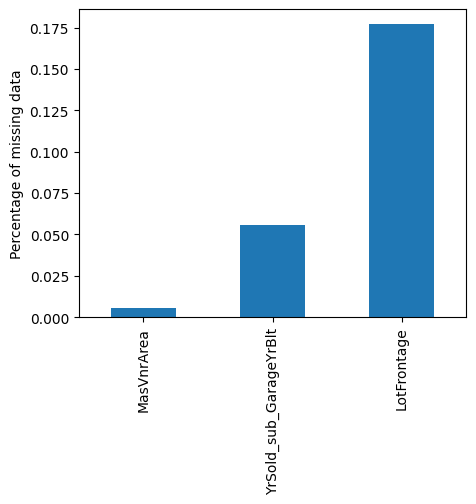

In [ ]:
# concatenate data sources
data = create_master_data(X_train, X_val, X_test, y_train, y_val, y_test)

# capture numerical variables with NA
null_num = {var: data[var].isnull().mean() for var in numerical if data[var].isnull().mean()>0}

# plot
pd.Series(null_num).sort_values().plot.bar(figsize=(5,4))
plt.ylabel('Percentage of missing data')
plt.show()

Postoji više varijabli sa nedostajućim vrednostima. Prvo ćemo dodati indikator da vrednost nedostaje, a onda ćemo *impute*-ovati nedostajuće vrednosti.

In [ ]:
vars_to_impute = [c for c in null_num.keys()]

# add the discrete variables with NA
vars_to_impute = vars_to_impute + ['GarageCars', 'BsmtFullBath', 'BsmtHalfBath']

indicator = imp.AddMissingIndicator(missing_only = False,
                                variables = vars_to_impute,
                               )

indicator.fit(X_train)

AddMissingIndicator(missing_only=False,
                    variables=['LotFrontage', 'MasVnrArea',
                               'YrSold_sub_GarageYrBlt', 'GarageCars',
                               'BsmtFullBath', 'BsmtHalfBath'])

In [ ]:
# in this attribute we find the variables for which
# the missing indicators will be added

indicator.variables_

['LotFrontage',
 'MasVnrArea',
 'YrSold_sub_GarageYrBlt',
 'GarageCars',
 'BsmtFullBath',
 'BsmtHalfBath']

In [ ]:
X_train = indicator.transform(X_train)
X_val = indicator.transform(X_val)
X_test = indicator.transform(X_test)

X_train.shape, X_val.shape, X_test.shape

((1168, 75), (146, 75), (146, 75))

Zamenićemo nedostajuće vrednosti srednjom vrednošću. Pazimo da srednja vrednost bude određena na trening skupu.

In [ ]:
# now replace NA by the median value
num_imputer = imp.MeanMedianImputer(imputation_method = 'median',
                                    variables = vars_to_impute,
                                   )

num_imputer.fit(X_train)

# the median for imputation for each numerical variable
num_imputer.imputer_dict_

{'LotFrontage': 70.0,
 'MasVnrArea': 0.0,
 'YrSold_sub_GarageYrBlt': 27.5,
 'GarageCars': 2.0,
 'BsmtFullBath': 0.0,
 'BsmtHalfBath': 0.0}

In [ ]:
X_train = num_imputer.transform(X_train)
X_val = num_imputer.transform(X_val)
X_test = num_imputer.transform(X_test)

X_train.shape, X_val.shape, X_test.shape

((1168, 75), (146, 75), (146, 75))

In [ ]:
X_train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Utilities,LandSlope,Neighborhood,Condition2,...,YrSold_sub_YearBuilt,YrSold_sub_YearRemodAdd,YrSold_sub_GarageYrBlt,YearRemodAdd_sub_YearBuilt,LotFrontage_na,MasVnrArea_na,YrSold_sub_GarageYrBlt_na,GarageCars_na,BsmtFullBath_na,BsmtHalfBath_na
254,255,2,1,70.0,8400,1,1,0,2,1,...,53,53,53.0,0,0,0,0,0,0,0
1066,1067,4,1,59.0,7837,1,1,0,5,1,...,16,15,16.0,1,0,0,0,0,0,0
638,639,1,1,67.0,8777,1,1,0,0,1,...,98,58,27.5,40,0,0,1,0,0,0
799,800,0,1,60.0,7200,1,1,0,3,1,...,70,57,68.0,13,0,0,0,0,0,0
380,381,0,1,50.0,5000,1,1,0,3,1,...,86,60,86.0,26,0,0,0,0,0,0


In [ ]:
[c for c in X_train.columns if X_train[c].isnull().sum()>0]

[]

In [ ]:
[c for c in X_test.columns if X_test[c].isnull().sum()>0]

[]

In [ ]:
[c for c in X_val.columns if X_val[c].isnull().sum()>0]

[]

### Feature engineering

In [ ]:
# create some more features

# total number of basement bathrooms
bath_bsmt = creation.MathFeatures (
    variables=['BsmtHalfBath', 'BsmtFullBath'],
    func=['sum'],
    new_variables_names=['BsmtBath_total'],
)

# total number of bathrooms
bath_ground = creation.MathFeatures (
    variables=['FullBath', 'HalfBath'],
    func=['sum'],
    new_variables_names=['Bath_total'],
)

X_train = bath_bsmt.fit_transform(X_train)
X_val = bath_bsmt.transform(X_val)
X_test = bath_bsmt.transform(X_test)

X_train = bath_ground.fit_transform(X_train)
X_val = bath_ground.transform(X_val)
X_test = bath_ground.transform(X_test)

X_train.shape, X_val.shape, X_test.shape

((1168, 77), (146, 77), (146, 77))

# Normalizacija podataka

Pazimo da prilikom normalizacije podataka koristimo samo trening podatke da odredimo neophodne parametre (srednju vrednost i standardnu devijaciju obeležja).

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit the scaler to the training data only, then transform the training data
X_train_scaled = scaler.fit_transform(X_train)

# Use the same scaler to transform the validation and test sets
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)